##LOADING AND PREPROCESSING

In [ ]:
!pip install -q pandas numpy scikit-learn Pillow tqdm matplotlib seaborn

In [ ]:
#mounting drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
#configuring paths for data
#patho = pathological and normal = non-diseased
from pathlib import Path

DRIVE_ROOT        = Path('/content/drive/MyDrive')
PATHO_DIR         = DRIVE_ROOT / 'Glenda_v1.5_classes'
NORMAL_DIR        = DRIVE_ROOT / 'no_pathology'
OUTPUT_DIR        = DRIVE_ROOT / 'glenda_splits'

FRAMES_DIR        = PATHO_DIR / 'frames'
ANNOTS_DIR        = PATHO_DIR / 'annots'
COCO_JSON         = PATHO_DIR / 'coco.json'
COLORS_TXT        = PATHO_DIR / 'colors.txt'
NORMAL_FRAMES_DIR = NORMAL_DIR / 'frames'

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

#confirming access
for p in [FRAMES_DIR, ANNOTS_DIR, COCO_JSON, NORMAL_FRAMES_DIR]:
    status = 'successfully retrieved' if p.exists() else 'missing'
    print(f"{status}  {p}")

successfully retrieved  /content/drive/MyDrive/Glenda_v1.5_classes/frames
successfully retrieved  /content/drive/MyDrive/Glenda_v1.5_classes/annots
successfully retrieved  /content/drive/MyDrive/Glenda_v1.5_classes/coco.json
successfully retrieved  /content/drive/MyDrive/no_pathology/frames


In [ ]:
#parsing coco.json (annotation format) colors.txt
import json
import numpy as np

with open(COCO_JSON) as f:
    coco = json.load(f)

categories = {c['id']: c for c in coco['categories']}
print("Categories:")
for cid, cat in categories.items():
    print(f"  [{cid}] {cat['name']}  colour={cat['color']}")

raw_colours = list(map(int, COLORS_TXT.read_text().split()))
colour_palette = [
    tuple(raw_colours[i*3:(i*3)+3])
    for i in range(len(raw_colours) // 3)
]
print("\nColour palette:")
for i, c in enumerate(colour_palette):
    label = 'background' if i == 0 else categories.get(i, {}).get('name', '?')
    print(f"  [{i}] RGB{c}  to {label}")

RGB_TO_CLASS = {rgb: idx for idx, rgb in enumerate(colour_palette)}

Categories:
  [1] 6.1.1.1_Endo-Peritoneum  colour=#be3ecc
  [2] 6.1.1.2_Endo-Ovar  colour=#5d59fe
  [3] 6.1.1.3_Endo-TIE  colour=#91d28a
  [4] 6.1.1.4_Endo-Uterus  colour=#eeec32

Colour palette:
  [0] RGB(0, 0, 0)  to background
  [1] RGB(190, 62, 204)  to 6.1.1.1_Endo-Peritoneum
  [2] RGB(93, 89, 254)  to 6.1.1.2_Endo-Ovar
  [3] RGB(145, 210, 138)  to 6.1.1.3_Endo-TIE
  [4] RGB(238, 236, 50)  to 6.1.1.4_Endo-Uterus


In [ ]:
#building pathological metadata
import re
import pandas as pd

def extract_video_id_patho(filename: str) -> str:
    # 'c_1_v_(video_7.mp4)_f_36.jpg' → 'video_7'
    m = re.search(r'\((.+?\.mp4)\)', filename)
    if m:
        return m.group(1).replace('.mp4', '')
    return 'unknown'

rows = []
for img_path in sorted(FRAMES_DIR.glob('*.jpg')):
    stem       = img_path.stem
    annot_path = ANNOTS_DIR / (stem + '.png')
    patient_id = extract_video_id_patho(img_path.name)
    rows.append({
        'image_path' : str(img_path),
        'annot_path' : str(annot_path) if annot_path.exists() else None,
        'has_annot'  : annot_path.exists(),
        'patient_id' : patient_id,
        'label'      : 1,
        'split_group': 'patho',
    })

df_patho = pd.DataFrame(rows)
print(f"Pathological images  : {len(df_patho)}")
print(f"With annotation mask : {df_patho['has_annot'].sum()}")
print(f"Unique patient IDs   : {df_patho['patient_id'].nunique()}")
df_patho.head(3)

Pathological images  : 373
With annotation mask : 373
Unique patient IDs   : 205


,image_path,annot_path,has_annot,patient_id,label,split_group
0,/content/drive/MyDrive/Glenda_v1.5_classes/fra...,/content/drive/MyDrive/Glenda_v1.5_classes/ann...,True,video_3062,1,patho
1,/content/drive/MyDrive/Glenda_v1.5_classes/fra...,/content/drive/MyDrive/Glenda_v1.5_classes/ann...,True,video_3119,1,patho
2,/content/drive/MyDrive/Glenda_v1.5_classes/fra...,/content/drive/MyDrive/Glenda_v1.5_classes/ann...,True,video_3119,1,patho


In [ ]:
#build normal metadata
def extract_video_id_normal(folder_name: str) -> str:
    # 'v_2506_s_0-95' → 'v_2506'
    m = re.match(r'(v_\d+)', folder_name)
    return m.group(1) if m else folder_name

rows_normal = []
for subdir in sorted(NORMAL_FRAMES_DIR.iterdir()):
    if not subdir.is_dir():
        continue
    patient_id = extract_video_id_normal(subdir.name)
    for img_path in sorted(subdir.glob('*.jpg')):
        rows_normal.append({
            'image_path' : str(img_path),
            'annot_path' : None,
            'has_annot'  : False,
            'patient_id' : patient_id,
            'label'      : 0,
            'split_group': 'normal',
        })

df_normal = pd.DataFrame(rows_normal)
print(f"Normal images       : {len(df_normal)}")
print(f"Unique patient IDs  : {df_normal['patient_id'].nunique()}")
df_normal.head(3)

Normal images       : 13463
Unique patient IDs  : 20


,image_path,annot_path,has_annot,patient_id,label,split_group
0,/content/drive/MyDrive/no_pathology/frames/v_2...,None,False,v_2506,0,normal
1,/content/drive/MyDrive/no_pathology/frames/v_2...,None,False,v_2506,0,normal
2,/content/drive/MyDrive/no_pathology/frames/v_2...,None,False,v_2506,0,normal


Normal       : 13463
Pathological : 373
Imbalance ratio (normal:patho) = 36.1:1
Total images   : 13836
Total patients : 225


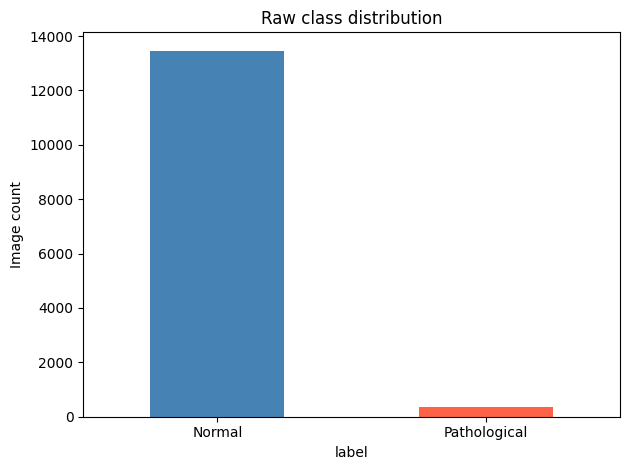

In [ ]:
#combining and inspecting imbalance
import matplotlib.pyplot as plt

df_all = pd.concat([df_patho, df_normal], ignore_index=True)

counts = df_all['label'].value_counts().rename({0: 'Normal', 1: 'Pathological'})
ratio  = counts['Normal'] / counts['Pathological']
print(f"Normal       : {counts['Normal']}")
print(f"Pathological : {counts['Pathological']}")
print(f"Imbalance ratio (normal:patho) = {ratio:.1f}:1")
print(f"Total images   : {len(df_all)}")
print(f"Total patients : {df_all['patient_id'].nunique()}")

counts.plot(kind='bar', color=['steelblue', 'tomato'], rot=0)
plt.title('Raw class distribution')
plt.ylabel('Image count')
plt.tight_layout()
plt.savefig(str(OUTPUT_DIR / 'class_distribution.png'), dpi=120)
plt.show()

In [ ]:
#creating patient-wise 5 fold splits
import pickle
from sklearn.model_selection import KFold

SEED                     = 42
N_FOLDS                  = 5
TRAIN_RATIO              = 0.80   # 80% train, 20% val within pool
NORMAL_TO_ABNORMAL_TRAIN = 2      # 2:1 normal:abnormal in training pool

np.random.seed(SEED)

patho_patients = sorted(df_patho['patient_id'].unique())
rng = np.random.RandomState(SEED)
patho_arr = np.array(patho_patients)
rng.shuffle(patho_arr)

kf = KFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
splits = []

for fold_idx, (train_idx, test_idx) in enumerate(kf.split(patho_arr)):

    test_patho_patients  = patho_arr[test_idx].tolist()
    train_patho_patients = patho_arr[train_idx].tolist()

    # TEST: pathological images from held-out patients
    test_patho_df = df_patho[df_patho['patient_id'].isin(test_patho_patients)]
    n_test_patho  = len(test_patho_df)

    # TEST: equal number of normal images → 1:1 ratio
    normal_shuffled = df_normal.sample(frac=1, random_state=SEED + fold_idx)
    test_normal_df  = normal_shuffled.iloc[:n_test_patho]
    test_normal_ids = set(test_normal_df.index)

    test_df = pd.concat([test_patho_df, test_normal_df])

    # TRAINING POOL: remaining patho + normals not in test
    pool_patho_df  = df_patho[df_patho['patient_id'].isin(train_patho_patients)]
    pool_normal_df = df_normal[~df_normal.index.isin(test_normal_ids)]

    n_normal_target = len(pool_patho_df) * NORMAL_TO_ABNORMAL_TRAIN
    n_normal_sample = min(n_normal_target, len(pool_normal_df))
    sampled_normal_df = pool_normal_df.sample(n=n_normal_sample, random_state=SEED + fold_idx)

    pool_df = pd.concat([pool_patho_df, sampled_normal_df]).sample(frac=1, random_state=SEED)

    # TRAIN / VAL split (80/20)
    n_val    = int(len(pool_df) * (1 - TRAIN_RATIO))
    val_df   = pool_df.iloc[:n_val]
    train_df = pool_df.iloc[n_val:]

    splits.append({
        'fold'                : fold_idx,
        'train'               : train_df.reset_index(drop=True),
        'val'                 : val_df.reset_index(drop=True),
        'test'                : test_df.reset_index(drop=True),
        'test_patho_patients' : test_patho_patients,
        'train_patho_patients': train_patho_patients,
    })

    print(f"Fold {fold_idx+1}  |  "
          f"Train={len(train_df)} (patho={train_df['label'].sum()}, normal={(train_df['label']==0).sum()})  |  "
          f"Val={len(val_df)}  |  "
          f"Test={len(test_df)} → patho={test_df['label'].sum()}, normal={(test_df['label']==0).sum()}")

print("\nPatient leakage check:")
for s in splits:
    overlap = set(s['test_patho_patients']) & set(s['train_patho_patients'])
    print(f"  Fold {s['fold']+1}: {overlap if overlap else 'no overlap'}")


Fold 1  |  Train=701 (patho=235, normal=466)  |  Val=175  |  Test=162 → patho=81, normal=81
Fold 2  |  Train=682 (patho=229, normal=453)  |  Val=170  |  Test=178 → patho=89, normal=89
Fold 3  |  Train=735 (patho=246, normal=489)  |  Val=183  |  Test=134 → patho=67, normal=67
Fold 4  |  Train=737 (patho=246, normal=491)  |  Val=184  |  Test=132 → patho=66, normal=66
Fold 5  |  Train=728 (patho=240, normal=488)  |  Val=181  |  Test=140 → patho=70, normal=70

Patient leakage check:
  Fold 1: no overlap
  Fold 2: no overlap
  Fold 3: no overlap
  Fold 4: no overlap
  Fold 5: no overlap


In [ ]:
#saving splits and summary
with open(OUTPUT_DIR / 'splits.pkl', 'wb') as f:
    pickle.dump(splits, f)
print(f"Saved: splits.pkl")

df_all.to_csv(OUTPUT_DIR / 'metadata.csv', index=False)
print(f"Saved: metadata.csv")

summary_rows = []
for s in splits:
    for split_name in ['train', 'val', 'test']:
        d = s[split_name]
        summary_rows.append({
            'fold'  : s['fold'] + 1,
            'split' : split_name,
            'total' : len(d),
            'patho' : int(d['label'].sum()),
            'normal': int((d['label'] == 0).sum()),
            'ratio' : round((d['label']==0).sum() / max(d['label'].sum(), 1), 2),
        })

summary_df = pd.DataFrame(summary_rows)
summary_df.to_csv(OUTPUT_DIR / 'fold_summary.csv', index=False)
print(f"Saved: fold_summary.csv")
print(summary_df.to_string(index=False))

Saved: splits.pkl
Saved: metadata.csv
Saved: fold_summary.csv
 fold split  total  patho  normal  ratio
    1 train    701    235     466   1.98
    1   val    175     57     118   2.07
    1  test    162     81      81   1.00
    2 train    682    229     453   1.98
    2   val    170     55     115   2.09
    2  test    178     89      89   1.00
    3 train    735    246     489   1.99
    3   val    183     60     123   2.05
    3  test    134     67      67   1.00
    4 train    737    246     491   2.00
    4   val    184     61     123   2.02
    4  test    132     66      66   1.00
    5 train    728    240     488   2.03
    5   val    181     63     118   1.87
    5  test    140     70      70   1.00


In [ ]:
#defining transforms (for use in later training cells)
import torchvision.transforms as T

TARGET_SIZE = (320, 320)
NORM_MEAN   = [0.5, 0.5, 0.5]
NORM_STD    = [0.5, 0.5, 0.5]

train_transforms = T.Compose([
    T.Resize(TARGET_SIZE, interpolation=T.InterpolationMode.BICUBIC),
    T.RandomHorizontalFlip(p=0.5),
    T.RandomRotation(degrees=10),
    T.ColorJitter(brightness=0.1, contrast=0.1),
    T.ToTensor(),
    T.Normalize(mean=NORM_MEAN, std=NORM_STD),
])

eval_transforms = T.Compose([
    T.Resize(TARGET_SIZE, interpolation=T.InterpolationMode.BICUBIC),
    T.ToTensor(),
    T.Normalize(mean=NORM_MEAN, std=NORM_STD),
])

print("train_transforms:", train_transforms)
print("\neval_transforms:", eval_transforms)

train_transforms: Compose(
    Resize(size=(320, 320), interpolation=bicubic, max_size=None, antialias=True)
    RandomHorizontalFlip(p=0.5)
    RandomRotation(degrees=[-10.0, 10.0], interpolation=nearest, expand=False, fill=0)
    ColorJitter(brightness=(0.9, 1.1), contrast=(0.9, 1.1), saturation=None, hue=None)
    ToTensor()
    Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
)

eval_transforms: Compose(
    Resize(size=(320, 320), interpolation=bicubic, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
)


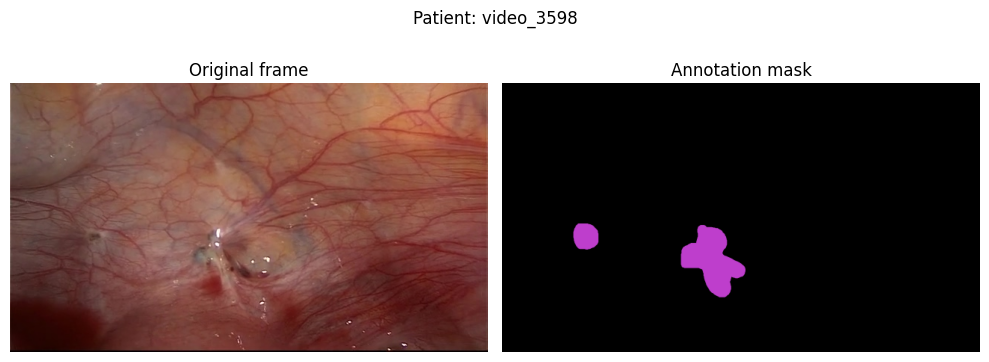

In [ ]:
#sanity-check (visualize one image and mask pair)
from PIL import Image

annotated = splits[0]['train']
annotated = annotated[annotated['has_annot'] == True]

if len(annotated) == 0:
    print("No annotated images found — check your paths.")
else:
    sample = annotated.sample(1, random_state=SEED).iloc[0]
    img  = Image.open(sample['image_path']).convert('RGB')
    mask = Image.open(sample['annot_path']).convert('RGB')

    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    axes[0].imshow(img);  axes[0].set_title('Original frame');  axes[0].axis('off')
    axes[1].imshow(mask); axes[1].set_title('Annotation mask'); axes[1].axis('off')
    plt.suptitle(f"Patient: {sample['patient_id']}")
    plt.tight_layout()
    plt.show()

In [ ]:
#for loading splits
#import pickle
#from pathlib import Path

#OUTPUT_DIR = Path('/content/drive/MyDrive/glenda_splits')

#with open(OUTPUT_DIR / 'splits.pkl', 'rb') as f:
    splits = pickle.load(f)

#fold     = splits[0]
#train_df = fold['train']   # columns: image_path, annot_path, has_annot, patient_id, label
#val_df   = fold['val']
#test_df  = fold['test']

##Training

In [ ]:
#installing dependencies
!pip install -q timm torchmetrics

In [ ]:
#Reloading splits (I usually skip this in the same session)
import pickle
import pandas as pd
import numpy as np
from pathlib import Path
import torchvision.transforms as T

OUTPUT_DIR = Path('/content/drive/MyDrive/glenda_splits')

with open(OUTPUT_DIR / 'splits.pkl', 'rb') as f:
    splits = pickle.load(f)

TARGET_SIZE = (320, 320)
NORM_MEAN   = [0.5, 0.5, 0.5]
NORM_STD    = [0.5, 0.5, 0.5]

train_transforms = T.Compose([
    T.Resize(TARGET_SIZE, interpolation=T.InterpolationMode.BICUBIC),
    T.RandomHorizontalFlip(p=0.5),
    T.RandomRotation(degrees=10),
    T.ColorJitter(brightness=0.1, contrast=0.1),
    T.ToTensor(),
    T.Normalize(mean=NORM_MEAN, std=NORM_STD),
])

eval_transforms = T.Compose([
    T.Resize(TARGET_SIZE, interpolation=T.InterpolationMode.BICUBIC),
    T.ToTensor(),
    T.Normalize(mean=NORM_MEAN, std=NORM_STD),
])

print(f"Loaded {len(splits)} folds")
print(f"Fold 1 — Train: {len(splits[0]['train'])}  Val: {len(splits[0]['val'])}  Test: {len(splits[0]['test'])}")


Loaded 5 folds
Fold 1 — Train: 701  Val: 175  Test: 162


In [ ]:
#dataset class
import torch
from torch.utils.data import Dataset
from PIL import Image

class GlendaDataset(Dataset):
    def __init__(self, df, transform=None):
        self.df        = df.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row   = self.df.iloc[idx]
        image = Image.open(row['image_path']).convert('RGB')
        label = int(row['label'])
        if self.transform:
            image = self.transform(image)
        return image, label

In [ ]:
#modelfactory
import timm
import torch.nn as nn

def build_model(arch: str, num_classes: int = 2, pretrained: bool = True):
    """
    arch options:
      'edgenext_small'  — EdgeNeXt_Small (best in paper)
      'resnet50'        — ResNet50 (a1_in1k weights)
    """
    if arch == 'edgenext_small':
        model = timm.create_model(
            'edgenext_small',
            pretrained=pretrained,
            num_classes=num_classes,
        )
    elif arch == 'resnet50':
        model = timm.create_model(
            'resnet50.a1_in1k',
            pretrained=pretrained,
            num_classes=num_classes,
        )
    elif arch == 'efficientformerv2_s0':
      model = timm.create_model(
          'efficientformerv2_s0',
          pretrained=pretrained,
          num_classes=num_classes,
        )
    else:
        raise ValueError(f"Unknown arch: {arch}")
    return model

# Quick test
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {device}")
m = build_model('edgenext_small')
x = torch.randn(2, 3, 320, 320)
print(f"EdgeNeXt_Small output shape: {m(x).shape}")
del m

Device: cuda
EdgeNeXt_Small output shape: torch.Size([2, 2])


In [ ]:
#training and evaluation functions
from torch.utils.data import DataLoader
from torchmetrics.classification import (
    BinaryAccuracy, BinaryAUROC, BinaryF1Score,
    BinaryPrecision, BinaryRecall, BinaryConfusionMatrix
)
import torch.nn.functional as F

BATCH_SIZE = 32
NUM_EPOCHS = 30
LR         = 1e-4
PATIENCE   = 7


def train_one_epoch(model, loader, optimizer, criterion, device, fold, epoch):
    model.train()
    total_loss, correct, total = 0.0, 0, 0
    for batch_idx, (imgs, labels) in enumerate(loader):
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer.zero_grad()
        logits = model(imgs)
        loss   = criterion(logits, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * imgs.size(0)
        correct    += (logits.argmax(1) == labels).sum().item()
        total      += imgs.size(0)
        # Print batch progress every 10 batches
        if (batch_idx + 1) % 10 == 0 or (batch_idx + 1) == len(loader):
            print(f"\r    Fold {fold} | Epoch {epoch:02d} | Batch {batch_idx+1}/{len(loader)} "
                  f"| loss={total_loss/total:.4f}", end='', flush=True)
    print()  # newline after epoch
    return total_loss / total, correct / total


@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    all_probs, all_labels = [], []
    for imgs, labels in loader:
        imgs, labels = imgs.to(device), labels.to(device)
        logits = model(imgs)
        loss   = criterion(logits, labels)
        probs  = F.softmax(logits, dim=1)[:, 1]
        total_loss += loss.item() * imgs.size(0)
        correct    += (logits.argmax(1) == labels).sum().item()
        total      += imgs.size(0)
        all_probs.append(probs.cpu())
        all_labels.append(labels.cpu())
    all_probs  = torch.cat(all_probs)
    all_labels = torch.cat(all_labels)
    return total_loss / total, correct / total, all_probs, all_labels


def compute_metrics(probs, labels):
    preds = (probs >= 0.5).long()
    acc   = BinaryAccuracy()(preds, labels).item()
    auc   = BinaryAUROC()(probs, labels).item()
    f1    = BinaryF1Score()(preds, labels).item()
    prec  = BinaryPrecision()(preds, labels).item()
    rec   = BinaryRecall()(preds, labels).item()
    cm    = BinaryConfusionMatrix()(preds, labels).numpy()
    return {'acc': acc, 'auc': auc, 'f1': f1, 'precision': prec, 'recall': rec, 'cm': cm}

In [ ]:
#full 5-fold training loop
#This saves the best checkpoint per fold (by val AUC) and logs all metrics.
import copy
import json
import matplotlib.pyplot as plt

def run_experiment(arch: str, splits: list, output_dir: Path, device):
    arch_dir = output_dir / arch
    arch_dir.mkdir(parents=True, exist_ok=True)

    all_fold_metrics = []

    for fold_idx, fold in enumerate(splits):
        print(f"\n{'='*60}", flush=True)
        print(f"  {arch.upper()}  —  Fold {fold_idx+1} / {len(splits)}", flush=True)
        print(f"{'='*60}", flush=True)

        train_ds = GlendaDataset(fold['train'], transform=train_transforms)
        val_ds   = GlendaDataset(fold['val'],   transform=eval_transforms)
        test_ds  = GlendaDataset(fold['test'],  transform=eval_transforms)

        train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
                                  num_workers=2, pin_memory=False)
        val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False,
                                  num_workers=2, pin_memory=False)
        test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False,
                                  num_workers=2, pin_memory=False)

        model     = build_model(arch).to(device)
        criterion = nn.CrossEntropyLoss()
        optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=NUM_EPOCHS)

        best_val_auc   = 0.0
        best_weights   = None
        patience_count = 0
        history        = {'train_loss': [], 'val_loss': [], 'val_auc': [], 'val_acc': []}

        for epoch in range(1, NUM_EPOCHS + 1):
            tr_loss, tr_acc = train_one_epoch(
                model, train_loader, optimizer, criterion, device,
                fold=fold_idx+1, epoch=epoch
            )
            vl_loss, vl_acc, vl_probs, vl_labels = evaluate(model, val_loader, criterion, device)
            vl_metrics = compute_metrics(vl_probs, vl_labels)
            scheduler.step()

            history['train_loss'].append(tr_loss)
            history['val_loss'].append(vl_loss)
            history['val_auc'].append(vl_metrics['auc'])
            history['val_acc'].append(vl_metrics['acc'])

            improved = vl_metrics['auc'] > best_val_auc
            if improved:
                best_val_auc   = vl_metrics['auc']
                best_weights   = copy.deepcopy(model.state_dict())
                patience_count = 0
                tag = '  ← best'
            else:
                patience_count += 1
                tag = f'  (no improve {patience_count}/{PATIENCE})'

            print(
                f"  Epoch {epoch:02d}/{NUM_EPOCHS} | "
                f"tr_loss={tr_loss:.4f}  tr_acc={tr_acc:.4f} | "
                f"vl_loss={vl_loss:.4f}  vl_acc={vl_metrics['acc']:.4f}  "
                f"vl_auc={vl_metrics['auc']:.4f}  vl_f1={vl_metrics['f1']:.4f}"
                f"{tag}",
                flush=True
            )

            if patience_count >= PATIENCE:
                print(f"  Early stopping at epoch {epoch}", flush=True)
                break

        ckpt_path = arch_dir / f'fold{fold_idx+1}_best.pt'
        torch.save(best_weights, ckpt_path)
        print(f"\n  Saved checkpoint: {ckpt_path}", flush=True)

        model.load_state_dict(best_weights)
        _, _, test_probs, test_labels = evaluate(model, test_loader, criterion, device)
        test_metrics = compute_metrics(test_probs, test_labels)

        print(f"\n  TEST RESULTS — Fold {fold_idx+1}", flush=True)
        print(f"    Accuracy  : {test_metrics['acc']:.4f}", flush=True)
        print(f"    AUC       : {test_metrics['auc']:.4f}", flush=True)
        print(f"    F1        : {test_metrics['f1']:.4f}", flush=True)
        print(f"    Precision : {test_metrics['precision']:.4f}", flush=True)
        print(f"    Recall    : {test_metrics['recall']:.4f}", flush=True)
        print(f"    Confusion matrix:\n{test_metrics['cm']}", flush=True)

        all_fold_metrics.append(test_metrics)

        fig, axes = plt.subplots(1, 2, figsize=(12, 4))
        axes[0].plot(history['train_loss'], label='Train loss')
        axes[0].plot(history['val_loss'],   label='Val loss')
        axes[0].set_title(f'{arch} Fold {fold_idx+1} — Loss')
        axes[0].legend()
        axes[1].plot(history['val_auc'], label='Val AUC')
        axes[1].plot(history['val_acc'], label='Val Acc')
        axes[1].set_title(f'{arch} Fold {fold_idx+1} — Val metrics')
        axes[1].legend()
        plt.tight_layout()
        plt.savefig(str(arch_dir / f'fold{fold_idx+1}_curves.png'), dpi=100)
        plt.show()

    print(f"\n{'='*60}", flush=True)
    print(f"  {arch.upper()}  —  5-FOLD SUMMARY", flush=True)
    print(f"{'='*60}", flush=True)
    for metric in ['acc', 'auc', 'f1', 'precision', 'recall']:
        vals = [m[metric] for m in all_fold_metrics]
        print(f"  {metric:12s}: {np.mean(vals):.4f} ± {np.std(vals):.4f}", flush=True)

    summary = {
        metric: {
            'mean'    : float(np.mean([m[metric] for m in all_fold_metrics])),
            'std'     : float(np.std([m[metric] for m in all_fold_metrics])),
            'per_fold': [float(m[metric]) for m in all_fold_metrics],
        }
        for metric in ['acc', 'auc', 'f1', 'precision', 'recall']
    }
    with open(arch_dir / 'summary.json', 'w') as f:
        json.dump(summary, f, indent=2)
    print(f"\n  Saved summary: {arch_dir / 'summary.json'}", flush=True)

    return all_fold_metrics


  EDGENEXT_SMALL  —  Fold 1 / 5
    Fold 1 | Epoch 01 | Batch 22/22 | loss=0.4656
  Epoch 01/30 | tr_loss=0.4656  tr_acc=0.7832 | vl_loss=0.2749  vl_acc=0.9257  vl_auc=0.9829  vl_f1=0.8713  ← best
    Fold 1 | Epoch 02 | Batch 22/22 | loss=0.2295
  Epoch 02/30 | tr_loss=0.2295  tr_acc=0.9258 | vl_loss=0.2105  vl_acc=0.9143  vl_auc=0.9891  vl_f1=0.8819  ← best
    Fold 1 | Epoch 03 | Batch 22/22 | loss=0.1593
  Epoch 03/30 | tr_loss=0.1593  tr_acc=0.9486 | vl_loss=0.1071  vl_acc=0.9771  vl_auc=0.9918  vl_f1=0.9655  ← best
    Fold 1 | Epoch 04 | Batch 22/22 | loss=0.0894
  Epoch 04/30 | tr_loss=0.0894  tr_acc=0.9743 | vl_loss=0.0822  vl_acc=0.9829  vl_auc=0.9938  vl_f1=0.9735  ← best
    Fold 1 | Epoch 05 | Batch 22/22 | loss=0.0444
  Epoch 05/30 | tr_loss=0.0444  tr_acc=0.9886 | vl_loss=0.0938  vl_acc=0.9714  vl_auc=0.9894  vl_f1=0.9541  (no improve 1/7)
    Fold 1 | Epoch 06 | Batch 22/22 | loss=0.0256
  Epoch 06/30 | tr_loss=0.0256  tr_acc=0.9929 | vl_loss=0.0760  vl_acc=0.9829  vl_

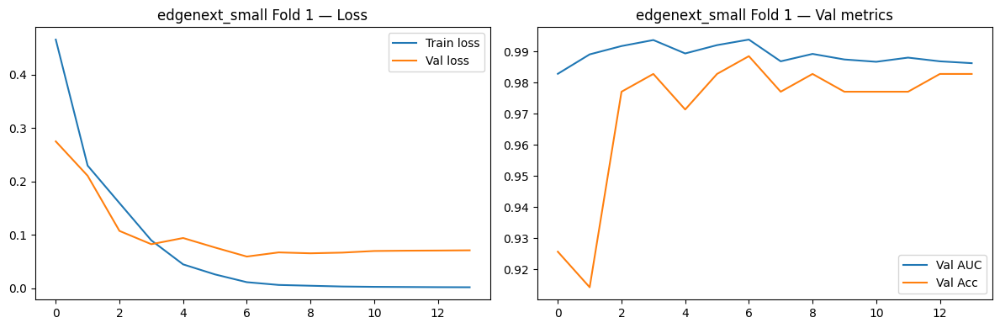


  EDGENEXT_SMALL  —  Fold 2 / 5
    Fold 2 | Epoch 01 | Batch 22/22 | loss=0.5396
  Epoch 01/30 | tr_loss=0.5396  tr_acc=0.7302 | vl_loss=0.3686  vl_acc=0.9118  vl_auc=0.9693  vl_f1=0.8515  ← best
    Fold 2 | Epoch 02 | Batch 22/22 | loss=0.2468
  Epoch 02/30 | tr_loss=0.2468  tr_acc=0.9150 | vl_loss=0.1745  vl_acc=0.9471  vl_auc=0.9747  vl_f1=0.9126  ← best
    Fold 2 | Epoch 03 | Batch 22/22 | loss=0.1108
  Epoch 03/30 | tr_loss=0.1108  tr_acc=0.9663 | vl_loss=0.1283  vl_acc=0.9647  vl_auc=0.9829  vl_f1=0.9434  ← best
    Fold 2 | Epoch 04 | Batch 22/22 | loss=0.0566
  Epoch 04/30 | tr_loss=0.0566  tr_acc=0.9824 | vl_loss=0.1070  vl_acc=0.9706  vl_auc=0.9929  vl_f1=0.9541  ← best
    Fold 2 | Epoch 05 | Batch 22/22 | loss=0.0307
  Epoch 05/30 | tr_loss=0.0307  tr_acc=0.9927 | vl_loss=0.1008  vl_acc=0.9706  vl_auc=0.9942  vl_f1=0.9524  ← best
    Fold 2 | Epoch 06 | Batch 22/22 | loss=0.0152
  Epoch 06/30 | tr_loss=0.0152  tr_acc=0.9971 | vl_loss=0.2194  vl_acc=0.9235  vl_auc=0.9867

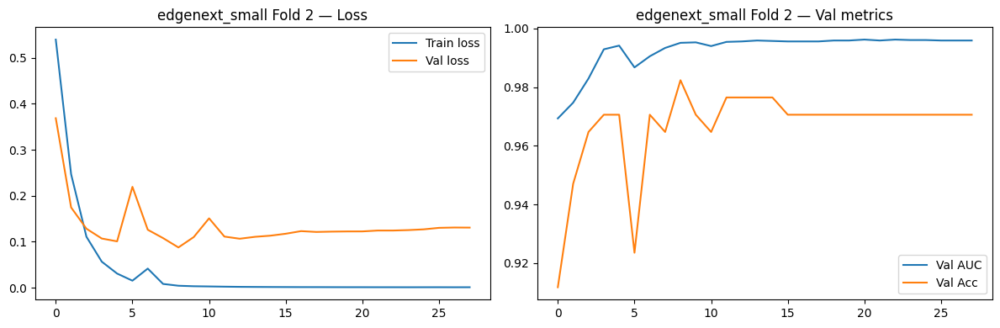


  EDGENEXT_SMALL  —  Fold 3 / 5
    Fold 3 | Epoch 01 | Batch 23/23 | loss=0.5540
  Epoch 01/30 | tr_loss=0.5540  tr_acc=0.7347 | vl_loss=0.3780  vl_acc=0.9235  vl_auc=0.9730  vl_f1=0.8704  ← best
    Fold 3 | Epoch 02 | Batch 23/23 | loss=0.2500
  Epoch 02/30 | tr_loss=0.2500  tr_acc=0.9238 | vl_loss=0.1373  vl_acc=0.9617  vl_auc=0.9886  vl_f1=0.9391  ← best
    Fold 3 | Epoch 03 | Batch 23/23 | loss=0.1122
  Epoch 03/30 | tr_loss=0.1122  tr_acc=0.9565 | vl_loss=0.0917  vl_acc=0.9672  vl_auc=0.9939  vl_f1=0.9483  ← best
    Fold 3 | Epoch 04 | Batch 23/23 | loss=0.0499
  Epoch 04/30 | tr_loss=0.0499  tr_acc=0.9864 | vl_loss=0.1040  vl_acc=0.9672  vl_auc=0.9917  vl_f1=0.9474  (no improve 1/7)
    Fold 3 | Epoch 05 | Batch 23/23 | loss=0.0234
  Epoch 05/30 | tr_loss=0.0234  tr_acc=0.9959 | vl_loss=0.0941  vl_acc=0.9727  vl_auc=0.9944  vl_f1=0.9565  ← best
    Fold 3 | Epoch 06 | Batch 23/23 | loss=0.0210
  Epoch 06/30 | tr_loss=0.0210  tr_acc=0.9959 | vl_loss=0.1170  vl_acc=0.9454  vl_

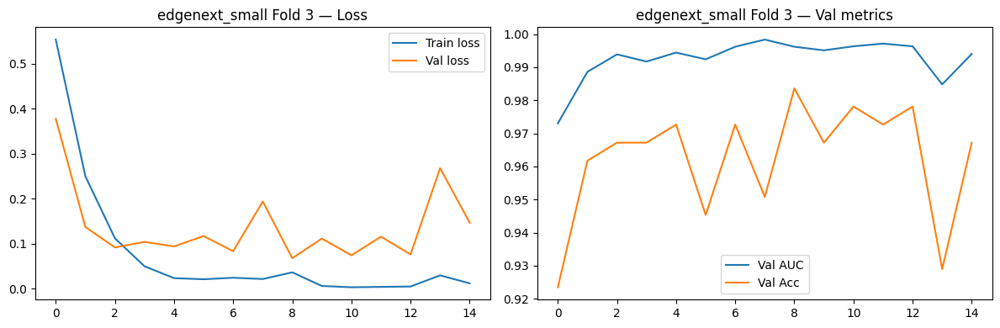


  EDGENEXT_SMALL  —  Fold 4 / 5
    Fold 4 | Epoch 01 | Batch 24/24 | loss=0.5145
  Epoch 01/30 | tr_loss=0.5145  tr_acc=0.7368 | vl_loss=0.3156  vl_acc=0.9130  vl_auc=0.9656  vl_f1=0.8689  ← best
    Fold 4 | Epoch 02 | Batch 24/24 | loss=0.2573
  Epoch 02/30 | tr_loss=0.2573  tr_acc=0.8955 | vl_loss=0.1964  vl_acc=0.9402  vl_auc=0.9855  vl_f1=0.9106  ← best
    Fold 4 | Epoch 03 | Batch 24/24 | loss=0.1470
  Epoch 03/30 | tr_loss=0.1470  tr_acc=0.9593 | vl_loss=0.1297  vl_acc=0.9674  vl_auc=0.9913  vl_f1=0.9492  ← best
    Fold 4 | Epoch 04 | Batch 24/24 | loss=0.0674
  Epoch 04/30 | tr_loss=0.0674  tr_acc=0.9878 | vl_loss=0.1289  vl_acc=0.9348  vl_auc=0.9925  vl_f1=0.9062  ← best
    Fold 4 | Epoch 05 | Batch 24/24 | loss=0.0562
  Epoch 05/30 | tr_loss=0.0562  tr_acc=0.9851 | vl_loss=0.0752  vl_acc=0.9728  vl_auc=0.9968  vl_f1=0.9580  ← best
    Fold 4 | Epoch 06 | Batch 24/24 | loss=0.0267
  Epoch 06/30 | tr_loss=0.0267  tr_acc=0.9959 | vl_loss=0.1077  vl_acc=0.9728  vl_auc=0.9960

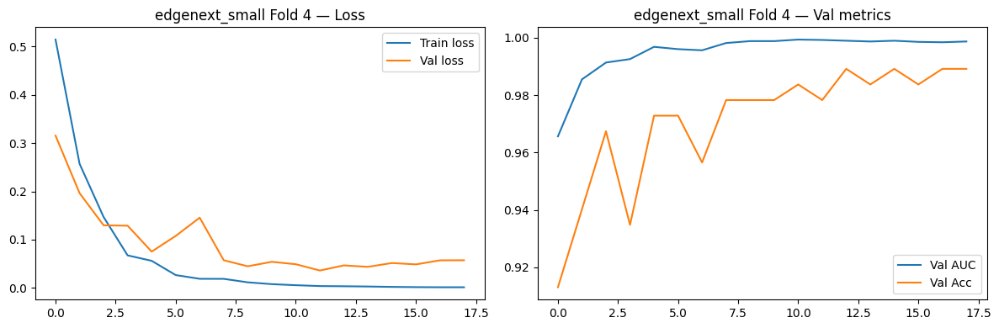


  EDGENEXT_SMALL  —  Fold 5 / 5
    Fold 5 | Epoch 01 | Batch 23/23 | loss=0.5291
  Epoch 01/30 | tr_loss=0.5291  tr_acc=0.7280 | vl_loss=0.3879  vl_acc=0.8232  vl_auc=0.9605  vl_f1=0.6596  ← best
    Fold 5 | Epoch 02 | Batch 23/23 | loss=0.2375
  Epoch 02/30 | tr_loss=0.2375  tr_acc=0.9286 | vl_loss=0.3031  vl_acc=0.9006  vl_auc=0.9794  vl_f1=0.8333  ← best
    Fold 5 | Epoch 03 | Batch 23/23 | loss=0.1395
  Epoch 03/30 | tr_loss=0.1395  tr_acc=0.9533 | vl_loss=0.1998  vl_acc=0.9282  vl_auc=0.9891  vl_f1=0.8850  ← best
    Fold 5 | Epoch 04 | Batch 23/23 | loss=0.0634
  Epoch 04/30 | tr_loss=0.0634  tr_acc=0.9835 | vl_loss=0.1139  vl_acc=0.9503  vl_auc=0.9934  vl_f1=0.9268  ← best
    Fold 5 | Epoch 05 | Batch 23/23 | loss=0.0589
  Epoch 05/30 | tr_loss=0.0589  tr_acc=0.9808 | vl_loss=0.1650  vl_acc=0.9282  vl_auc=0.9957  vl_f1=0.8850  ← best
    Fold 5 | Epoch 06 | Batch 23/23 | loss=0.0423
  Epoch 06/30 | tr_loss=0.0423  tr_acc=0.9876 | vl_loss=0.0800  vl_acc=0.9724  vl_auc=0.9973

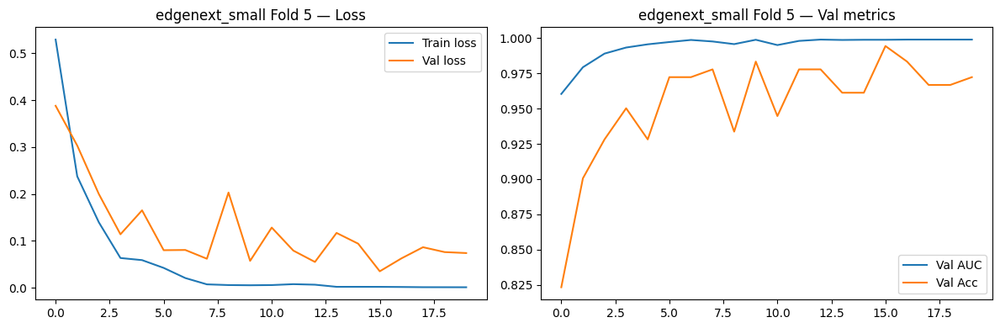


  EDGENEXT_SMALL  —  5-FOLD SUMMARY
  acc         : 0.9496 ± 0.0280
  auc         : 0.9952 ± 0.0039
  f1          : 0.9462 ± 0.0324
  precision   : 0.9944 ± 0.0069
  recall      : 0.9045 ± 0.0585

  Saved summary: /content/drive/MyDrive/glenda_splits/edgenext_small/summary.json


In [ ]:
#Running EdgeNeXt_Small
edgenext_metrics = run_experiment(
    arch       = 'edgenext_small',
    splits     = splits,
    output_dir = OUTPUT_DIR,
    device     = device,
)

In [ ]:
#confusion matrix
import torch

def confusion_matrix_binary(probs, labels, threshold=0.5):
    """
    Returns: TN, FP, FN, TP + matrix
    """
    preds = (probs >= threshold).long()

    tn = ((preds == 0) & (labels == 0)).sum().item()
    fp = ((preds == 1) & (labels == 0)).sum().item()
    fn = ((preds == 0) & (labels == 1)).sum().item()
    tp = ((preds == 1) & (labels == 1)).sum().item()

    cm = torch.tensor([[tn, fp],
                       [fn, tp]])

    return tn, fp, fn, tp, cm

In [ ]:
#class breakdown for edgenext
import torch
import numpy as np
from torch.utils.data import DataLoader

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
criterion = nn.CrossEntropyLoss()

def quick_eval_from_ckpt(arch, splits, fold_idx):
    fold = splits[fold_idx]

    test_ds = GlendaDataset(fold['test'], transform=eval_transforms)
    test_loader = DataLoader(test_ds, batch_size=32, shuffle=False)

    model = build_model(arch).to(device)

    ckpt_path = OUTPUT_DIR / arch / f"fold{fold_idx+1}_best.pt"
    model.load_state_dict(torch.load(ckpt_path, map_location=device))

    model.eval()

    all_probs, all_labels = [], []

    with torch.no_grad():
        for imgs, labels in test_loader:
            imgs = imgs.to(device)
            logits = model(imgs)
            probs = torch.softmax(logits, dim=1)[:, 1]

            all_probs.append(probs.cpu())
            all_labels.append(labels)

    probs = torch.cat(all_probs)
    labels = torch.cat(all_labels)

    return probs, labels

In [ ]:
#class breakdown function
def class_breakdown(probs, labels):
    preds = (probs >= 0.5).long()

    tn = ((preds == 0) & (labels == 0)).sum().item()
    tp = ((preds == 1) & (labels == 1)).sum().item()
    fp = ((preds == 1) & (labels == 0)).sum().item()
    fn = ((preds == 0) & (labels == 1)).sum().item()

    normal_acc = tn / (tn + fp + 1e-8)
    path_acc   = tp / (tp + fn + 1e-8)

    return tn, fp, fn, tp, normal_acc, path_acc

In [ ]:
all_tn = all_fp = all_fn = all_tp = 0

for i in range(5):
    probs, labels = quick_eval_from_ckpt('edgenext_small', splits, i)

    tn, fp, fn, tp, n_acc, p_acc = class_breakdown(probs, labels)

    print(f"\nFOLD {i+1}")
    print(f"Normal accuracy       : {n_acc:.4f}")
    print(f"Pathological accuracy : {p_acc:.4f}")
    print(f"TP={tp} FP={fp} FN={fn} TN={tn}")

    all_tn += tn
    all_fp += fp
    all_fn += fn
    all_tp += tp

print("\nOVERALL")
print(f"Normal accuracy       : {all_tn/(all_tn+all_fp):.4f}")
print(f"Pathological accuracy : {all_tp/(all_tp+all_fn):.4f}")


FOLD 1
Normal accuracy       : 1.0000
Pathological accuracy : 0.9383
TP=76 FP=0 FN=5 TN=81

FOLD 2
Normal accuracy       : 0.9888
Pathological accuracy : 0.9101
TP=81 FP=1 FN=8 TN=88

FOLD 3
Normal accuracy       : 1.0000
Pathological accuracy : 0.7910
TP=53 FP=0 FN=14 TN=67

FOLD 4
Normal accuracy       : 0.9848
Pathological accuracy : 0.9545
TP=63 FP=1 FN=3 TN=65

FOLD 5
Normal accuracy       : 1.0000
Pathological accuracy : 0.9286
TP=65 FP=0 FN=5 TN=70

OVERALL
Normal accuracy       : 0.9946
Pathological accuracy : 0.9062



  RESNET50  —  Fold 1 / 5


model.safetensors:   0%|          | 0.00/102M [00:00<?, ?B/s]

    Fold 1 | Epoch 01 | Batch 22/22 | loss=0.6523
  Epoch 01/30 | tr_loss=0.6523  tr_acc=0.6605 | vl_loss=0.6445  vl_acc=0.6743  vl_auc=0.5737  vl_f1=0.0000  ← best
    Fold 1 | Epoch 02 | Batch 22/22 | loss=0.6136
  Epoch 02/30 | tr_loss=0.6136  tr_acc=0.6648 | vl_loss=0.5979  vl_acc=0.6743  vl_auc=0.8271  vl_f1=0.0000  ← best
    Fold 1 | Epoch 03 | Batch 22/22 | loss=0.5783
  Epoch 03/30 | tr_loss=0.5783  tr_acc=0.6648 | vl_loss=0.5640  vl_acc=0.6743  vl_auc=0.8702  vl_f1=0.0000  ← best
    Fold 1 | Epoch 04 | Batch 22/22 | loss=0.5356
  Epoch 04/30 | tr_loss=0.5356  tr_acc=0.6648 | vl_loss=0.5096  vl_acc=0.6743  vl_auc=0.9420  vl_f1=0.0000  ← best
    Fold 1 | Epoch 05 | Batch 22/22 | loss=0.4750
  Epoch 05/30 | tr_loss=0.4750  tr_acc=0.6733 | vl_loss=0.4468  vl_acc=0.6857  vl_auc=0.9548  vl_f1=0.0678  ← best
    Fold 1 | Epoch 06 | Batch 22/22 | loss=0.4212
  Epoch 06/30 | tr_loss=0.4212  tr_acc=0.7461 | vl_loss=0.4012  vl_acc=0.7486  vl_auc=0.9654  vl_f1=0.3714  ← best
    Fold 1

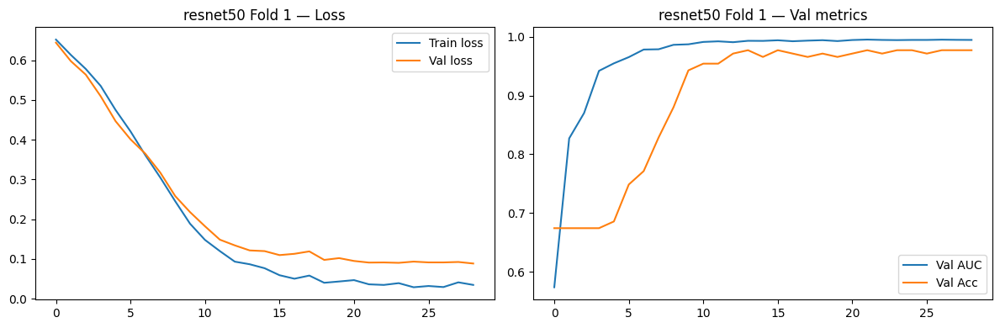


  RESNET50  —  Fold 2 / 5
    Fold 2 | Epoch 01 | Batch 22/22 | loss=0.6605
  Epoch 01/30 | tr_loss=0.6605  tr_acc=0.6481 | vl_loss=0.6457  vl_acc=0.6765  vl_auc=0.6395  vl_f1=0.0000  ← best
    Fold 2 | Epoch 02 | Batch 22/22 | loss=0.6132
  Epoch 02/30 | tr_loss=0.6132  tr_acc=0.6642 | vl_loss=0.5936  vl_acc=0.6765  vl_auc=0.8030  vl_f1=0.0000  ← best
    Fold 2 | Epoch 03 | Batch 22/22 | loss=0.5784
  Epoch 03/30 | tr_loss=0.5784  tr_acc=0.6642 | vl_loss=0.5451  vl_acc=0.6765  vl_auc=0.9017  vl_f1=0.0000  ← best
    Fold 2 | Epoch 04 | Batch 22/22 | loss=0.5291
  Epoch 04/30 | tr_loss=0.5291  tr_acc=0.6642 | vl_loss=0.4941  vl_acc=0.6765  vl_auc=0.9317  vl_f1=0.0000  ← best
    Fold 2 | Epoch 05 | Batch 22/22 | loss=0.4739
  Epoch 05/30 | tr_loss=0.4739  tr_acc=0.6716 | vl_loss=0.4458  vl_acc=0.7000  vl_auc=0.9472  vl_f1=0.1356  ← best
    Fold 2 | Epoch 06 | Batch 22/22 | loss=0.4267
  Epoch 06/30 | tr_loss=0.4267  tr_acc=0.7287 | vl_loss=0.4152  vl_acc=0.7176  vl_auc=0.9556  vl_f

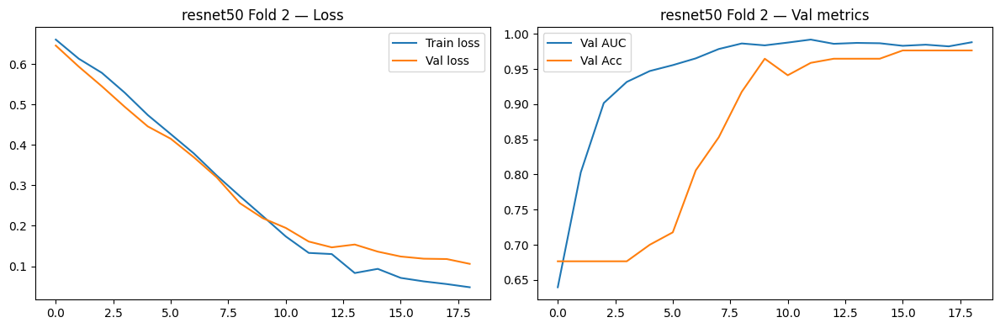


  RESNET50  —  Fold 3 / 5
    Fold 3 | Epoch 01 | Batch 23/23 | loss=0.6590
  Epoch 01/30 | tr_loss=0.6590  tr_acc=0.6422 | vl_loss=0.6424  vl_acc=0.6721  vl_auc=0.5378  vl_f1=0.0000  ← best
    Fold 3 | Epoch 02 | Batch 23/23 | loss=0.6095
  Epoch 02/30 | tr_loss=0.6095  tr_acc=0.6653 | vl_loss=0.5976  vl_acc=0.6721  vl_auc=0.7883  vl_f1=0.0000  ← best
    Fold 3 | Epoch 03 | Batch 23/23 | loss=0.5707
  Epoch 03/30 | tr_loss=0.5707  tr_acc=0.6653 | vl_loss=0.5482  vl_acc=0.6721  vl_auc=0.8958  vl_f1=0.0000  ← best
    Fold 3 | Epoch 04 | Batch 23/23 | loss=0.5224
  Epoch 04/30 | tr_loss=0.5224  tr_acc=0.6653 | vl_loss=0.5036  vl_acc=0.6721  vl_auc=0.9354  vl_f1=0.0000  ← best
    Fold 3 | Epoch 05 | Batch 23/23 | loss=0.4647
  Epoch 05/30 | tr_loss=0.4647  tr_acc=0.6748 | vl_loss=0.4574  vl_acc=0.6721  vl_auc=0.9535  vl_f1=0.0000  ← best
    Fold 3 | Epoch 06 | Batch 23/23 | loss=0.4011
  Epoch 06/30 | tr_loss=0.4011  tr_acc=0.7660 | vl_loss=0.4172  vl_acc=0.6940  vl_auc=0.9669  vl_f

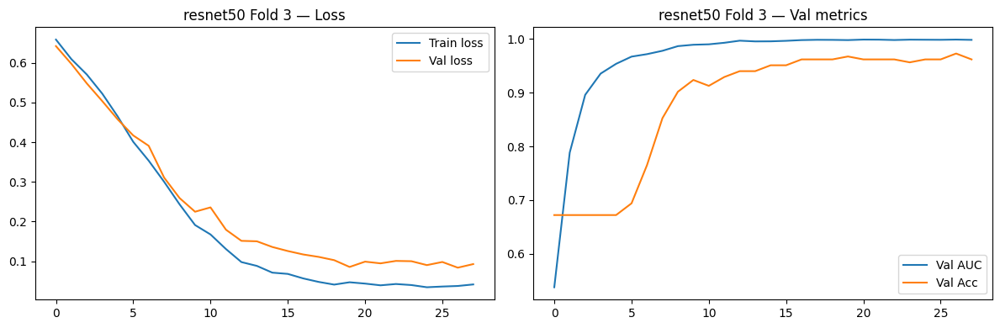


  RESNET50  —  Fold 4 / 5
    Fold 4 | Epoch 01 | Batch 24/24 | loss=0.6632
  Epoch 01/30 | tr_loss=0.6632  tr_acc=0.6282 | vl_loss=0.6546  vl_acc=0.6685  vl_auc=0.5442  vl_f1=0.0000  ← best
    Fold 4 | Epoch 02 | Batch 24/24 | loss=0.6034
  Epoch 02/30 | tr_loss=0.6034  tr_acc=0.6662 | vl_loss=0.5875  vl_acc=0.6685  vl_auc=0.7922  vl_f1=0.0000  ← best
    Fold 4 | Epoch 03 | Batch 24/24 | loss=0.5576
  Epoch 03/30 | tr_loss=0.5576  tr_acc=0.6662 | vl_loss=0.5459  vl_acc=0.6685  vl_auc=0.8631  vl_f1=0.0000  ← best
    Fold 4 | Epoch 04 | Batch 24/24 | loss=0.5085
  Epoch 04/30 | tr_loss=0.5085  tr_acc=0.6703 | vl_loss=0.5045  vl_acc=0.6685  vl_auc=0.9122  vl_f1=0.0000  ← best
    Fold 4 | Epoch 05 | Batch 24/24 | loss=0.4661
  Epoch 05/30 | tr_loss=0.4661  tr_acc=0.6906 | vl_loss=0.4536  vl_acc=0.7174  vl_auc=0.9240  vl_f1=0.2571  ← best
    Fold 4 | Epoch 06 | Batch 24/24 | loss=0.4262
  Epoch 06/30 | tr_loss=0.4262  tr_acc=0.7449 | vl_loss=0.4169  vl_acc=0.7717  vl_auc=0.9435  vl_f

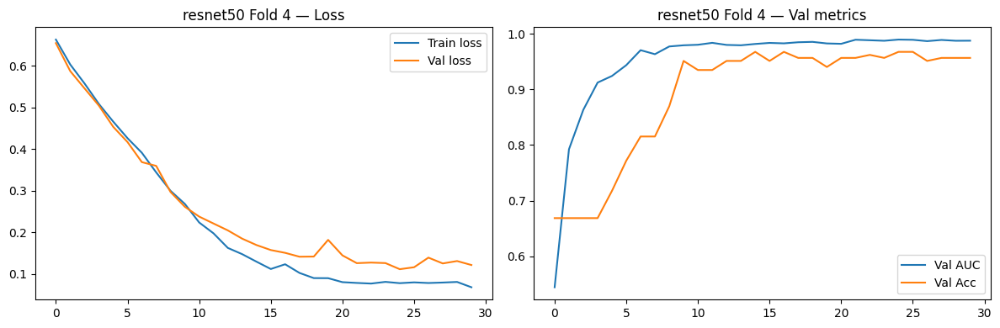


  RESNET50  —  Fold 5 / 5
    Fold 5 | Epoch 01 | Batch 23/23 | loss=0.6567
  Epoch 01/30 | tr_loss=0.6567  tr_acc=0.6648 | vl_loss=0.6529  vl_acc=0.6519  vl_auc=0.5529  vl_f1=0.0000  ← best
    Fold 5 | Epoch 02 | Batch 23/23 | loss=0.6073
  Epoch 02/30 | tr_loss=0.6073  tr_acc=0.6703 | vl_loss=0.6134  vl_acc=0.6519  vl_auc=0.7559  vl_f1=0.0000  ← best
    Fold 5 | Epoch 03 | Batch 23/23 | loss=0.5578
  Epoch 03/30 | tr_loss=0.5578  tr_acc=0.6703 | vl_loss=0.5721  vl_acc=0.6519  vl_auc=0.8571  vl_f1=0.0000  ← best
    Fold 5 | Epoch 04 | Batch 23/23 | loss=0.5012
  Epoch 04/30 | tr_loss=0.5012  tr_acc=0.6731 | vl_loss=0.5300  vl_acc=0.6519  vl_auc=0.9054  vl_f1=0.0000  ← best
    Fold 5 | Epoch 05 | Batch 23/23 | loss=0.4444
  Epoch 05/30 | tr_loss=0.4444  tr_acc=0.7170 | vl_loss=0.4686  vl_acc=0.6906  vl_auc=0.9272  vl_f1=0.2000  ← best
    Fold 5 | Epoch 06 | Batch 23/23 | loss=0.3801
  Epoch 06/30 | tr_loss=0.3801  tr_acc=0.8049 | vl_loss=0.4721  vl_acc=0.7127  vl_auc=0.9506  vl_f

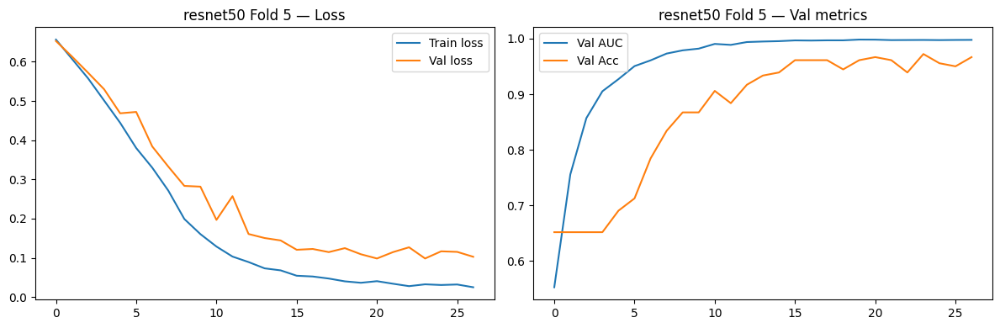


  RESNET50  —  5-FOLD SUMMARY
  acc         : 0.9365 ± 0.0293
  auc         : 0.9921 ± 0.0072
  f1          : 0.9319 ± 0.0346
  precision   : 0.9878 ± 0.0184
  recall      : 0.8846 ± 0.0615

  Saved summary: /content/drive/MyDrive/glenda_splits/resnet50/summary.json


In [ ]:
#resnet50
resnet_metrics = run_experiment(
    arch       = 'resnet50',
    splits     = splits,
    output_dir = OUTPUT_DIR,
    device     = device,
)

In [ ]:
#class-wise breakdown
all_tn = all_fp = all_fn = all_tp = 0

for i in range(5):
    probs, labels = quick_eval_from_ckpt('resnet50', splits, i)

    tn, fp, fn, tp, n_acc, p_acc = class_breakdown(probs, labels)

    print(f"\nFOLD {i+1}")
    print(f"Normal accuracy       : {n_acc:.4f}")
    print(f"Pathological accuracy : {p_acc:.4f}")
    print(f"TP={tp} FP={fp} FN={fn} TN={tn}")

    all_tn += tn
    all_fp += fp
    all_fn += fn
    all_tp += tp

print("\nOVERALL")
print(f"Normal accuracy       : {all_tn/(all_tn+all_fp):.4f}")
print(f"Pathological accuracy : {all_tp/(all_tp+all_fn):.4f}")


FOLD 1
Normal accuracy       : 0.9877
Pathological accuracy : 0.9259
TP=75 FP=1 FN=6 TN=80

FOLD 2
Normal accuracy       : 1.0000
Pathological accuracy : 0.7640
TP=68 FP=0 FN=21 TN=89

FOLD 3
Normal accuracy       : 1.0000
Pathological accuracy : 0.8955
TP=60 FP=0 FN=7 TN=67

FOLD 4
Normal accuracy       : 0.9545
Pathological accuracy : 0.9091
TP=60 FP=3 FN=6 TN=63

FOLD 5
Normal accuracy       : 1.0000
Pathological accuracy : 0.9286
TP=65 FP=0 FN=5 TN=70

OVERALL
Normal accuracy       : 0.9893
Pathological accuracy : 0.8794


In [ ]:
#altering input size for efficientformerv2_s0 implementation
import torchvision.transforms as T

TARGET_SIZE_EFF = (224, 224)  #required for efficientformer
eff_train_transforms = T.Compose([
    T.Resize(TARGET_SIZE_EFF, interpolation=T.InterpolationMode.BICUBIC),
    T.RandomHorizontalFlip(p=0.5),
    T.RandomRotation(degrees=10),
    T.ColorJitter(brightness=0.1, contrast=0.1),
    T.ToTensor(),
    T.Normalize(mean=NORM_MEAN, std=NORM_STD),
])

eff_eval_transforms = T.Compose([
    T.Resize(TARGET_SIZE_EFF, interpolation=T.InterpolationMode.BICUBIC),
    T.ToTensor(),
    T.Normalize(mean=NORM_MEAN, std=NORM_STD),
])

In [ ]:
#temporarily applying resizing to dataset
def run_effformer():
    global train_transforms, eval_transforms

    #swap transforms ONLY for this run
    train_transforms_backup = train_transforms
    eval_transforms_backup  = eval_transforms

    train_transforms = eff_train_transforms
    eval_transforms  = eff_eval_transforms

    metrics = run_experiment(
        arch='efficientformerv2_s0',
        splits=splits,
        output_dir=OUTPUT_DIR,
        device=device
    )

    #restore originals
    train_transforms = train_transforms_backup
    eval_transforms  = eval_transforms_backup

    return metrics


  EFFICIENTFORMERV2_S0  —  Fold 1 / 5
    Fold 1 | Epoch 01 | Batch 22/22 | loss=0.6585
  Epoch 01/30 | tr_loss=0.6585  tr_acc=0.6505 | vl_loss=0.5853  vl_acc=0.7143  vl_auc=0.8249  vl_f1=0.2857  ← best
    Fold 1 | Epoch 02 | Batch 22/22 | loss=0.5640
  Epoch 02/30 | tr_loss=0.5640  tr_acc=0.7546 | vl_loss=0.4872  vl_acc=0.8514  vl_auc=0.9350  vl_f1=0.7903  ← best
    Fold 1 | Epoch 03 | Batch 22/22 | loss=0.4363
  Epoch 03/30 | tr_loss=0.4363  tr_acc=0.8445 | vl_loss=0.3562  vl_acc=0.9029  vl_auc=0.9603  vl_f1=0.8547  ← best
    Fold 1 | Epoch 04 | Batch 22/22 | loss=0.3207
  Epoch 04/30 | tr_loss=0.3207  tr_acc=0.8987 | vl_loss=0.2337  vl_acc=0.9314  vl_auc=0.9778  vl_f1=0.8909  ← best
    Fold 1 | Epoch 05 | Batch 22/22 | loss=0.2025
  Epoch 05/30 | tr_loss=0.2025  tr_acc=0.9372 | vl_loss=0.1749  vl_acc=0.9486  vl_auc=0.9810  vl_f1=0.9189  ← best
    Fold 1 | Epoch 06 | Batch 22/22 | loss=0.1401
  Epoch 06/30 | tr_loss=0.1401  tr_acc=0.9643 | vl_loss=0.1470  vl_acc=0.9657  vl_auc=

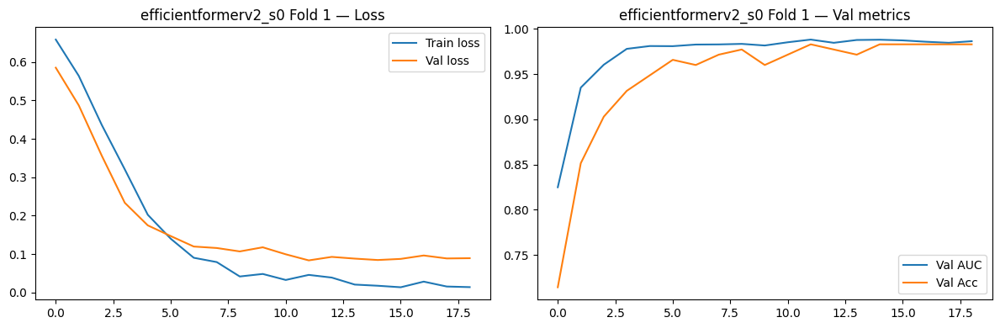


  EFFICIENTFORMERV2_S0  —  Fold 2 / 5
    Fold 2 | Epoch 01 | Batch 22/22 | loss=0.6676
  Epoch 01/30 | tr_loss=0.6676  tr_acc=0.6100 | vl_loss=0.7070  vl_acc=0.8294  vl_auc=0.8629  vl_f1=0.7129  ← best
    Fold 2 | Epoch 02 | Batch 22/22 | loss=0.5729
  Epoch 02/30 | tr_loss=0.5729  tr_acc=0.8138 | vl_loss=0.5064  vl_acc=0.8941  vl_auc=0.9600  vl_f1=0.8448  ← best
    Fold 2 | Epoch 03 | Batch 22/22 | loss=0.4544
  Epoch 03/30 | tr_loss=0.4544  tr_acc=0.8578 | vl_loss=0.5014  vl_acc=0.9294  vl_auc=0.9412  vl_f1=0.8889  (no improve 1/7)
    Fold 2 | Epoch 04 | Batch 22/22 | loss=0.3005
  Epoch 04/30 | tr_loss=0.3005  tr_acc=0.9135 | vl_loss=1.7294  vl_acc=0.9353  vl_auc=0.9518  vl_f1=0.8972  (no improve 2/7)
    Fold 2 | Epoch 05 | Batch 22/22 | loss=0.1842
  Epoch 05/30 | tr_loss=0.1842  tr_acc=0.9487 | vl_loss=0.6099  vl_acc=0.9353  vl_auc=0.9584  vl_f1=0.8972  (no improve 3/7)
    Fold 2 | Epoch 06 | Batch 22/22 | loss=0.1553
  Epoch 06/30 | tr_loss=0.1553  tr_acc=0.9531 | vl_loss=

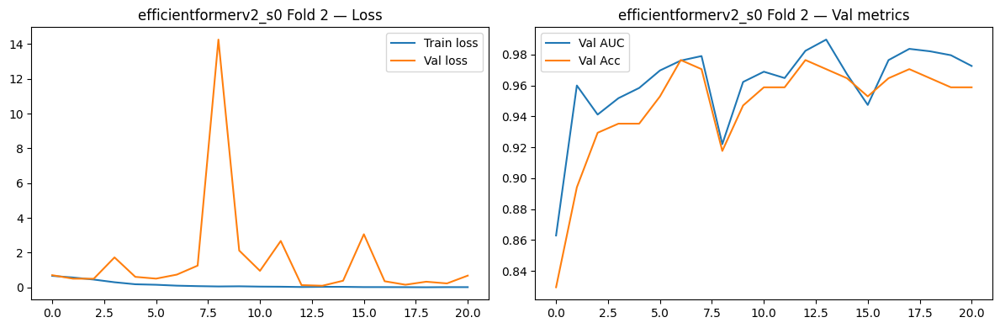


  EFFICIENTFORMERV2_S0  —  Fold 3 / 5
    Fold 3 | Epoch 01 | Batch 23/23 | loss=0.6479
  Epoch 01/30 | tr_loss=0.6479  tr_acc=0.6735 | vl_loss=3.0522  vl_acc=0.8361  vl_auc=0.8753  vl_f1=0.7368  ← best
    Fold 3 | Epoch 02 | Batch 23/23 | loss=0.5384
  Epoch 02/30 | tr_loss=0.5384  tr_acc=0.8054 | vl_loss=2.8760  vl_acc=0.8798  vl_auc=0.9318  vl_f1=0.8136  ← best
    Fold 3 | Epoch 03 | Batch 23/23 | loss=0.3973
  Epoch 03/30 | tr_loss=0.3973  tr_acc=0.8667 | vl_loss=2.1092  vl_acc=0.9454  vl_auc=0.9683  vl_f1=0.9123  ← best
    Fold 3 | Epoch 04 | Batch 23/23 | loss=0.2385
  Epoch 04/30 | tr_loss=0.2385  tr_acc=0.9429 | vl_loss=4.6088  vl_acc=0.9290  vl_auc=0.9715  vl_f1=0.8850  ← best
    Fold 3 | Epoch 05 | Batch 23/23 | loss=0.1438
  Epoch 05/30 | tr_loss=0.1438  tr_acc=0.9687 | vl_loss=5.7875  vl_acc=0.9290  vl_auc=0.9785  vl_f1=0.8850  ← best
    Fold 3 | Epoch 06 | Batch 23/23 | loss=0.0851
  Epoch 06/30 | tr_loss=0.0851  tr_acc=0.9810 | vl_loss=0.9615  vl_acc=0.9617  vl_auc=

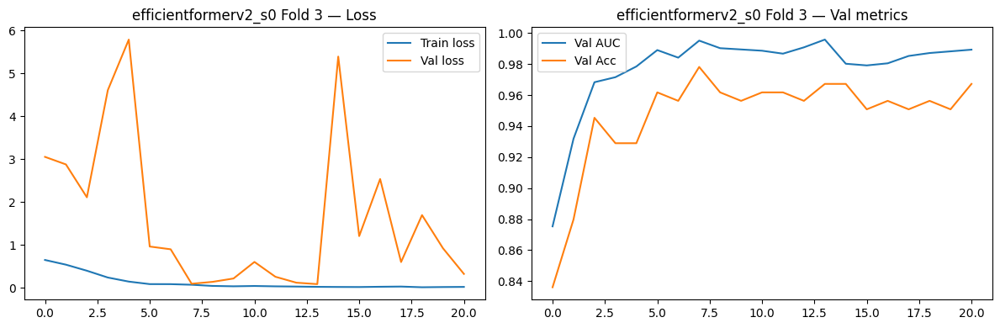


  EFFICIENTFORMERV2_S0  —  Fold 4 / 5
    Fold 4 | Epoch 01 | Batch 24/24 | loss=0.6782
  Epoch 01/30 | tr_loss=0.6782  tr_acc=0.6024 | vl_loss=1.3109  vl_acc=0.6793  vl_auc=0.7041  vl_f1=0.4040  ← best
    Fold 4 | Epoch 02 | Batch 24/24 | loss=0.5910
  Epoch 02/30 | tr_loss=0.5910  tr_acc=0.7585 | vl_loss=0.5140  vl_acc=0.8478  vl_auc=0.9030  vl_f1=0.7742  ← best
    Fold 4 | Epoch 03 | Batch 24/24 | loss=0.4720
  Epoch 03/30 | tr_loss=0.4720  tr_acc=0.8114 | vl_loss=0.3653  vl_acc=0.8859  vl_auc=0.9514  vl_f1=0.8205  ← best
    Fold 4 | Epoch 04 | Batch 24/24 | loss=0.3269
  Epoch 04/30 | tr_loss=0.3269  tr_acc=0.8860 | vl_loss=0.2859  vl_acc=0.9293  vl_auc=0.9593  vl_f1=0.8807  ← best
    Fold 4 | Epoch 05 | Batch 24/24 | loss=0.2103
  Epoch 05/30 | tr_loss=0.2103  tr_acc=0.9322 | vl_loss=0.1527  vl_acc=0.9565  vl_auc=0.9912  vl_f1=0.9298  ← best
    Fold 4 | Epoch 06 | Batch 24/24 | loss=0.1325
  Epoch 06/30 | tr_loss=0.1325  tr_acc=0.9593 | vl_loss=0.1323  vl_acc=0.9565  vl_auc=

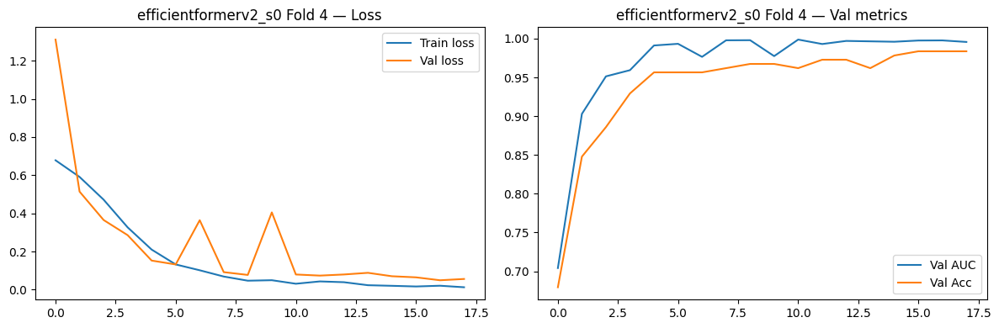


  EFFICIENTFORMERV2_S0  —  Fold 5 / 5
    Fold 5 | Epoch 01 | Batch 23/23 | loss=0.6727
  Epoch 01/30 | tr_loss=0.6727  tr_acc=0.6387 | vl_loss=1.4472  vl_acc=0.7238  vl_auc=0.7834  vl_f1=0.4186  ← best
    Fold 5 | Epoch 02 | Batch 23/23 | loss=0.5975
  Epoch 02/30 | tr_loss=0.5975  tr_acc=0.7871 | vl_loss=9.9148  vl_acc=0.7845  vl_auc=0.8697  vl_f1=0.6061  ← best
    Fold 5 | Epoch 03 | Batch 23/23 | loss=0.4886
  Epoch 03/30 | tr_loss=0.4886  tr_acc=0.8434 | vl_loss=5.5504  vl_acc=0.8785  vl_auc=0.8913  vl_f1=0.8136  ← best
    Fold 5 | Epoch 04 | Batch 23/23 | loss=0.3250
  Epoch 04/30 | tr_loss=0.3250  tr_acc=0.9203 | vl_loss=2.5943  vl_acc=0.8950  vl_auc=0.9270  vl_f1=0.8403  ← best
    Fold 5 | Epoch 05 | Batch 23/23 | loss=0.2004
  Epoch 05/30 | tr_loss=0.2004  tr_acc=0.9451 | vl_loss=3.5348  vl_acc=0.8785  vl_auc=0.9185  vl_f1=0.8254  (no improve 1/7)
    Fold 5 | Epoch 06 | Batch 23/23 | loss=0.1252
  Epoch 06/30 | tr_loss=0.1252  tr_acc=0.9670 | vl_loss=1.2913  vl_acc=0.900

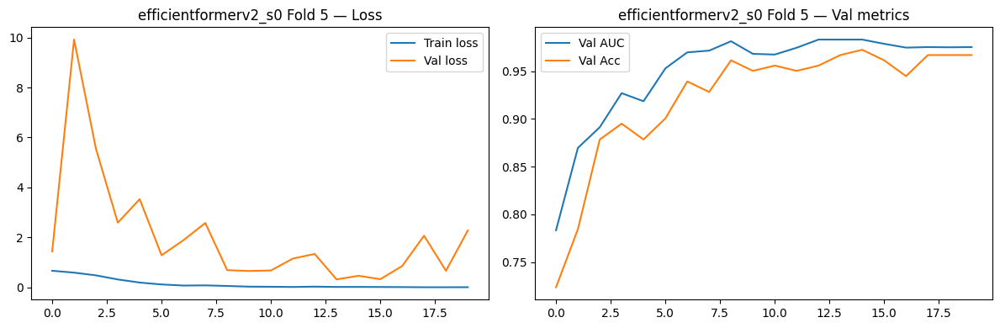


  EFFICIENTFORMERV2_S0  —  5-FOLD SUMMARY
  acc         : 0.9471 ± 0.0239
  auc         : 0.9876 ± 0.0124
  f1          : 0.9441 ± 0.0260
  precision   : 0.9916 ± 0.0108
  recall      : 0.9015 ± 0.0386

  Saved summary: /content/drive/MyDrive/glenda_splits/efficientformerv2_s0/summary.json


In [ ]:
effformer_metrics = run_effformer()

In [ ]:
#efficient former class-wise breakdown
import torch
import torch.nn as nn
from torch.utils.data import DataLoader

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
criterion = nn.CrossEntropyLoss()

#Using the correct 224x224 transforms for EfficientFormerV2
TARGET_SIZE_EFF = (224, 224)

eff_eval_transforms = T.Compose([
    T.Resize(TARGET_SIZE_EFF, interpolation=T.InterpolationMode.BICUBIC),
    T.ToTensor(),
    T.Normalize(mean=NORM_MEAN, std=NORM_STD),
])

def quick_eval_from_ckpt_eff(splits, fold_idx):
    """Specific version for efficientformerv2_s0 with correct transforms"""
    fold = splits[fold_idx]

    test_ds = GlendaDataset(fold['test'], transform=eff_eval_transforms)
    test_loader = DataLoader(test_ds, batch_size=32, shuffle=False,
                            num_workers=2, pin_memory=False)

    model = build_model('efficientformerv2_s0').to(device)

    ckpt_path = OUTPUT_DIR / 'efficientformerv2_s0' / f"fold{fold_idx+1}_best.pt"
    model.load_state_dict(torch.load(ckpt_path, map_location=device))

    model.eval()

    all_probs, all_labels = [], []

    with torch.no_grad():
        for imgs, labels in test_loader:
            imgs = imgs.to(device)
            logits = model(imgs)
            probs = torch.softmax(logits, dim=1)[:, 1]   # probability of pathological class

            all_probs.append(probs.cpu())
            all_labels.append(labels)

    probs = torch.cat(all_probs)
    labels = torch.cat(all_labels)

    return probs, labels


def class_breakdown(probs, labels, threshold=0.5):
    """Same as before"""
    preds = (probs >= threshold).long()

    tn = ((preds == 0) & (labels == 0)).sum().item()
    fp = ((preds == 1) & (labels == 0)).sum().item()
    fn = ((preds == 0) & (labels == 1)).sum().item()
    tp = ((preds == 1) & (labels == 1)).sum().item()

    normal_acc = tn / (tn + fp + 1e-8)
    path_acc   = tp / (tp + fn + 1e-8)

    return tn, fp, fn, tp, normal_acc, path_acc


# ====================== RUNNING THE BREAKDOWN ======================

print("=== EFFICIENTFORMERV2_S0 — CLASS-WISE BREAKDOWN ===\n")

all_tn = all_fp = all_fn = all_tp = 0

for i in range(5):
    probs, labels = quick_eval_from_ckpt_eff(splits, i)

    tn, fp, fn, tp, n_acc, p_acc = class_breakdown(probs, labels)

    print(f"FOLD {i+1}")
    print(f"Normal accuracy       : {n_acc:.4f}")
    print(f"Pathological accuracy : {p_acc:.4f}")
    print(f"TP={tp:3d}  FP={fp:3d}  FN={fn:3d}  TN={tn:3d}")
    print("-" * 50)

    all_tn += tn
    all_fp += fp
    all_fn += fn
    all_tp += tp

#Overall results
print("\n" + "="*60)
print("OVERALL (EfficientFormerV2_S0 - 5 Folds)")
print("="*60)
print(f"Normal accuracy       : {all_tn/(all_tn+all_fp):.4f}")
print(f"Pathological accuracy : {all_tp/(all_tp+all_fn):.4f}")
print(f"Total TP={all_tp}  FP={all_fp}  FN={all_fn}  TN={all_tn}")

=== EFFICIENTFORMERV2_S0 — CLASS-WISE BREAKDOWN ===

FOLD 1
Normal accuracy       : 1.0000
Pathological accuracy : 0.9136
TP= 74  FP=  0  FN=  7  TN= 81
--------------------------------------------------
FOLD 2
Normal accuracy       : 0.9775
Pathological accuracy : 0.8427
TP= 75  FP=  2  FN= 14  TN= 87
--------------------------------------------------
FOLD 3
Normal accuracy       : 1.0000
Pathological accuracy : 0.9403
TP= 63  FP=  0  FN=  4  TN= 67
--------------------------------------------------
FOLD 4
Normal accuracy       : 1.0000
Pathological accuracy : 0.9394
TP= 62  FP=  0  FN=  4  TN= 66
--------------------------------------------------
FOLD 5
Normal accuracy       : 0.9857
Pathological accuracy : 0.8714
TP= 61  FP=  1  FN=  9  TN= 69
--------------------------------------------------

OVERALL (EfficientFormerV2_S0 - 5 Folds)
Normal accuracy       : 0.9920
Pathological accuracy : 0.8981
Total TP=335  FP=3  FN=38  TN=370


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


##Explainability techniques on EdgeNeXt

In [ ]:
#reinstalling due to new session
!pip install -q grad-cam

In [ ]:
#reloading in new session for explainability techniques
import pickle
import sys
import torch
import timm
import torch.nn as nn
from pathlib import Path

device     = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
OUTPUT_DIR = Path('/content/drive/MyDrive/glenda_splits')

with open(OUTPUT_DIR / 'splits.pkl', 'rb') as f:
    splits = pickle.load(f)

def build_model(arch: str, num_classes: int = 2, pretrained: bool = True):
    if arch == 'edgenext_small':
        return timm.create_model('edgenext_small', pretrained=pretrained, num_classes=num_classes)
    elif arch == 'resnet50':
        return timm.create_model('resnet50.a1_in1k', pretrained=pretrained, num_classes=num_classes)
    elif arch == 'efficientformerv2_s0':
        return timm.create_model('efficientformerv2_s0', pretrained=pretrained, num_classes=num_classes)
    else:
        raise ValueError(f"Unknown arch: {arch}")

print(f"Device     : {device}")
print(f"Output dir : {OUTPUT_DIR}")
print(f"Splits     : {len(splits)} folds loaded")

Device     : cuda
Output dir : /content/drive/MyDrive/glenda_splits
Splits     : 5 folds loaded


In [ ]:
#GradCAM++ and RISE utilities
import sys
import numpy as np
import torch
import torch.nn.functional as F
import torchvision.transforms as T
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path
from pytorch_grad_cam import GradCAMPlusPlus
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

COLOUR_PALETTE = [
    (0,   0,   0),
    (190, 62, 204),
    (93,  89, 254),
    (145, 210, 138),
    (238, 236, 50),
]

eval_transforms = T.Compose([
    T.Resize((320, 320), interpolation=T.InterpolationMode.BICUBIC),
    T.ToTensor(),
    T.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5]),
])

def parse_mask_to_binary(annot_path: str) -> np.ndarray:
    mask_rgb = np.array(Image.open(annot_path).convert('RGB'))
    binary   = np.zeros(mask_rgb.shape[:2], dtype=np.uint8)
    for colour in COLOUR_PALETTE[1:]:
        match = np.all(mask_rgb == colour, axis=-1)
        binary[match] = 1
    return binary

def preprocess_image(image_path: str):
    img    = Image.open(image_path).convert('RGB')
    tensor = eval_transforms(img).unsqueeze(0).to(device)
    img_np = np.array(img.resize((320, 320), Image.BICUBIC))
    return tensor, img_np

def compute_alignment(pred_map_norm: np.ndarray, gt_mask: np.ndarray, threshold: float = 0.3):
    assert pred_map_norm.shape == gt_mask.shape == (320, 320), \
        f"Shape mismatch: {pred_map_norm.shape} vs {gt_mask.shape}"
    binary       = (pred_map_norm >= threshold).astype(np.uint8)
    intersection = (binary & gt_mask).sum()
    union        = (binary | gt_mask).sum()
    iou          = intersection / (union + 1e-8)
    dice         = 2 * intersection / (binary.sum() + gt_mask.sum() + 1e-8)
    recall       = intersection / (gt_mask.sum() + 1e-8)
    return iou, dice, recall

def get_target_layer(model, arch: str):
    if arch == 'edgenext_small':
        return [model.stages[-1]]   #entire last stage, exactly as Zhu & Elbattah
    elif arch == 'resnet50':
        return [model.layer4[-1]]   #entire last residual block
    elif arch == 'efficientformerv2_s0':
        return [model.stages[-1]]   #same approach
    else:
        raise ValueError(f"No target layer defined for {arch}")

def load_best_model(arch: str, fold: int):
    ckpt_path = OUTPUT_DIR / arch / f'fold{fold}_best.pt'
    model     = build_model(arch, pretrained=False).to(device)
    model.load_state_dict(torch.load(ckpt_path, map_location=device))
    model.eval()
    return model

def get_annotated_samples_for_fold(fold_idx: int):
    """Returns all annotated pathological test samples for a given fold (0-indexed)."""
    test_df   = splits[fold_idx]['test']
    annotated = test_df[(test_df['label'] == 1) & (test_df['has_annot'] == True)]
    return annotated.reset_index(drop=True)

In [ ]:
#GradCAM across all folds
def run_gradcam_all_folds(arch: str):
    all_results = []
    save_dir    = OUTPUT_DIR / arch
    save_dir.mkdir(parents=True, exist_ok=True)

    for fold_idx in range(5):
        fold_num     = fold_idx + 1
        samples      = get_annotated_samples_for_fold(fold_idx)
        fold_results = []

        if len(samples) == 0:
            sys.stdout.write(f"  Fold {fold_num}: no annotated samples, skipping\n")
            sys.stdout.flush()
            continue

        sys.stdout.write(f"\nFold {fold_num}/5 — {len(samples)} samples\n")
        sys.stdout.flush()

        model      = load_best_model(arch, fold_num)
        cam        = GradCAMPlusPlus(model=model, target_layers=[model.stages[-1]])
        targets    = [ClassifierOutputTarget(1)]

        n_vis = min(16, len(samples))
        fig, axes = plt.subplots(n_vis, 3, figsize=(12, n_vis * 3))
        if n_vis == 1:
            axes = [axes]

        for row_i, (_, row) in enumerate(samples.iterrows()):
            tensor, img_np  = preprocess_image(row['image_path'])
            gt_mask         = parse_mask_to_binary(row['annot_path'])
            gt_mask_resized = np.array(
                Image.fromarray(gt_mask * 255).resize((320, 320), Image.NEAREST)
            ) // 255

            grayscale_cam = cam(input_tensor=tensor, targets=targets)[0]
            cam_norm      = (grayscale_cam - grayscale_cam.min()) / \
                            (grayscale_cam.max() - grayscale_cam.min() + 1e-8)
            iou, dice, recall = compute_alignment(cam_norm, gt_mask_resized, threshold=0.3)

            result = {
                'fold'      : fold_num,
                'arch'      : arch,
                'method'    : 'gradcam',
                'image_path': row['image_path'],
                'patient_id': row['patient_id'],
                'iou'       : float(iou),
                'dice'      : float(dice),
                'recall'    : float(recall),
            }
            fold_results.append(result)
            all_results.append(result)

            if row_i < n_vis:
                overlay = show_cam_on_image(
                    img_np.astype(np.float32) / 255.0, cam_norm, use_rgb=True
                )
                axes[row_i][0].imshow(img_np);                         axes[row_i][0].set_title('Original');   axes[row_i][0].axis('off')
                axes[row_i][1].imshow(gt_mask_resized, cmap='Greens'); axes[row_i][1].set_title('GT Mask');    axes[row_i][1].axis('off')
                axes[row_i][2].imshow(overlay);                        axes[row_i][2].set_title(f'GradCAM\nIoU={iou:.3f} Dice={dice:.3f}'); axes[row_i][2].axis('off')

            sys.stdout.write(
                f"\r  [{row_i+1}/{len(samples)}] "
                f"IoU={iou:.3f} Dice={dice:.3f} Recall={recall:.3f}"
            )
            sys.stdout.flush()

        plt.suptitle(f'{arch} — GradCAM Fold {fold_num} (first {n_vis} samples)', fontsize=10)
        plt.tight_layout()
        plt.savefig(str(save_dir / f'gradcam_fold{fold_num}.png'), dpi=80)
        plt.close()

        fold_iou    = np.mean([r['iou']    for r in fold_results])
        fold_dice   = np.mean([r['dice']   for r in fold_results])
        fold_recall = np.mean([r['recall'] for r in fold_results])
        sys.stdout.write(
            f"\n  Fold {fold_num} summary ({len(fold_results)} samples) — "
            f"IoU={fold_iou:.4f} Dice={fold_dice:.4f} Recall={fold_recall:.4f}\n"
        )
        sys.stdout.flush()

    return all_results

In [ ]:
##RISE

In [ ]:
#RISE across all folds
def run_rise_all_folds(arch: str, n_masks: int = 2000, mask_size: int = 8, p_keep: float = 0.5):
    """
    Run RISE on all annotated test samples across all 5 folds.
    n_masks: number of random masks per image (2000 = paper standard, 500 for quick test)
    """
    all_results = []
    save_dir    = OUTPUT_DIR / arch
    save_dir.mkdir(parents=True, exist_ok=True)

    H, W = 320, 320

    def generate_masks(n, s, p1):
        masks = np.zeros((n, H, W), dtype=np.float32)
        for i in range(n):
            m = np.random.binomial(1, p1, size=(s, s)).astype(np.float32)
            m = np.array(Image.fromarray(m).resize((W, H), Image.BILINEAR))
            masks[i] = np.clip(m, 0, 1)
        return masks

    sys.stdout.write(f"Pre-generating {n_masks} masks...\n")
    sys.stdout.flush()
    masks = generate_masks(n_masks, mask_size, p_keep)  # (N, 320, 320)

    for fold_idx in range(5):
        fold_num = fold_idx + 1
        samples  = get_annotated_samples_for_fold(fold_idx)

        if len(samples) == 0:
            sys.stdout.write(f"  Fold {fold_num}: no annotated samples, skipping\n")
            sys.stdout.flush()
            continue

        sys.stdout.write(f"\nFold {fold_num}/5 — {len(samples)} samples\n")
        sys.stdout.flush()

        model = load_best_model(arch, fold_num)

        fold_results = []
        n_vis   = min(16, len(samples))
        fig, axes = plt.subplots(n_vis, 3, figsize=(12, n_vis * 3))
        if n_vis == 1:
            axes = [axes]

        norm_tf = T.Compose([
            T.ToTensor(),
            T.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
        ])

        for row_i, (_, row) in enumerate(samples.iterrows()):
            tensor, img_np  = preprocess_image(row['image_path'])
            img_np_f        = img_np.astype(np.float32) / 255.0
            gt_mask         = parse_mask_to_binary(row['annot_path'])
            gt_mask_resized = np.array(
                Image.fromarray(gt_mask * 255).resize((320, 320), Image.NEAREST)
            ) // 255

            # Run masked forward passes in batches of 64
            scores   = []
            batch_sz = 64
            for start in range(0, n_masks, batch_sz):
                batch_masks = masks[start:start + batch_sz]
                masked_imgs = []
                for m in batch_masks:
                    masked  = img_np_f * m[:, :, np.newaxis]
                    t       = norm_tf(Image.fromarray((masked * 255).astype(np.uint8)))
                    masked_imgs.append(t)
                batch_tensor = torch.stack(masked_imgs).to(device)
                with torch.no_grad():
                    logits = model(batch_tensor)
                    probs  = F.softmax(logits, dim=1)[:, 1].cpu().numpy()
                scores.extend(probs.tolist())

            scores    = np.array(scores)
            rise_map  = (scores[:, None, None] * masks).sum(axis=0) / (scores.sum() + 1e-8)
            rise_norm = (rise_map - rise_map.min()) / (rise_map.max() - rise_map.min() + 1e-8)

            iou, dice, recall = compute_alignment(rise_norm, gt_mask_resized)

            fold_results.append({
                'fold': fold_num,
                'arch': arch,
                'method': 'rise',
                'image_path': row['image_path'],
                'patient_id': row['patient_id'],
                'iou': iou, 'dice': dice, 'recall': recall,
            })

            if row_i < n_vis:
                overlay = show_cam_on_image(img_np_f, rise_norm, use_rgb=True)
                axes[row_i][0].imshow(img_np);               axes[row_i][0].set_title('Original');   axes[row_i][0].axis('off')
                axes[row_i][1].imshow(gt_mask_resized, cmap='Greens'); axes[row_i][1].set_title('GT Mask'); axes[row_i][1].axis('off')
                axes[row_i][2].imshow(overlay);              axes[row_i][2].set_title(f'RISE\nIoU={iou:.3f} Dice={dice:.3f}'); axes[row_i][2].axis('off')

            sys.stdout.write(
                f"\r  [{row_i+1}/{len(samples)}] IoU={iou:.3f} Dice={dice:.3f} Recall={recall:.3f}"
            )
            sys.stdout.flush()

        plt.suptitle(f'{arch} — RISE Fold {fold_num} (first {n_vis} samples)', fontsize=10)
        plt.tight_layout()
        plt.savefig(str(save_dir / f'rise_fold{fold_num}.png'), dpi=80)
        plt.close()
        sys.stdout.write(f"\n  Saved: rise_fold{fold_num}.png\n")
        sys.stdout.flush()

        fold_iou    = np.mean([r['iou']    for r in fold_results])
        fold_dice   = np.mean([r['dice']   for r in fold_results])
        fold_recall = np.mean([r['recall'] for r in fold_results])
        sys.stdout.write(
            f"  Fold {fold_num} summary — IoU={fold_iou:.4f} "
            f"Dice={fold_dice:.4f} Recall={fold_recall:.4f}\n"
        )
        sys.stdout.flush()

        all_results.extend(fold_results)

    return all_results

In [ ]:
import pandas as pd

# ── Run GradCAM ────────────────────────────────────────────────────────────
sys.stdout.write("=" * 60 + "\n")
sys.stdout.write("  GradCAM — EdgeNeXt_Small — All Folds\n")
sys.stdout.write("=" * 60 + "\n")
sys.stdout.flush()
gc_results = run_gradcam_all_folds('edgenext_small')

  GradCAM — EdgeNeXt_Small — All Folds

Fold 1/5 — 81 samples
  [81/81] IoU=0.095 Dice=0.174 Recall=0.872
  Fold 1 summary (81 samples) — IoU=0.1392 Dice=0.2167 Recall=0.6194

Fold 2/5 — 89 samples
  [89/89] IoU=0.087 Dice=0.161 Recall=0.693
  Fold 2 summary (89 samples) — IoU=0.1361 Dice=0.2175 Recall=0.4797

Fold 3/5 — 67 samples
  [67/67] IoU=0.060 Dice=0.114 Recall=0.571
  Fold 3 summary (67 samples) — IoU=0.1803 Dice=0.2848 Recall=0.6494

Fold 4/5 — 66 samples
  [66/66] IoU=0.023 Dice=0.044 Recall=1.000
  Fold 4 summary (66 samples) — IoU=0.1419 Dice=0.2269 Recall=0.7500

Fold 5/5 — 70 samples
  [70/70] IoU=0.124 Dice=0.220 Recall=1.000
  Fold 5 summary (70 samples) — IoU=0.1369 Dice=0.2208 Recall=0.6858


In [ ]:
# ── Run RISE ─────────────────────────────────────────────────────────────────
sys.stdout.write("\n" + "=" * 60 + "\n")
sys.stdout.write("  RISE — EdgeNeXt_Small — All Folds\n")
sys.stdout.write("  (this will take a while — ~2-4 hrs on T4)\n")
sys.stdout.write("=" * 60 + "\n")
sys.stdout.flush()
rise_results = run_rise_all_folds('edgenext_small', n_masks=2000)

In [ ]:
from skimage.filters import threshold_otsu

def run_rise_all_folds(arch: str, n_masks: int = 2000, mask_size: int = 8, p_keep: float = 0.5):
    all_results = []
    save_dir    = OUTPUT_DIR / arch
    save_dir.mkdir(parents=True, exist_ok=True)

    H, W = 320, 320

    def generate_masks(n, s, p1):
        masks = np.zeros((n, H, W), dtype=np.float32)
        for i in range(n):
            m = np.random.binomial(1, p1, size=(s, s)).astype(np.float32)
            m = np.array(Image.fromarray(m).resize((W, H), Image.BILINEAR))
            masks[i] = np.clip(m, 0, 1)
        return masks

    sys.stdout.write(f"Pre-generating {n_masks} masks...\n")
    sys.stdout.flush()
    masks = generate_masks(n_masks, mask_size, p_keep)

    norm_tf = T.Compose([
        T.ToTensor(),
        T.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
    ])

    for fold_idx in range(5):
        fold_num     = fold_idx + 1
        samples      = get_annotated_samples_for_fold(fold_idx)
        fold_results = []

        if len(samples) == 0:
            sys.stdout.write(f"  Fold {fold_num}: no annotated samples, skipping\n")
            sys.stdout.flush()
            continue

        sys.stdout.write(f"\nFold {fold_num}/5 — {len(samples)} samples\n")
        sys.stdout.flush()

        model = load_best_model(arch, fold_num)
        model.eval()

        n_vis = min(16, len(samples))
        fig, axes = plt.subplots(n_vis, 3, figsize=(12, n_vis * 3))
        if n_vis == 1:
            axes = [axes]

        otsu_thresholds = []

        for row_i, (_, row) in enumerate(samples.iterrows()):
            tensor, img_np  = preprocess_image(row['image_path'])
            img_np_f        = img_np.astype(np.float32) / 255.0
            gt_mask         = parse_mask_to_binary(row['annot_path'])
            gt_mask_resized = np.array(
                Image.fromarray(gt_mask * 255).resize((320, 320), Image.NEAREST)
            ) // 255

            # Forward passes
            scores = []
            for start in range(0, n_masks, 64):
                batch_masks = masks[start:start + 64]
                masked_imgs = []
                for m in batch_masks:
                    masked = img_np_f * m[:, :, np.newaxis]
                    t      = norm_tf(Image.fromarray((masked * 255).astype(np.uint8)))
                    masked_imgs.append(t)
                batch_tensor = torch.stack(masked_imgs).to(device)
                with torch.no_grad():
                    probs = F.softmax(
                        model(batch_tensor), dim=1
                    )[:, 1].cpu().numpy()
                scores.extend(probs.tolist())

            scores    = np.array(scores)
            rise_map  = (scores[:, None, None] * masks).sum(axis=0) / (scores.sum() + 1e-8)
            rise_norm = (rise_map - rise_map.min()) / (rise_map.max() - rise_map.min() + 1e-8)

            # Otsu threshold — adaptive, no reference to GT mask
            try:
                otsu_t = float(threshold_otsu(rise_norm))
            except Exception:
                otsu_t = 0.5
            otsu_thresholds.append(otsu_t)

            binary       = (rise_norm >= otsu_t).astype(np.uint8)
            intersection = (binary & gt_mask_resized).sum()
            union        = (binary | gt_mask_resized).sum()
            iou          = float(intersection / (union + 1e-8))
            dice         = float(2 * intersection / (binary.sum() + gt_mask_resized.sum() + 1e-8))
            recall       = float(intersection / (gt_mask_resized.sum() + 1e-8))

            result = {
                'fold'      : fold_num,
                'arch'      : arch,
                'method'    : 'rise_otsu',
                'image_path': row['image_path'],
                'patient_id': row['patient_id'],
                'iou'       : iou,
                'dice'      : dice,
                'recall'    : recall,
                'otsu_t'    : otsu_t,
            }
            fold_results.append(result)
            all_results.append(result)

            if row_i < n_vis:
                overlay = show_cam_on_image(img_np_f, rise_norm, use_rgb=True)
                axes[row_i][0].imshow(img_np);
                axes[row_i][0].set_title('Original');           axes[row_i][0].axis('off')
                axes[row_i][1].imshow(gt_mask_resized, cmap='Greens');
                axes[row_i][1].set_title('GT Mask');            axes[row_i][1].axis('off')
                axes[row_i][2].imshow(overlay);
                axes[row_i][2].set_title(
                    f'RISE (Otsu={otsu_t:.2f})\n'
                    f'IoU={iou:.3f} Dice={dice:.3f}'
                );                                              axes[row_i][2].axis('off')

            sys.stdout.write(
                f"\r  [{row_i+1}/{len(samples)}] "
                f"IoU={iou:.3f} Dice={dice:.3f} Recall={recall:.3f} "
                f"Otsu={otsu_t:.3f}"
            )
            sys.stdout.flush()

        plt.suptitle(f'{arch} — RISE (Otsu) Fold {fold_num} (first {n_vis} samples)', fontsize=10)
        plt.tight_layout()
        plt.savefig(str(save_dir / f'rise_otsu_fold{fold_num}.png'), dpi=80)
        plt.close()

        fold_iou    = np.mean([r['iou']    for r in fold_results])
        fold_dice   = np.mean([r['dice']   for r in fold_results])
        fold_recall = np.mean([r['recall'] for r in fold_results])
        fold_otsu   = np.mean(otsu_thresholds)

        sys.stdout.write(
            f"\n  Fold {fold_num} summary ({len(fold_results)} samples) — "
            f"IoU={fold_iou:.4f} Dice={fold_dice:.4f} "
            f"Recall={fold_recall:.4f} AvgOtsu={fold_otsu:.3f}\n"
        )
        sys.stdout.flush()

    return all_results

# Run it
rise_otsu_results = run_rise_all_folds('edgenext_small', n_masks=2000)

Pre-generating 2000 masks...

Fold 1/5 — 81 samples
  [81/81] IoU=0.055 Dice=0.105 Recall=1.000 Otsu=0.373
  Fold 1 summary (81 samples) — IoU=0.1361 Dice=0.2137 Recall=0.6665 AvgOtsu=0.412

Fold 2/5 — 89 samples
  [89/89] IoU=0.015 Dice=0.029 Recall=0.853 Otsu=0.525
  Fold 2 summary (89 samples) — IoU=0.1265 Dice=0.2023 Recall=0.7714 AvgOtsu=0.424

Fold 3/5 — 67 samples
  [67/67] IoU=0.312 Dice=0.475 Recall=0.981 Otsu=0.350
  Fold 3 summary (67 samples) — IoU=0.2160 Dice=0.3262 Recall=0.7118 AvgOtsu=0.403

Fold 4/5 — 66 samples
  [66/66] IoU=0.023 Dice=0.045 Recall=0.862 Otsu=0.412
  Fold 4 summary (66 samples) — IoU=0.1405 Dice=0.2245 Recall=0.6208 AvgOtsu=0.420

Fold 5/5 — 70 samples
  [70/70] IoU=0.074 Dice=0.137 Recall=0.819 Otsu=0.416
  Fold 5 summary (70 samples) — IoU=0.1058 Dice=0.1730 Recall=0.6092 AvgOtsu=0.417



  edgenext_small — XAI Alignment with Expert Masks (n=373)
  Method         Metric          F1      F2      F3      F4      F5     Mean     Std
  ------------------------------------------------------------------------
  GradCAM++      iou        0.1392 0.1361 0.1803 0.1419 0.1369  0.1469 0.0168
                 dice       0.2167 0.2175 0.2848 0.2269 0.2208  0.2333 0.0260
                 recall     0.6194 0.4797 0.6494 0.7500 0.6858  0.6369 0.0899
  ------------------------------------------------------------------------
  RISE           iou        0.1361 0.1265 0.2160 0.1405 0.1058  0.1450 0.0375
                 dice       0.2137 0.2023 0.3262 0.2245 0.1730  0.2279 0.0521
                 recall     0.6665 0.7714 0.7118 0.6208 0.6092  0.6759 0.0600
  ------------------------------------------------------------------------

  Method                      IoU             Dice           Recall
  ----------------------------------------------------------------
  GradCAM++      0.1469±0.

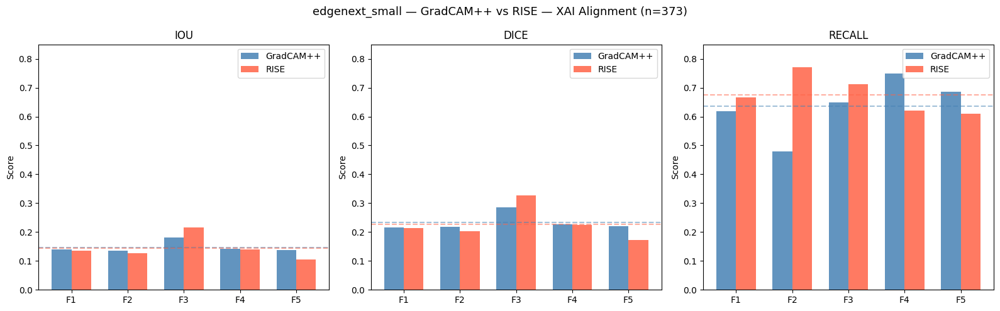

  Saved: xai_comparison_summary.png


In [ ]:
#summarization
# ── Summary across all folds ─────────────────────────────────────────────────
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

def summarise_xai_results(gc_results, rise_otsu_results, arch):
    gc_df   = pd.DataFrame(gc_results)
    rise_df = pd.DataFrame(rise_otsu_results)

    print(f"\n{'='*72}")
    print(f"  {arch} — XAI Alignment with Expert Masks (n=373)")
    print(f"{'='*72}")
    print(f"  {'Method':<14} {'Metric':<10} {'F1':>7} {'F2':>7} {'F3':>7} {'F4':>7} {'F5':>7} {'Mean':>8} {'Std':>7}")
    print(f"  {'-'*72}")

    for method_name, df in [('GradCAM++', gc_df), ('RISE', rise_df)]:
        first = True
        for metric in ['iou', 'dice', 'recall']:
            fold_means = [df[df['fold'] == f+1][metric].mean() for f in range(5)]
            mean = np.mean(fold_means)
            std  = np.std(fold_means)
            label = method_name if first else ''
            row = f"  {label:<14} {metric:<10}" + "".join(f"{v:>7.4f}" for v in fold_means)
            row += f"{mean:>8.4f}{std:>7.4f}"
            print(row)
            first = False
        print(f"  {'-'*72}")

    # Compact comparison
    print(f"\n  {'Method':<14} {'IoU':>16} {'Dice':>16} {'Recall':>16}")
    print(f"  {'-'*64}")
    for method_name, df in [('GradCAM++', gc_df), ('RISE', rise_df)]:
        fold_iou    = [df[df['fold']==f+1]['iou'].mean()    for f in range(5)]
        fold_dice   = [df[df['fold']==f+1]['dice'].mean()   for f in range(5)]
        fold_recall = [df[df['fold']==f+1]['recall'].mean() for f in range(5)]
        print(f"  {method_name:<14} "
              f"{np.mean(fold_iou):>6.4f}±{np.std(fold_iou):.4f}  "
              f"{np.mean(fold_dice):>6.4f}±{np.std(fold_dice):.4f}  "
              f"{np.mean(fold_recall):>6.4f}±{np.std(fold_recall):.4f}")

    # Save CSVs
    gc_df.to_csv(OUTPUT_DIR / arch / 'gradcampp_all_folds.csv', index=False)
    rise_df.to_csv(OUTPUT_DIR / arch / 'rise_all_folds.csv', index=False)
    print(f"\n  Saved CSVs to {OUTPUT_DIR / arch}/")

    # ── Bar chart ─────────────────────────────────────────────────────────────
    fig, axes = plt.subplots(1, 3, figsize=(16, 5))
    colors    = {'GradCAM++': 'steelblue', 'RISE': 'tomato'}
    x         = np.arange(5)
    width     = 0.35
    folds     = [f"F{i+1}" for i in range(5)]

    for ax, metric in zip(axes, ['iou', 'dice', 'recall']):
        for i, (method_name, df) in enumerate([('GradCAM++', gc_df), ('RISE', rise_df)]):
            vals   = [df[df['fold']==f+1][metric].mean() for f in range(5)]
            offset = (i - 0.5) * width
            ax.bar(x + offset, vals, width,
                   label=method_name, color=colors[method_name], alpha=0.85)
            ax.axhline(np.mean(vals), color=colors[method_name],
                       linestyle='--', alpha=0.5, linewidth=1.5)
        ax.set_xticks(x)
        ax.set_xticklabels(folds)
        ax.set_ylim(0, 0.85)
        ax.set_title(metric.upper())
        ax.set_ylabel('Score')
        ax.legend()

    plt.suptitle(f'{arch} — GradCAM++ vs RISE — XAI Alignment (n=373)', fontsize=13)
    plt.tight_layout()
    plt.savefig(str(OUTPUT_DIR / arch / 'xai_comparison_summary.png'), dpi=120)
    plt.show()
    print(f"  Saved: xai_comparison_summary.png")

summarise_xai_results(gc_results, rise_otsu_results, 'edgenext_small')

##Fine-Tuning EdgeNeXt for SPE

In [ ]:
#identifying best EdgeNeXt fold and building peritoneal dataset
import pickle
import json
import pandas as pd
import numpy as np
from pathlib import Path
import torch
import torch.nn as nn
import torchvision.transforms as T
from PIL import Image

OUTPUT_DIR = Path('/content/drive/MyDrive/glenda_splits')

with open(OUTPUT_DIR / 'splits.pkl', 'rb') as f:
    splits = pickle.load(f)

# Load EdgeNeXt summary to find best fold by AUC
with open(OUTPUT_DIR / 'edgenext_small' / 'summary.json') as f:
    en_summary = json.load(f)

best_fold_idx = int(np.argmax(en_summary['auc']['per_fold']))
best_fold_num = best_fold_idx + 1
best_auc      = en_summary['auc']['per_fold'][best_fold_idx]
print(f"Best EdgeNeXt fold: {best_fold_num}  (AUC={best_auc:.4f})")

# Peritoneal colour
PERITONEAL_RGB = (190, 62, 204)

def has_peritoneal_lesion(annot_path: str) -> bool:
    """Returns True if the annotation mask contains any peritoneal pixels."""
    if annot_path is None:
        return False
    try:
        mask = np.array(Image.open(annot_path).convert('RGB'))
        return bool(np.any(np.all(mask == PERITONEAL_RGB, axis=-1)))
    except:
        return False

# Build peritoneal-specific dataframes for all folds
peritoneal_splits = []

for fold_idx, fold in enumerate(splits):
    fold_num = fold_idx + 1

    # From each split, keep:
    # Positive = images that have peritoneal lesion pixels
    # Negative = normal images (label == 0)
    new_fold = {}
    for split_name in ['train', 'val', 'test']:
        df = fold[split_name].copy()

        # Mark peritoneal positives
        df['peritoneal'] = df.apply(
            lambda r: 1 if (r['label'] == 1 and has_peritoneal_lesion(r['annot_path']))
                      else (0 if r['label'] == 0 else -1),
            axis=1
        )

        # Drop non-peritoneal pathological images (label=1 but not peritoneal)
        df = df[df['peritoneal'] != -1].copy()
        df['peri_label'] = df['peritoneal']  # 0=normal, 1=peritoneal
        new_fold[split_name] = df.reset_index(drop=True)

    new_fold['fold'] = fold_idx
    new_fold['train_patho_patients'] = fold['train_patho_patients']
    new_fold['test_patho_patients']  = fold['test_patho_patients']
    peritoneal_splits.append(new_fold)

    tr = new_fold['train']
    vl = new_fold['val']
    te = new_fold['test']
    print(f"Fold {fold_num} | "
          f"Train: {len(tr)} (peri={tr['peri_label'].sum()}, "
          f"norm={(tr['peri_label']==0).sum()}) | "
          f"Val: {len(vl)} | "
          f"Test: {len(te)} (peri={te['peri_label'].sum()}, "
          f"norm={(te['peri_label']==0).sum()})")

Best EdgeNeXt fold: 1  (AUC=0.9998)
Fold 1 | Train: 622 (peri=156, norm=466) | Val: 164 | Test: 136 (peri=55, norm=81)
Fold 2 | Train: 606 (peri=153, norm=453) | Val: 158 | Test: 150 (peri=61, norm=89)
Fold 3 | Train: 661 (peri=172, norm=489) | Val: 166 | Test: 109 (peri=42, norm=67)
Fold 4 | Train: 656 (peri=165, norm=491) | Val: 167 | Test: 114 (peri=48, norm=66)
Fold 5 | Train: 657 (peri=169, norm=488) | Val: 155 | Test: 121 (peri=51, norm=70)


In [ ]:
#peritoneal dataset class
class PeritonealDataset(torch.utils.data.Dataset):
    def __init__(self, df, transform=None):
        self.df        = df.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row   = self.df.iloc[idx]
        image = Image.open(row['image_path']).convert('RGB')
        label = int(row['peri_label'])
        if self.transform:
            image = self.transform(image)
        return image, label

TARGET_SIZE = (320, 320)
NORM_MEAN   = [0.5, 0.5, 0.5]
NORM_STD    = [0.5, 0.5, 0.5]

train_transforms = T.Compose([
    T.Resize(TARGET_SIZE, interpolation=T.InterpolationMode.BICUBIC),
    T.RandomHorizontalFlip(p=0.5),
    T.RandomRotation(degrees=10),
    T.ColorJitter(brightness=0.1, contrast=0.1),
    T.ToTensor(),
    T.Normalize(mean=NORM_MEAN, std=NORM_STD),
])

eval_transforms = T.Compose([
    T.Resize(TARGET_SIZE, interpolation=T.InterpolationMode.BICUBIC),
    T.ToTensor(),
    T.Normalize(mean=NORM_MEAN, std=NORM_STD),
])

In [ ]:
#fine-tuning strategy: progressive unfreezing
import timm
import copy
import sys

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

def load_pretrained_edgenext(fold_num: int):
    """Load the best EdgeNeXt checkpoint from the general classifier."""
    ckpt  = OUTPUT_DIR / 'edgenext_small' / f'fold{fold_num}_best.pt'
    model = timm.create_model('edgenext_small', pretrained=False, num_classes=2)
    model.load_state_dict(torch.load(ckpt, map_location=device))
    return model.to(device)

def freeze_all(model):
    for p in model.parameters():
        p.requires_grad = False

def unfreeze_head(model):
    """Stage 1: only classifier head."""
    for p in model.head.parameters():
        p.requires_grad = True

def unfreeze_last_stage(model):
    """Stage 2: head + final encoder stage."""
    for p in model.stages[3].parameters():
        p.requires_grad = True

def unfreeze_all(model):
    """Stage 3: full model."""
    for p in model.parameters():
        p.requires_grad = True

def count_trainable(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

In [ ]:
#fine-tuning loop with progressive unfreezing
from torchmetrics.classification import (
    BinaryAccuracy, BinaryAUROC, BinaryF1Score,
    BinaryPrecision, BinaryRecall, BinaryConfusionMatrix
)

# Fine-tuning hyperparameters
FINETUNE_CONFIG = {
    'stage1': {'epochs': 10, 'lr': 1e-3},  # head only
    'stage2': {'epochs': 10, 'lr': 1e-4},  # head + last stage
    'stage3': {'epochs': 15, 'lr': 5e-5},  # full model
}
BATCH_SIZE = 32
PATIENCE   = 5

def compute_metrics(probs, labels):
    preds = (probs >= 0.5).long()
    return {
        'acc'      : BinaryAccuracy()(preds, labels).item(),
        'auc'      : BinaryAUROC()(probs, labels).item(),
        'f1'       : BinaryF1Score()(preds, labels).item(),
        'precision': BinaryPrecision()(preds, labels).item(),
        'recall'   : BinaryRecall()(preds, labels).item(),
        'cm'       : BinaryConfusionMatrix()(preds, labels).numpy(),
    }

@torch.no_grad()
def evaluate_model(model, loader):
    model.eval()
    all_probs, all_labels = [], []
    total_loss, total = 0.0, 0
    criterion = nn.CrossEntropyLoss()
    for imgs, labels in loader:
        imgs, labels = imgs.to(device), labels.to(device)
        logits = model(imgs)
        loss   = criterion(logits, labels)
        probs  = torch.nn.functional.softmax(logits, dim=1)[:, 1]
        total_loss += loss.item() * imgs.size(0)
        total      += imgs.size(0)
        all_probs.append(probs.cpu())
        all_labels.append(labels.cpu())
    all_probs  = torch.cat(all_probs)
    all_labels = torch.cat(all_labels)
    return total_loss / total, all_probs, all_labels

def run_stage(model, stage_name, epochs, lr, train_loader, val_loader,
              best_auc, best_weights, patience_count, fold_num, save_dir):
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.AdamW(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=lr, weight_decay=1e-4
    )
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)

    sys.stdout.write(
        f"  [{stage_name}] trainable params={count_trainable(model):,}  "
        f"lr={lr}  epochs={epochs}\n"
    )
    sys.stdout.flush()

    for epoch in range(1, epochs + 1):
        model.train()
        tr_loss, tr_correct, tr_total = 0.0, 0, 0
        for batch_idx, (imgs, labels) in enumerate(train_loader):
            imgs, labels = imgs.to(device), labels.to(device)
            optimizer.zero_grad()
            logits = model(imgs)
            loss   = criterion(logits, labels)
            loss.backward()
            optimizer.step()
            tr_loss    += loss.item() * imgs.size(0)
            tr_correct += (logits.argmax(1) == labels).sum().item()
            tr_total   += imgs.size(0)
            sys.stdout.write(
                f"\r  [{stage_name}] Fold {fold_num} Epoch {epoch:02d}/{epochs} "
                f"Batch {batch_idx+1}/{len(train_loader)} "
                f"loss={tr_loss/tr_total:.4f}"
            )
            sys.stdout.flush()

        tr_loss /= tr_total
        tr_acc   = tr_correct / tr_total
        vl_loss, vl_probs, vl_labels = evaluate_model(model, val_loader)
        vl_metrics = compute_metrics(vl_probs, vl_labels)
        scheduler.step()

        improved = vl_metrics['auc'] > best_auc
        tag = ''
        if improved:
            best_auc      = vl_metrics['auc']
            best_weights  = copy.deepcopy(model.state_dict())
            patience_count = 0
            tag = '  ← best'
            torch.save(best_weights,
                       save_dir / f'fold{fold_num}_peritoneal_best.pt')
        else:
            patience_count += 1
            tag = f'  (no improve {patience_count}/{PATIENCE})'

        sys.stdout.write(
            f"\r  [{stage_name}] Fold {fold_num} Epoch {epoch:02d}/{epochs} | "
            f"tr_loss={tr_loss:.4f} tr_acc={tr_acc:.4f} | "
            f"vl_loss={vl_loss:.4f} vl_acc={vl_metrics['acc']:.4f} "
            f"vl_auc={vl_metrics['auc']:.4f} vl_f1={vl_metrics['f1']:.4f}"
            f"{tag}\n"
        )
        sys.stdout.flush()

        if patience_count >= PATIENCE:
            sys.stdout.write(f"  Early stopping at epoch {epoch}\n")
            sys.stdout.flush()
            break

    return best_auc, best_weights, patience_count

def run_peritoneal_finetune(peritoneal_splits, source_fold: int):
    """
    Fine-tune on all 5 folds using the general classifier checkpoint
    from source_fold as the starting weights.
    """
    save_dir = OUTPUT_DIR / 'edgenext_small_peritoneal'
    save_dir.mkdir(parents=True, exist_ok=True)

    all_fold_metrics = []
    PIN = torch.cuda.is_available()

    for fold_idx, fold in enumerate(peritoneal_splits):
        fold_num = fold_idx + 1
        sys.stdout.write(f"\n{'='*60}\n")
        sys.stdout.write(f"  PERITONEAL FINE-TUNE — Fold {fold_num}/5\n")
        sys.stdout.write(f"{'='*60}\n")
        sys.stdout.flush()

        train_ds = PeritonealDataset(fold['train'], transform=train_transforms)
        val_ds   = PeritonealDataset(fold['val'],   transform=eval_transforms)
        test_ds  = PeritonealDataset(fold['test'],  transform=eval_transforms)

        train_loader = torch.utils.data.DataLoader(
            train_ds, batch_size=BATCH_SIZE, shuffle=True,
            num_workers=2, pin_memory=PIN
        )
        val_loader = torch.utils.data.DataLoader(
            val_ds, batch_size=BATCH_SIZE, shuffle=False,
            num_workers=2, pin_memory=PIN
        )
        test_loader = torch.utils.data.DataLoader(
            test_ds, batch_size=BATCH_SIZE, shuffle=False,
            num_workers=2, pin_memory=PIN
        )

        sys.stdout.write(
            f"  Train: {len(train_ds)} "
            f"(peri={fold['train']['peri_label'].sum()}, "
            f"norm={(fold['train']['peri_label']==0).sum()})\n"
            f"  Val:   {len(val_ds)}\n"
            f"  Test:  {len(test_ds)} "
            f"(peri={fold['test']['peri_label'].sum()}, "
            f"norm={(fold['test']['peri_label']==0).sum()})\n"
        )
        sys.stdout.flush()

        # Load general classifier weights as starting point
        model = load_pretrained_edgenext(source_fold)

        best_auc      = 0.0
        best_weights  = None
        patience_count = 0

        # Stage 1: head only
        freeze_all(model)
        unfreeze_head(model)
        best_auc, best_weights, patience_count = run_stage(
            model, 'Stage1-HeadOnly',
            FINETUNE_CONFIG['stage1']['epochs'],
            FINETUNE_CONFIG['stage1']['lr'],
            train_loader, val_loader,
            best_auc, best_weights, patience_count,
            fold_num, save_dir
        )

        # Stage 2: head + last stage
        unfreeze_last_stage(model)
        patience_count = 0
        best_auc, best_weights, patience_count = run_stage(
            model, 'Stage2-LastStage',
            FINETUNE_CONFIG['stage2']['epochs'],
            FINETUNE_CONFIG['stage2']['lr'],
            train_loader, val_loader,
            best_auc, best_weights, patience_count,
            fold_num, save_dir
        )

        # Stage 3: full model
        unfreeze_all(model)
        patience_count = 0
        best_auc, best_weights, patience_count = run_stage(
            model, 'Stage3-FullModel',
            FINETUNE_CONFIG['stage3']['epochs'],
            FINETUNE_CONFIG['stage3']['lr'],
            train_loader, val_loader,
            best_auc, best_weights, patience_count,
            fold_num, save_dir
        )

        # Test with best weights
        model.load_state_dict(best_weights)
        _, test_probs, test_labels = evaluate_model(model, test_loader)
        test_metrics = compute_metrics(test_probs, test_labels)

        sys.stdout.write(f"\n  TEST RESULTS — Fold {fold_num} (Peritoneal)\n")
        sys.stdout.write(f"    Accuracy  : {test_metrics['acc']:.4f}\n")
        sys.stdout.write(f"    AUC       : {test_metrics['auc']:.4f}\n")
        sys.stdout.write(f"    F1        : {test_metrics['f1']:.4f}\n")
        sys.stdout.write(f"    Precision : {test_metrics['precision']:.4f}\n")
        sys.stdout.write(f"    Recall    : {test_metrics['recall']:.4f}\n")
        sys.stdout.write(f"    Confusion matrix:\n{test_metrics['cm']}\n")
        sys.stdout.flush()

        all_fold_metrics.append(test_metrics)

    return all_fold_metrics

In [ ]:
#running fine-tuning
peritoneal_metrics = run_peritoneal_finetune(
    peritoneal_splits,
    source_fold=best_fold_num   #uses  best general EdgeNeXt fold as init
)


  PERITONEAL FINE-TUNE — Fold 1/5
  Train: 622 (peri=156, norm=466)
  Val:   164
  Test:  136 (peri=55, norm=81)
  [Stage1-HeadOnly] trainable params=1,218  lr=0.001  epochs=10
  [Stage1-HeadOnly] Fold 1 Epoch 01/10 | tr_loss=0.0018 tr_acc=1.0000 | vl_loss=0.0224 vl_acc=0.9939 vl_auc=0.9996 vl_f1=0.9890  ← best
  [Stage1-HeadOnly] Fold 1 Epoch 02/10 | tr_loss=0.0002 tr_acc=1.0000 | vl_loss=0.0228 vl_acc=0.9939 vl_auc=0.9996 vl_f1=0.9890  ← best
  [Stage1-HeadOnly] Fold 1 Epoch 03/10 | tr_loss=0.0001 tr_acc=1.0000 | vl_loss=0.0234 vl_acc=0.9939 vl_auc=0.9998 vl_f1=0.9890  ← best
  [Stage1-HeadOnly] Fold 1 Epoch 04/10 | tr_loss=0.0002 tr_acc=1.0000 | vl_loss=0.0233 vl_acc=0.9939 vl_auc=0.9996 vl_f1=0.9890  (no improve 1/5)
  [Stage1-HeadOnly] Fold 1 Epoch 05/10 | tr_loss=0.0001 tr_acc=1.0000 | vl_loss=0.0233 vl_acc=0.9939 vl_auc=0.9996 vl_f1=0.9890  (no improve 2/5)
  [Stage1-HeadOnly] Fold 1 Epoch 06/10 | tr_loss=0.0002 tr_acc=1.0000 | vl_loss=0.0234 vl_acc=0.9939 vl_auc=0.9998 vl_f1=0


  PERITONEAL FINE-TUNE — 5-FOLD SUMMARY
  Metric             F1       F2       F3       F4       F5     Mean      Std
  ----------------------------------------------------------------------
  acc           0.9706  0.9867  1.0000  0.9912  0.9917  0.9880  0.0097
  auc           0.9996  1.0000  1.0000  1.0000  0.9997  0.9999  0.0002
  f1            0.9623  0.9833  1.0000  0.9897  0.9903  0.9851  0.0126
  precision     1.0000  1.0000  1.0000  0.9796  0.9808  0.9921  0.0097
  recall        0.9273  0.9672  1.0000  1.0000  1.0000  0.9789  0.0288

  CLASS-WISE BREAKDOWN (mean across folds)
                          Precision       Recall           F1
  ----------------------------------------------------------
  Peritoneal (class 1)       0.9921       0.9789       0.9851
      Normal (class 0)       0.9862       0.9941       0.9900


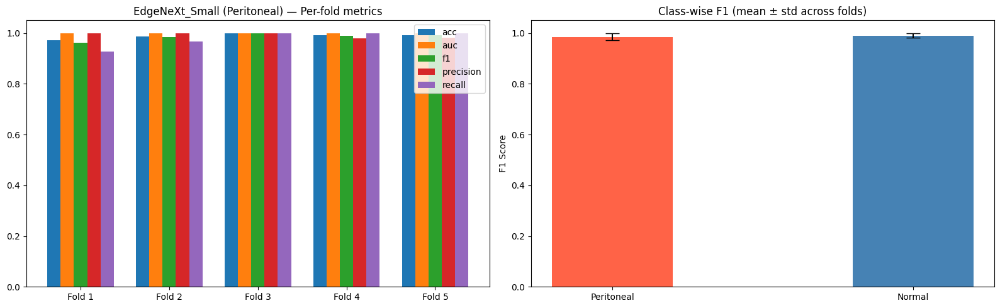

Saved: peritoneal_summary.png


In [ ]:
#summary and class-wise breakdown
import matplotlib.pyplot as plt

def peritoneal_summary(fold_metrics: list):
    sys.stdout.write(f"\n{'='*60}\n")
    sys.stdout.write("  PERITONEAL FINE-TUNE — 5-FOLD SUMMARY\n")
    sys.stdout.write(f"{'='*60}\n")
    sys.stdout.write(
        f"  {'Metric':<12} {'F1':>8} {'F2':>8} {'F3':>8} {'F4':>8} {'F5':>8} "
        f"{'Mean':>8} {'Std':>8}\n"
    )
    sys.stdout.write(f"  {'-'*70}\n")

    for metric in ['acc', 'auc', 'f1', 'precision', 'recall']:
        vals = [m[metric] for m in fold_metrics]
        row  = f"  {metric:<12}" + "".join(f"{v:>8.4f}" for v in vals)
        row += f"{np.mean(vals):>8.4f}{np.std(vals):>8.4f}\n"
        sys.stdout.write(row)
    sys.stdout.flush()

    # Class-wise breakdown from confusion matrices
    sys.stdout.write(f"\n  CLASS-WISE BREAKDOWN (mean across folds)\n")
    sys.stdout.write(f"  {'':>20} {'Precision':>12} {'Recall':>12} {'F1':>12}\n")
    sys.stdout.write(f"  {'-'*58}\n")

    # From confusion matrix: [[TN, FP], [FN, TP]]
    tps = [m['cm'][1][1] for m in fold_metrics]
    fps = [m['cm'][0][1] for m in fold_metrics]
    fns = [m['cm'][1][0] for m in fold_metrics]
    tns = [m['cm'][0][0] for m in fold_metrics]

    # Peritoneal (positive class)
    peri_prec = [tp/(tp+fp+1e-8) for tp,fp in zip(tps,fps)]
    peri_rec  = [tp/(tp+fn+1e-8) for tp,fn in zip(tps,fns)]
    peri_f1   = [2*p*r/(p+r+1e-8) for p,r in zip(peri_prec,peri_rec)]

    # Normal (negative class)
    norm_prec = [tn/(tn+fn+1e-8) for tn,fn in zip(tns,fns)]
    norm_rec  = [tn/(tn+fp+1e-8) for tn,fp in zip(tns,fps)]
    norm_f1   = [2*p*r/(p+r+1e-8) for p,r in zip(norm_prec,norm_rec)]

    sys.stdout.write(
        f"  {'Peritoneal (class 1)':>20} "
        f"{np.mean(peri_prec):>12.4f} "
        f"{np.mean(peri_rec):>12.4f} "
        f"{np.mean(peri_f1):>12.4f}\n"
    )
    sys.stdout.write(
        f"  {'Normal (class 0)':>20} "
        f"{np.mean(norm_prec):>12.4f} "
        f"{np.mean(norm_rec):>12.4f} "
        f"{np.mean(norm_f1):>12.4f}\n"
    )
    sys.stdout.flush()

    # Plot
    metrics_to_plot = ['acc', 'auc', 'f1', 'precision', 'recall']
    folds = [f"Fold {i+1}" for i in range(5)]
    x     = np.arange(len(folds))
    width = 0.15

    fig, axes = plt.subplots(1, 2, figsize=(16, 5))

    # Per-fold metric bars
    for i, metric in enumerate(metrics_to_plot):
        vals = [m[metric] for m in fold_metrics]
        axes[0].bar(x + i * width, vals, width, label=metric)
    axes[0].set_xticks(x + width * 2)
    axes[0].set_xticklabels(folds)
    axes[0].set_ylim(0, 1.05)
    axes[0].set_title('EdgeNeXt_Small (Peritoneal) — Per-fold metrics')
    axes[0].legend()

    # Class-wise F1 comparison
    classes    = ['Peritoneal', 'Normal']
    class_f1s  = [np.mean(peri_f1), np.mean(norm_f1)]
    class_stds = [np.std(peri_f1),  np.std(norm_f1)]
    axes[1].bar(classes, class_f1s, yerr=class_stds,
                color=['tomato', 'steelblue'], capsize=8, width=0.4)
    axes[1].set_ylim(0, 1.05)
    axes[1].set_title('Class-wise F1 (mean ± std across folds)')
    axes[1].set_ylabel('F1 Score')

    plt.tight_layout()
    plt.savefig(str(OUTPUT_DIR / 'edgenext_small_peritoneal' / 'peritoneal_summary.png'), dpi=120)
    plt.show()
    print("Saved: peritoneal_summary.png")

peritoneal_summary(peritoneal_metrics)

##Explainability technique on SPE Fine-Tuned

In [ ]:
#load
# ── SPE Fine-tuned EdgeNeXt — XAI ────────────────────────────────────────────
# Reload peritoneal splits if needed
import pickle, json
import pandas as pd
import numpy as np
import torch, timm
import torch.nn.functional as F
import torchvision.transforms as T
from pathlib import Path
from PIL import Image
from pytorch_grad_cam import GradCAMPlusPlus
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from skimage.filters import threshold_otsu
import sys, matplotlib.pyplot as plt

OUTPUT_DIR = Path('/content/drive/MyDrive/glenda_splits')
device     = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

with open(OUTPUT_DIR / 'splits.pkl', 'rb') as f:
    splits = pickle.load(f)

PERITONEAL_RGB = (190, 62, 204)
COLOUR_PALETTE = [
    (0,   0,   0),
    (190, 62, 204),
    (93,  89, 254),
    (145, 210, 138),
    (238, 236, 50),
]

eval_transforms = T.Compose([
    T.Resize((320, 320), interpolation=T.InterpolationMode.BICUBIC),
    T.ToTensor(),
    T.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5]),
])

def has_peritoneal_lesion(annot_path):
    if annot_path is None:
        return False
    try:
        mask = np.array(Image.open(annot_path).convert('RGB'))
        return bool(np.any(np.all(mask == PERITONEAL_RGB, axis=-1)))
    except:
        return False

def parse_mask_to_binary(annot_path):
    mask_rgb = np.array(Image.open(annot_path).convert('RGB'))
    binary   = np.zeros(mask_rgb.shape[:2], dtype=np.uint8)
    for colour in COLOUR_PALETTE[1:]:
        match = np.all(mask_rgb == colour, axis=-1)
        binary[match] = 1
    return binary

def preprocess_image(image_path):
    img    = Image.open(image_path).convert('RGB')
    tensor = eval_transforms(img).unsqueeze(0).to(device)
    img_np = np.array(img.resize((320, 320), Image.BICUBIC))
    return tensor, img_np

def compute_alignment(pred_map_norm, gt_mask, threshold=0.3):
    assert pred_map_norm.shape == gt_mask.shape == (320, 320)
    binary       = (pred_map_norm >= threshold).astype(np.uint8)
    intersection = (binary & gt_mask).sum()
    union        = (binary | gt_mask).sum()
    iou          = intersection / (union + 1e-8)
    dice         = 2 * intersection / (binary.sum() + gt_mask.sum() + 1e-8)
    recall       = intersection / (gt_mask.sum() + 1e-8)
    return float(iou), float(dice), float(recall)

def load_spe_model(fold_num):
    ckpt  = OUTPUT_DIR / 'edgenext_small_peritoneal' / f'fold{fold_num}_peritoneal_best.pt'
    model = timm.create_model('edgenext_small', pretrained=False, num_classes=2).to(device)
    model.load_state_dict(torch.load(ckpt, map_location=device))
    model.eval()
    return model

def get_peritoneal_test_samples(fold_idx):
    """Returns annotated peritoneal test samples for a given fold."""
    test_df   = splits[fold_idx]['test']
    annotated = test_df[
        (test_df['label'] == 1) &
        (test_df['has_annot'] == True) &
        (test_df['annot_path'].apply(has_peritoneal_lesion))
    ]
    return annotated.reset_index(drop=True)

In [ ]:
# ── GradCAM++ on SPE model ────────────────────────────────────────────────────
spe_gc_results = []
spe_save_dir   = OUTPUT_DIR / 'edgenext_small_peritoneal'
spe_save_dir.mkdir(parents=True, exist_ok=True)

sys.stdout.write("=" * 60 + "\n")
sys.stdout.write("  GradCAM++ — SPE Fine-tuned — All Folds\n")
sys.stdout.write("=" * 60 + "\n")
sys.stdout.flush()

for fold_idx in range(5):
    fold_num     = fold_idx + 1
    samples      = get_peritoneal_test_samples(fold_idx)
    fold_results = []

    if len(samples) == 0:
        sys.stdout.write(f"  Fold {fold_num}: no peritoneal samples, skipping\n")
        sys.stdout.flush()
        continue

    sys.stdout.write(f"\nFold {fold_num}/5 — {len(samples)} peritoneal samples\n")
    sys.stdout.flush()

    model  = load_spe_model(fold_num)
    cam    = GradCAMPlusPlus(model=model, target_layers=[model.stages[-1]])
    targets = [ClassifierOutputTarget(1)]

    n_vis = min(16, len(samples))
    fig, axes = plt.subplots(n_vis, 3, figsize=(12, n_vis * 3))
    if n_vis == 1:
        axes = [axes]

    for row_i, (_, row) in enumerate(samples.iterrows()):
        tensor, img_np  = preprocess_image(row['image_path'])
        gt_mask         = parse_mask_to_binary(row['annot_path'])
        gt_mask_resized = np.array(
            Image.fromarray(gt_mask * 255).resize((320, 320), Image.NEAREST)
        ) // 255

        grayscale_cam = cam(input_tensor=tensor, targets=targets)[0]
        cam_norm      = (grayscale_cam - grayscale_cam.min()) / \
                        (grayscale_cam.max() - grayscale_cam.min() + 1e-8)
        iou, dice, recall = compute_alignment(cam_norm, gt_mask_resized, threshold=0.3)

        result = {
            'fold': fold_num, 'arch': 'edgenext_small_peritoneal',
            'method': 'gradcampp', 'image_path': row['image_path'],
            'patient_id': row['patient_id'],
            'iou': iou, 'dice': dice, 'recall': recall,
        }
        fold_results.append(result)
        spe_gc_results.append(result)

        if row_i < n_vis:
            overlay = show_cam_on_image(img_np.astype(np.float32)/255.0, cam_norm, use_rgb=True)
            axes[row_i][0].imshow(img_np);                         axes[row_i][0].set_title('Original');   axes[row_i][0].axis('off')
            axes[row_i][1].imshow(gt_mask_resized, cmap='Greens'); axes[row_i][1].set_title('GT Mask');    axes[row_i][1].axis('off')
            axes[row_i][2].imshow(overlay);                        axes[row_i][2].set_title(f'GradCAM++\nIoU={iou:.3f} Dice={dice:.3f}'); axes[row_i][2].axis('off')

        sys.stdout.write(f"\r  [{row_i+1}/{len(samples)}] IoU={iou:.3f} Dice={dice:.3f} Recall={recall:.3f}")
        sys.stdout.flush()

    plt.suptitle(f'SPE Fine-tuned — GradCAM++ Fold {fold_num}', fontsize=10)
    plt.tight_layout()
    plt.savefig(str(spe_save_dir / f'gradcampp_fold{fold_num}.png'), dpi=80)
    plt.close()

    fold_iou    = np.mean([r['iou']    for r in fold_results])
    fold_dice   = np.mean([r['dice']   for r in fold_results])
    fold_recall = np.mean([r['recall'] for r in fold_results])
    sys.stdout.write(f"\n  Fold {fold_num} summary ({len(fold_results)} samples) — "
                     f"IoU={fold_iou:.4f} Dice={fold_dice:.4f} Recall={fold_recall:.4f}\n")
    sys.stdout.flush()


  GradCAM++ — SPE Fine-tuned — All Folds

Fold 1/5 — 55 peritoneal samples
  [55/55] IoU=0.095 Dice=0.173 Recall=0.817
  Fold 1 summary (55 samples) — IoU=0.0849 Dice=0.1477 Recall=0.5989

Fold 2/5 — 61 peritoneal samples
  [61/61] IoU=0.000 Dice=0.000 Recall=0.000
  Fold 2 summary (61 samples) — IoU=0.0887 Dice=0.1497 Recall=0.6428

Fold 3/5 — 42 peritoneal samples
  [42/42] IoU=0.086 Dice=0.159 Recall=0.404
  Fold 3 summary (42 samples) — IoU=0.0740 Dice=0.1289 Recall=0.5040

Fold 4/5 — 48 peritoneal samples
  [48/48] IoU=0.024 Dice=0.046 Recall=1.000
  Fold 4 summary (48 samples) — IoU=0.1123 Dice=0.1841 Recall=0.6420

Fold 5/5 — 51 peritoneal samples
  [51/51] IoU=0.118 Dice=0.212 Recall=0.617
  Fold 5 summary (51 samples) — IoU=0.0931 Dice=0.1566 Recall=0.6233


In [ ]:
# ── RISE on SPE model (Otsu threshold) ───────────────────────────────────────
spe_rise_results = []
norm_tf = T.Compose([T.ToTensor(), T.Normalize([0.5]*3, [0.5]*3)])

H, W    = 320, 320
n_masks = 2000
np.random.seed(42)
masks   = np.zeros((n_masks, H, W), dtype=np.float32)
for i in range(n_masks):
    m = np.random.binomial(1, 0.5, size=(8, 8)).astype(np.float32)
    m = np.array(Image.fromarray(m).resize((W, H), Image.BILINEAR))
    masks[i] = np.clip(m, 0, 1)

sys.stdout.write("\n" + "=" * 60 + "\n")
sys.stdout.write("  RISE (Otsu) — SPE Fine-tuned — All Folds\n")
sys.stdout.write("=" * 60 + "\n")
sys.stdout.flush()

for fold_idx in range(5):
    fold_num     = fold_idx + 1
    samples      = get_peritoneal_test_samples(fold_idx)
    fold_results = []
    otsu_ts      = []

    if len(samples) == 0:
        sys.stdout.write(f"  Fold {fold_num}: no peritoneal samples, skipping\n")
        sys.stdout.flush()
        continue

    sys.stdout.write(f"\nFold {fold_num}/5 — {len(samples)} peritoneal samples\n")
    sys.stdout.flush()

    model = load_spe_model(fold_num)
    model.eval()

    n_vis = min(16, len(samples))
    fig, axes = plt.subplots(n_vis, 3, figsize=(12, n_vis * 3))
    if n_vis == 1:
        axes = [axes]

    for row_i, (_, row) in enumerate(samples.iterrows()):
        tensor, img_np  = preprocess_image(row['image_path'])
        img_np_f        = img_np.astype(np.float32) / 255.0
        gt_mask         = parse_mask_to_binary(row['annot_path'])
        gt_mask_resized = np.array(
            Image.fromarray(gt_mask * 255).resize((320, 320), Image.NEAREST)
        ) // 255

        scores = []
        for start in range(0, n_masks, 64):
            batch_masks = masks[start:start + 64]
            masked_imgs = [
                norm_tf(Image.fromarray(((img_np_f * m[:,:,None])*255).astype(np.uint8)))
                for m in batch_masks
            ]
            batch_tensor = torch.stack(masked_imgs).to(device)
            with torch.no_grad():
                probs = F.softmax(model(batch_tensor), dim=1)[:, 1].cpu().numpy()
            scores.extend(probs.tolist())

        scores    = np.array(scores)
        rise_map  = (scores[:, None, None] * masks).sum(0) / (scores.sum() + 1e-8)
        rise_norm = (rise_map - rise_map.min()) / (rise_map.max() - rise_map.min() + 1e-8)

        try:
            otsu_t = float(threshold_otsu(rise_norm))
        except:
            otsu_t = 0.5
        otsu_ts.append(otsu_t)

        binary       = (rise_norm >= otsu_t).astype(np.uint8)
        intersection = (binary & gt_mask_resized).sum()
        union        = (binary | gt_mask_resized).sum()
        iou    = float(intersection / (union + 1e-8))
        dice   = float(2 * intersection / (binary.sum() + gt_mask_resized.sum() + 1e-8))
        recall = float(intersection / (gt_mask_resized.sum() + 1e-8))

        result = {
            'fold': fold_num, 'arch': 'edgenext_small_peritoneal',
            'method': 'rise_otsu', 'image_path': row['image_path'],
            'patient_id': row['patient_id'],
            'iou': iou, 'dice': dice, 'recall': recall, 'otsu_t': otsu_t,
        }
        fold_results.append(result)
        spe_rise_results.append(result)

        if row_i < n_vis:
            overlay = show_cam_on_image(img_np_f, rise_norm, use_rgb=True)
            axes[row_i][0].imshow(img_np);                         axes[row_i][0].set_title('Original');                          axes[row_i][0].axis('off')
            axes[row_i][1].imshow(gt_mask_resized, cmap='Greens'); axes[row_i][1].set_title('GT Mask');                          axes[row_i][1].axis('off')
            axes[row_i][2].imshow(overlay);                        axes[row_i][2].set_title(f'RISE\nIoU={iou:.3f} Dice={dice:.3f} (Otsu={otsu_t:.2f})'); axes[row_i][2].axis('off')

        sys.stdout.write(f"\r  [{row_i+1}/{len(samples)}] IoU={iou:.3f} Dice={dice:.3f} Recall={recall:.3f} Otsu={otsu_t:.3f}")
        sys.stdout.flush()

    plt.suptitle(f'SPE Fine-tuned — RISE (Otsu) Fold {fold_num}', fontsize=10)
    plt.tight_layout()
    plt.savefig(str(spe_save_dir / f'rise_otsu_fold{fold_num}.png'), dpi=80)
    plt.close()

    sys.stdout.write(f"\n  Fold {fold_num} summary ({len(fold_results)} samples) — "
                     f"IoU={np.mean([r['iou'] for r in fold_results]):.4f} "
                     f"Dice={np.mean([r['dice'] for r in fold_results]):.4f} "
                     f"Recall={np.mean([r['recall'] for r in fold_results]):.4f} "
                     f"AvgOtsu={np.mean(otsu_ts):.3f}\n")
    sys.stdout.flush()


  RISE (Otsu) — SPE Fine-tuned — All Folds

Fold 1/5 — 55 peritoneal samples
  [55/55] IoU=0.037 Dice=0.071 Recall=1.000 Otsu=0.322
  Fold 1 summary (55 samples) — IoU=0.0928 Dice=0.1578 Recall=0.7409 AvgOtsu=0.411

Fold 2/5 — 61 peritoneal samples
  [61/61] IoU=0.021 Dice=0.041 Recall=0.705 Otsu=0.412
  Fold 2 summary (61 samples) — IoU=0.1095 Dice=0.1763 Recall=0.7096 AvgOtsu=0.413

Fold 3/5 — 42 peritoneal samples
  [42/42] IoU=0.287 Dice=0.446 Recall=0.610 Otsu=0.303
  Fold 3 summary (42 samples) — IoU=0.1463 Dice=0.2335 Recall=0.7841 AvgOtsu=0.428

Fold 4/5 — 48 peritoneal samples
  [48/48] IoU=0.047 Dice=0.090 Recall=1.000 Otsu=0.455
  Fold 4 summary (48 samples) — IoU=0.1497 Dice=0.2371 Recall=0.7427 AvgOtsu=0.425

Fold 5/5 — 51 peritoneal samples
  [51/51] IoU=0.093 Dice=0.171 Recall=1.000 Otsu=0.518
  Fold 5 summary (51 samples) — IoU=0.1044 Dice=0.1712 Recall=0.7377 AvgOtsu=0.423


In [ ]:
#Summarization
# ── SPE XAI summary table ─────────────────────────────────────────────────────
def summarise_spe_xai(gc_results, rise_results):
    gc_df   = pd.DataFrame(gc_results)
    rise_df = pd.DataFrame(rise_results)

    print(f"\n{'='*72}")
    print("  SPE Fine-tuned EdgeNeXt — XAI Alignment (Peritoneal lesions only)")
    print(f"{'='*72}")
    print(f"  {'Method':<14} {'IoU':>16} {'Dice':>16} {'Recall':>16}")
    print(f"  {'-'*64}")

    for method_name, df in [('GradCAM++', gc_df), ('RISE (Otsu)', rise_df)]:
        fold_iou    = [df[df['fold']==f+1]['iou'].mean()    for f in range(5)]
        fold_dice   = [df[df['fold']==f+1]['dice'].mean()   for f in range(5)]
        fold_recall = [df[df['fold']==f+1]['recall'].mean() for f in range(5)]
        print(f"  {method_name:<14} "
              f"{np.mean(fold_iou):>6.4f}±{np.std(fold_iou):.4f}  "
              f"{np.mean(fold_dice):>6.4f}±{np.std(fold_dice):.4f}  "
              f"{np.mean(fold_recall):>6.4f}±{np.std(fold_recall):.4f}")

    gc_df.to_csv(spe_save_dir / 'spe_gradcampp_all_folds.csv', index=False)
    rise_df.to_csv(spe_save_dir / 'spe_rise_all_folds.csv', index=False)
    print(f"\n  Saved CSVs to {spe_save_dir}/")

summarise_spe_xai(spe_gc_results, spe_rise_results)


  SPE Fine-tuned EdgeNeXt — XAI Alignment (Peritoneal lesions only)
  Method                      IoU             Dice           Recall
  ----------------------------------------------------------------
  GradCAM++      0.0906±0.0126  0.1534±0.0179  0.6022±0.0516
  RISE (Otsu)    0.1205±0.0231  0.1952±0.0333  0.7430±0.0238

  Saved CSVs to /content/drive/MyDrive/glenda_splits/edgenext_small_peritoneal/


Selected 12 samples from folds: [4, 4, 2, 1, 1, 1, 4, 1, 3, 2, 2, 2]
RISE masks ready
  [12/12] Fold 2 — IoU=0.357 Dice=0.526 Recall=0.791

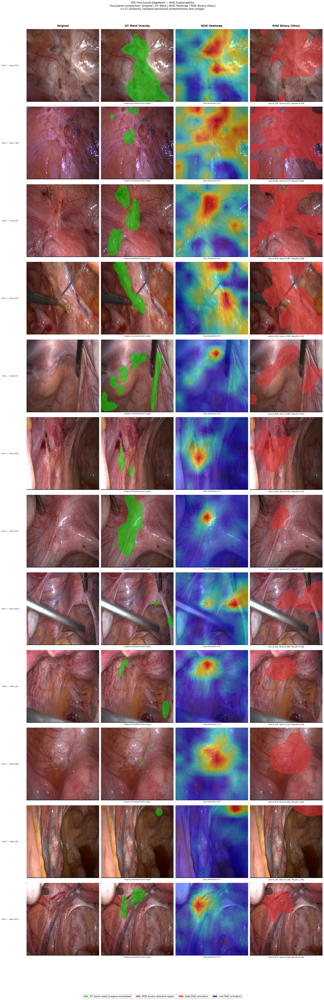


Saved: /content/drive/MyDrive/glenda_splits/edgenext_small_peritoneal/rise_12panel_qualitative.png


In [ ]:
# ── 12-panel RISE qualitative figure (SPE model) ─────────────────────────────
import random
import matplotlib.patches as mpatches

def generate_rise_viz_12(n_samples=12, seed=42):
    """
    Four-panel figure for 12 randomly sampled peritoneal annotated test images.
    Panels per row:
      1. Original laparoscopic image
      2. Original + GT mask overlay (green tint)
      3. RISE heatmap overlay
      4. RISE binary mask (Otsu) overlaid on original
    """
    # Collect all peritoneal annotated test samples across folds
    all_samples = []
    for fold_idx in range(5):
        fold_samples = get_peritoneal_test_samples(fold_idx).copy()
        fold_samples['fold'] = fold_idx + 1
        all_samples.append(fold_samples)

    all_df   = pd.concat(all_samples, ignore_index=True)
    selected = all_df.sample(n=min(n_samples, len(all_df)), random_state=seed).reset_index(drop=True)
    print(f"Selected {len(selected)} samples from folds: {selected['fold'].tolist()}")

    # Pre-generate RISE masks
    np.random.seed(seed)
    n_masks = 2000
    masks_v = np.zeros((n_masks, 320, 320), dtype=np.float32)
    for i in range(n_masks):
        m = np.random.binomial(1, 0.5, size=(8,8)).astype(np.float32)
        m = np.array(Image.fromarray(m).resize((320, 320), Image.BILINEAR))
        masks_v[i] = np.clip(m, 0, 1)
    print("RISE masks ready")

    norm_tf = T.Compose([T.ToTensor(), T.Normalize([0.5]*3, [0.5]*3)])

    fig, axes = plt.subplots(len(selected), 4, figsize=(22, len(selected) * 5.5))
    col_titles = [
        'Original', 'GT Mask Overlay', 'RISE Heatmap', 'RISE Binary (Otsu)'
    ]
    for ax, title in zip(axes[0], col_titles):
        ax.set_title(title, fontsize=13, fontweight='bold', pad=12)

    for row_i, (_, row) in enumerate(selected.iterrows()):
        fold_num       = int(row['fold'])
        tensor, img_np = preprocess_image(row['image_path'])
        img_np_f       = img_np.astype(np.float32) / 255.0

        # GT mask
        gt_mask         = parse_mask_to_binary(row['annot_path'])
        gt_mask_resized = np.array(
            Image.fromarray(gt_mask * 255).resize((320, 320), Image.NEAREST)
        ) // 255

        # Panel 2: GT overlay (green tint on lesion pixels)
        gt_overlay = img_np.copy().astype(np.float32)
        gt_overlay[gt_mask_resized == 1] = (
            gt_overlay[gt_mask_resized == 1] * 0.45 +
            np.array([0, 210, 0]) * 0.55
        )
        gt_overlay = np.clip(gt_overlay, 0, 255).astype(np.uint8)

        # RISE forward passes
        model = load_spe_model(fold_num)
        model.eval()
        scores = []
        for start in range(0, n_masks, 64):
            bm = masks_v[start:start+64]
            bi = [norm_tf(Image.fromarray(((img_np_f * m[:,:,None])*255).astype(np.uint8))) for m in bm]
            with torch.no_grad():
                probs = F.softmax(model(torch.stack(bi).to(device)), dim=1)[:,1].cpu().numpy()
            scores.extend(probs.tolist())

        scores    = np.array(scores)
        rise_map  = (scores[:,None,None] * masks_v).sum(0) / (scores.sum() + 1e-8)
        rise_norm = (rise_map - rise_map.min()) / (rise_map.max() - rise_map.min() + 1e-8)

        # Otsu threshold for binary panel
        try:
            otsu_t = float(threshold_otsu(rise_norm))
        except:
            otsu_t = 0.5
        binary_mask = (rise_norm >= otsu_t).astype(np.uint8)

        # Panel 3: RISE heatmap overlay
        heatmap_overlay = show_cam_on_image(img_np_f, rise_norm, use_rgb=True)

        # Panel 4: binary mask overlaid on original (red tint)
        binary_overlay = img_np.copy().astype(np.float32)
        binary_overlay[binary_mask == 1] = (
            binary_overlay[binary_mask == 1] * 0.45 +
            np.array([220, 50, 50]) * 0.55
        )
        binary_overlay = np.clip(binary_overlay, 0, 255).astype(np.uint8)

        # Compute metrics
        intersection = (binary_mask & gt_mask_resized).sum()
        union        = (binary_mask | gt_mask_resized).sum()
        iou          = intersection / (union + 1e-8)
        dice         = 2 * intersection / (binary_mask.sum() + gt_mask_resized.sum() + 1e-8)
        recall       = intersection / (gt_mask_resized.sum() + 1e-8)

        # Plot
        axes[row_i][0].imshow(img_np)
        axes[row_i][0].set_ylabel(
            f"Fold {fold_num}  |  {row['patient_id']}",
            fontsize=8, rotation=0, labelpad=80, va='center'
        )

        axes[row_i][1].imshow(gt_overlay)
        axes[row_i][1].set_xlabel('Surgeon-annotated lesion region', fontsize=8)

        axes[row_i][2].imshow(heatmap_overlay)
        axes[row_i][2].set_xlabel(
            f'Otsu threshold={otsu_t:.2f}', fontsize=8
        )

        axes[row_i][3].imshow(binary_overlay)
        axes[row_i][3].set_xlabel(
            f'IoU={iou:.3f}  Dice={dice:.3f}  Recall={recall:.3f}', fontsize=9
        )

        for ax in axes[row_i]:
            ax.set_xticks([]); ax.set_yticks([])
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)
            ax.spines['bottom'].set_visible(False)
            ax.spines['left'].set_visible(False)

        sys.stdout.write(
            f"\r  [{row_i+1}/{len(selected)}] Fold {fold_num} — "
            f"IoU={iou:.3f} Dice={dice:.3f} Recall={recall:.3f}"
        )
        sys.stdout.flush()

    # Legend
    legend_elements = [
        mpatches.Patch(facecolor='#00d200', alpha=0.7, label='GT lesion mask (surgeon-annotated)'),
        mpatches.Patch(facecolor='#dc3232', alpha=0.7, label='RISE binary attention region'),
        mpatches.Patch(facecolor='#ff4500', alpha=0.9, label='High RISE activation'),
        mpatches.Patch(facecolor='#00008b', alpha=0.7, label='Low RISE activation'),
    ]
    fig.legend(handles=legend_elements, loc='lower center',
               ncol=4, fontsize=11, bbox_to_anchor=(0.5, -0.01),
               frameon=True, edgecolor='gray')

    plt.suptitle(
        'SPE Fine-tuned EdgeNeXt — RISE Explainability\n'
        'Four-panel comparison: Original | GT Mask | RISE Heatmap | RISE Binary (Otsu)\n'
        f'n={len(selected)} randomly sampled peritoneal endometriosis test images',
        fontsize=13, y=1.01
    )
    plt.tight_layout(rect=[0, 0.03, 1, 1])

    save_path = spe_save_dir / 'rise_12panel_qualitative.png'
    plt.savefig(str(save_path), dpi=120, bbox_inches='tight')
    plt.show()
    sys.stdout.write(f"\nSaved: {save_path}\n")
    sys.stdout.flush()

generate_rise_viz_12(n_samples=12, seed=42)

##Additional Explainability Metric: Pointing Game

In [ ]:
#reinstalling new session
!pip install -q grad-cam

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 37.0 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
#GRAD-CAM++ + POINTING GAME
# ============================================================
import numpy as np
import torch
import torchvision.transforms as T
from PIL import Image
from pathlib import Path
import pandas as pd
import pickle
import timm
import sys
from pytorch_grad_cam import GradCAMPlusPlus
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
OUTPUT_DIR = Path('/content/drive/MyDrive/glenda_splits')

# -----------------------------
# 1. Pointing Game (No Threshold)
# -----------------------------
def pointing_game(pred_map: np.ndarray, gt_mask: np.ndarray) -> float:
    if gt_mask.sum() == 0:
        return 0.0
    max_idx = np.unravel_index(np.argmax(pred_map), pred_map.shape)
    return float(gt_mask[max_idx] == 1)

# -----------------------------
# 2. Utilities
# -----------------------------
COLOUR_PALETTE = [(0,0,0), (190,62,204), (93,89,254), (145,210,138), (238,236,50)]

eval_transforms = T.Compose([
    T.Resize((320, 320), interpolation=T.InterpolationMode.BICUBIC),
    T.ToTensor(),
    T.Normalize([0.5,0.5,0.5], [0.5,0.5,0.5])
])

def parse_mask_to_binary(annot_path):
    mask = np.array(Image.open(annot_path).convert('RGB'))
    binary = np.zeros(mask.shape[:2], dtype=np.uint8)
    for c in COLOUR_PALETTE[1:]:
        binary[np.all(mask == c, axis=-1)] = 1
    return binary

def preprocess_image(path):
    img = Image.open(path).convert('RGB')
    tensor = eval_transforms(img).unsqueeze(0).to(device)
    img_np = np.array(img.resize((320,320), Image.BICUBIC))
    return tensor, img_np

def get_target_layer(model):
    #Best layer we found from EdgeNeXt
    return [model.stages[3].blocks[2]]   #last_split_block

In [ ]:
# 3. Main Function
# -----------------------------
def run_gradcam_pointing_game(arch='edgenext_small',
                              model_subdir=None,
                              ckpt_pattern='fold{}_best.pt'):

    all_results = []

    if model_subdir is None:
        model_dir = OUTPUT_DIR / arch
    else:
        model_dir = OUTPUT_DIR / model_subdir

    with open(OUTPUT_DIR / 'splits.pkl', 'rb') as f:
        splits = pickle.load(f)

    for fold_idx in range(5):
        fold_num = fold_idx + 1
        ckpt_path = model_dir / ckpt_pattern.format(fold_num)

        if not ckpt_path.exists():
            print(f"Fold {fold_num}: checkpoint not found")
            continue

        model = timm.create_model('edgenext_small', pretrained=False, num_classes=2).to(device)
        model.load_state_dict(torch.load(ckpt_path, map_location=device))
        model.eval()

        test_df = splits[fold_idx]['test']
        annotated = test_df[(test_df['label']==1) & (test_df['has_annot']==True)].reset_index(drop=True)

        if len(annotated) == 0:
            continue

        print(f"\nFold {fold_num}/5 — {len(annotated)} annotated samples")

        cam = GradCAMPlusPlus(model=model, target_layers=get_target_layer(model))
        targets = [ClassifierOutputTarget(1)]

        fold_scores = []
        for idx, row in annotated.iterrows():
            tensor, _ = preprocess_image(row['image_path'])
            gt_mask = parse_mask_to_binary(row['annot_path'])
            gt_resized = np.array(Image.fromarray(gt_mask*255).resize((320,320), Image.NEAREST)) // 255

            grayscale_cam = cam(input_tensor=tensor, targets=targets)[0]
            cam_norm = (grayscale_cam - grayscale_cam.min()) / (grayscale_cam.max() - grayscale_cam.min() + 1e-8)

            pg = pointing_game(cam_norm, gt_resized)
            fold_scores.append(pg)

            if (idx + 1) % 30 == 0:
                print(f"  [{idx+1}/{len(annotated)}] Pointing Game = {pg:.3f}")

        mean_pg = np.mean(fold_scores)
        print(f"Fold {fold_num} Grad-CAM++ Pointing Game: {mean_pg:.4f}")

        for s in fold_scores:
            all_results.append({'fold': fold_num, 'pointing_game': float(s)})

    return pd.DataFrame(all_results)

In [ ]:
#4. Summary
# -----------------------------
def summarise_pg(df, title="Grad-CAM++ Pointing Game"):
    print(f"\n{'='*60}")
    print(title)
    print('='*60)
    for f in range(1,6):
        m = df[df['fold']==f]['pointing_game'].mean()
        print(f"Fold {f}: {m:.4f}")
    overall = df['pointing_game'].mean()
    std = df['pointing_game'].std()
    print(f"\nOverall Mean ± Std: {overall:.4f} ± {std:.4f}  (n={len(df)})")
    df.to_csv(OUTPUT_DIR / 'gradcam_pointing_game_results.csv', index=False)
    print("Saved: gradcam_pointing_game_results.csv")
    return overall, std

In [ ]:
#edgenextmodel
# ============================================================

print("\n" + "="*70)
print("GRAD-CAM++ + POINTING GAME — GENERAL EdgeNeXt")
print("="*70)
df_gen = run_gradcam_pointing_game(arch='edgenext_small', model_subdir=None, ckpt_pattern='fold{}_best.pt')
mean_gen, std_gen = summarise_pg(df_gen, "General EdgeNeXt — Grad-CAM++ Pointing Game")


GRAD-CAM++ + POINTING GAME — GENERAL EdgeNeXt

Fold 1/5 — 81 annotated samples
  [30/81] Pointing Game = 1.000
  [60/81] Pointing Game = 0.000
Fold 1 Grad-CAM++ Pointing Game: 0.2593

Fold 2/5 — 89 annotated samples
  [30/89] Pointing Game = 0.000
  [60/89] Pointing Game = 0.000
Fold 2 Grad-CAM++ Pointing Game: 0.2809

Fold 3/5 — 67 annotated samples
  [30/67] Pointing Game = 0.000
  [60/67] Pointing Game = 0.000
Fold 3 Grad-CAM++ Pointing Game: 0.3284

Fold 4/5 — 66 annotated samples
  [30/66] Pointing Game = 1.000
  [60/66] Pointing Game = 0.000
Fold 4 Grad-CAM++ Pointing Game: 0.3030

Fold 5/5 — 70 annotated samples
  [30/70] Pointing Game = 0.000
  [60/70] Pointing Game = 1.000
Fold 5 Grad-CAM++ Pointing Game: 0.3429

General EdgeNeXt — Grad-CAM++ Pointing Game
Fold 1: 0.2593
Fold 2: 0.2809
Fold 3: 0.3284
Fold 4: 0.3030
Fold 5: 0.3429

Overall Mean ± Std: 0.3003 ± 0.4590  (n=373)
Saved: gradcam_pointing_game_results.csv


In [ ]:
#fine-tuned SPE
print("\n" + "="*70)
print("GRAD-CAM++ + POINTING GAME — SPE (Peritoneal)")
print("="*70)
df_spe = run_gradcam_pointing_game(
    arch='edgenext_small_peritoneal',
    model_subdir='edgenext_small_peritoneal',
    ckpt_pattern='fold{}_peritoneal_best.pt'
)
mean_spe, std_spe = summarise_pg(df_spe, "SPE (Peritoneal) — Grad-CAM++ Pointing Game")


GRAD-CAM++ + POINTING GAME — SPE (Peritoneal)

Fold 1/5 — 81 annotated samples
  [30/81] Pointing Game = 1.000
  [60/81] Pointing Game = 0.000
Fold 1 Grad-CAM++ Pointing Game: 0.3086

Fold 2/5 — 89 annotated samples
  [30/89] Pointing Game = 0.000
  [60/89] Pointing Game = 0.000
Fold 2 Grad-CAM++ Pointing Game: 0.1910

Fold 3/5 — 67 annotated samples
  [30/67] Pointing Game = 0.000
  [60/67] Pointing Game = 0.000
Fold 3 Grad-CAM++ Pointing Game: 0.1343

Fold 4/5 — 66 annotated samples
  [30/66] Pointing Game = 1.000
  [60/66] Pointing Game = 0.000
Fold 4 Grad-CAM++ Pointing Game: 0.2727

Fold 5/5 — 70 annotated samples
  [30/70] Pointing Game = 0.000
  [60/70] Pointing Game = 0.000
Fold 5 Grad-CAM++ Pointing Game: 0.2143

SPE (Peritoneal) — Grad-CAM++ Pointing Game
Fold 1: 0.3086
Fold 2: 0.1910
Fold 3: 0.1343
Fold 4: 0.2727
Fold 5: 0.2143

Overall Mean ± Std: 0.2252 ± 0.4183  (n=373)
Saved: gradcam_pointing_game_results.csv


In [ ]:
#summary
print("\n" + "="*70)
print("FINAL RESULTS")
print("="*70)
print(f"General EdgeNeXt : {mean_gen:.4f} ± {std_gen:.4f}")
print(f"SPE (Peritoneal) : {mean_spe:.4f} ± {std_spe:.4f}")


FINAL RESULTS
General EdgeNeXt : 0.3003 ± 0.4590
SPE (Peritoneal) : 0.2252 ± 0.4183


##GRADCAM Explainability

In [ ]:
#matching zhu and elbattah, 2023
!pip install -q grad-cam

import pickle
import numpy as np
import torch
import torch.nn.functional as F
import torchvision.transforms as T
import timm
import sys
from pathlib import Path
from PIL import Image
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

device     = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
OUTPUT_DIR = Path('/content/drive/MyDrive/glenda_splits')

with open(OUTPUT_DIR / 'splits.pkl', 'rb') as f:
    splits = pickle.load(f)

COLOUR_PALETTE = [(0,0,0),(190,62,204),(93,89,254),(145,210,138),(238,236,50)]

def parse_mask_to_binary(annot_path):
    mask = np.array(Image.open(annot_path).convert('RGB'))
    binary = np.zeros(mask.shape[:2], dtype=np.uint8)
    for c in COLOUR_PALETTE[1:]:
        binary[np.all(mask == c, axis=-1)] = 1
    return binary

def get_annotated_samples_for_fold(fold_idx):
    test_df   = splits[fold_idx]['test']
    annotated = test_df[(test_df['label']==1) & (test_df['has_annot']==True)]
    return annotated.reset_index(drop=True)

def compute_alignment(pred_map_norm, gt_mask, threshold=0.3):
    binary       = (pred_map_norm >= threshold).astype(np.uint8)
    intersection = (binary & gt_mask).sum()
    union        = (binary | gt_mask).sum()
    iou          = intersection / (union + 1e-8)
    dice         = 2 * intersection / (binary.sum() + gt_mask.sum() + 1e-8)
    recall       = intersection / (gt_mask.sum() + 1e-8)
    return float(iou), float(dice), float(recall)

In [ ]:
#gradcam function
def run_gradcam_eval(arch, ckpt_pattern, model_subdir=None, threshold=0.3):
    """
    Run plain GradCAM across all 5 folds.
    Tests THREE resolutions to find which matches the paper:
      A) 320x320 (your current approach)
      B) original image resolution (what paper may have used)
      C) 320x320 heatmap vs original resolution mask
    """
    model_dir = OUTPUT_DIR / (model_subdir or arch)
    results_320, results_orig, results_mixed = [], [], []

    eval_tf_320 = T.Compose([
        T.Resize((320,320), interpolation=T.InterpolationMode.BICUBIC),
        T.ToTensor(),
        T.Normalize([0.5]*3, [0.5]*3)
    ])

    for fold_idx in range(5):
        fold_num = fold_idx + 1
        ckpt     = model_dir / ckpt_pattern.format(fold_num)
        model    = timm.create_model('edgenext_small', pretrained=False,
                                     num_classes=2).to(device)
        model.load_state_dict(torch.load(ckpt, map_location=device))
        model.eval()

        cam     = GradCAM(model=model, target_layers=[model.stages[-1]])
        targets = [ClassifierOutputTarget(1)]
        samples = get_annotated_samples_for_fold(fold_idx)

        fold_320, fold_orig, fold_mixed = [], [], []

        for row_i, (_, row) in enumerate(samples.iterrows()):
            img_orig = Image.open(row['image_path']).convert('RGB')
            orig_w, orig_h = img_orig.size   # e.g. 640x360

            # ── Approach A: everything at 320x320 ────────────────────────────
            tensor  = eval_tf_320(img_orig).unsqueeze(0).to(device)
            gc      = cam(input_tensor=tensor, targets=targets)[0]
            gc_norm = (gc - gc.min()) / (gc.max() - gc.min() + 1e-8)
            gt_mask = parse_mask_to_binary(row['annot_path'])
            gt_320  = np.array(
                Image.fromarray(gt_mask*255).resize((320,320), Image.NEAREST)
            ) // 255
            iou_a, dice_a, rec_a = compute_alignment(gc_norm, gt_320, threshold)
            fold_320.append({'iou': iou_a, 'dice': dice_a, 'recall': rec_a})

            # ── Approach B: heatmap upsampled to original resolution ──────────
            gc_orig = np.array(
                Image.fromarray((gc_norm*255).astype(np.uint8)).resize(
                    (orig_w, orig_h), Image.BILINEAR
                )
            ).astype(np.float32) / 255.0
            gt_orig = (gt_mask > 0).astype(np.uint8)   # already original res
            # make sure same shape
            if gc_orig.shape != gt_orig.shape:
                gc_orig = np.array(
                    Image.fromarray((gc_orig*255).astype(np.uint8)).resize(
                        (gt_orig.shape[1], gt_orig.shape[0]), Image.BILINEAR
                    )
                ).astype(np.float32) / 255.0
            binary_b     = (gc_orig >= threshold).astype(np.uint8)
            intersection = (binary_b & gt_orig).sum()
            union        = (binary_b | gt_orig).sum()
            iou_b        = intersection / (union + 1e-8)
            dice_b       = 2*intersection / (binary_b.sum() + gt_orig.sum() + 1e-8)
            rec_b        = intersection / (gt_orig.sum() + 1e-8)
            fold_orig.append({'iou': iou_b, 'dice': dice_b, 'recall': rec_b})

            # ── Approach C: relu=False (keep negative activations too) ────────
            # Re-run without relu
            cam_norelu = GradCAM(model=model, target_layers=[model.stages[-1]])
            gc_nr      = cam_norelu(input_tensor=tensor, targets=targets,
                                    aug_smooth=False, eigen_smooth=False)[0]
            # No relu clipping — use raw signed values, shift to 0-1
            gc_nr_norm = (gc_nr - gc_nr.min()) / (gc_nr.max() - gc_nr.min() + 1e-8)
            iou_c, dice_c, rec_c = compute_alignment(gc_nr_norm, gt_320, threshold)
            fold_mixed.append({'iou': iou_c, 'dice': dice_c, 'recall': rec_c})

            sys.stdout.write(
                f"\r  Fold {fold_num} [{row_i+1}/{len(samples)}] "
                f"A_dice={dice_a:.3f} B_dice={dice_b:.3f} C_dice={dice_c:.3f}"
            )
            sys.stdout.flush()

        def fold_mean(lst, k):
            return np.mean([r[k] for r in lst])

        sys.stdout.write(
            f"\n  Fold {fold_num} summary | "
            f"A(320x320): IoU={fold_mean(fold_320,'iou'):.4f} Dice={fold_mean(fold_320,'dice'):.4f} | "
            f"B(orig res): IoU={fold_mean(fold_orig,'iou'):.4f} Dice={fold_mean(fold_orig,'dice'):.4f} | "
            f"C(no relu clip): IoU={fold_mean(fold_mixed,'iou'):.4f} Dice={fold_mean(fold_mixed,'dice'):.4f}\n"
        )
        sys.stdout.flush()

        results_320.extend(fold_320)
        results_orig.extend(fold_orig)
        results_mixed.extend(fold_mixed)

    print(f"\n{'='*70}")
    print(f"  {arch} — GradCAM — All 373 Samples")
    print(f"{'='*70}")
    print(f"  {'Approach':<30} {'IoU':>8} {'Dice':>8} {'Recall':>8}")
    print(f"  {'-'*56}")
    for name, results in [
        ('A: 320x320 (current)',        results_320),
        ('B: original resolution',      results_orig),
        ('C: no relu clip',             results_mixed),
    ]:
        iou    = np.mean([r['iou']    for r in results])
        dice   = np.mean([r['dice']   for r in results])
        recall = np.mean([r['recall'] for r in results])
        print(f"  {name:<30} {iou:>8.4f} {dice:>8.4f} {recall:>8.4f}")

    return results_320, results_orig, results_mixed

In [ ]:
# Run on general EdgeNeXt
print("GENERAL EDGENEXT — GradCAM")
r320_gen, rorig_gen, rmix_gen = run_gradcam_eval(
    arch='edgenext_small',
    ckpt_pattern='fold{}_best.pt'
)

GENERAL EDGENEXT — GradCAM
  Fold 1 [81/81] A_dice=0.185 B_dice=0.185 C_dice=0.185
  Fold 1 summary | A(320x320): IoU=0.1035 Dice=0.1710 | B(orig res): IoU=0.1036 Dice=0.1710 | C(no relu clip): IoU=0.1035 Dice=0.1710
  Fold 2 [89/89] A_dice=0.062 B_dice=0.063 C_dice=0.062
  Fold 2 summary | A(320x320): IoU=0.1238 Dice=0.2007 | B(orig res): IoU=0.1238 Dice=0.2008 | C(no relu clip): IoU=0.1238 Dice=0.2007
  Fold 3 [67/67] A_dice=0.005 B_dice=0.005 C_dice=0.005
  Fold 3 summary | A(320x320): IoU=0.1685 Dice=0.2648 | B(orig res): IoU=0.1684 Dice=0.2648 | C(no relu clip): IoU=0.1685 Dice=0.2648
  Fold 4 [66/66] A_dice=0.098 B_dice=0.097 C_dice=0.098
  Fold 4 summary | A(320x320): IoU=0.1211 Dice=0.1952 | B(orig res): IoU=0.1214 Dice=0.1956 | C(no relu clip): IoU=0.1211 Dice=0.1952
  Fold 5 [70/70] A_dice=0.430 B_dice=0.433 C_dice=0.430
  Fold 5 summary | A(320x320): IoU=0.1303 Dice=0.2132 | B(orig res): IoU=0.1304 Dice=0.2133 | C(no relu clip): IoU=0.1303 Dice=0.2132

  edgenext_small — Gra

##Visualizations (ALL)

In [ ]:
#Install and mount
!pip install -q timm torchmetrics scikit-learn

from google.colab import drive
drive.mount('/content/drive')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 22.5 MB/s eta 0:00:00
Mounted at /content/drive


In [ ]:
#reloading everything
# ── Cell 2: Reload everything ─────────────────────────────────────────────────
import pickle, json, sys
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import timm
import torchvision.transforms as T
from torch.utils.data import Dataset, DataLoader
from pathlib import Path
from PIL import Image

device     = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
OUTPUT_DIR = Path('/content/drive/MyDrive/glenda_splits')

with open(OUTPUT_DIR / 'splits.pkl', 'rb') as f:
    splits = pickle.load(f)

NORM_MEAN = [0.5, 0.5, 0.5]
NORM_STD  = [0.5, 0.5, 0.5]

eval_transforms_320 = T.Compose([
    T.Resize((320, 320), interpolation=T.InterpolationMode.BICUBIC),
    T.ToTensor(),
    T.Normalize(mean=NORM_MEAN, std=NORM_STD),
])

eval_transforms_224 = T.Compose([
    T.Resize((224, 224), interpolation=T.InterpolationMode.BICUBIC),
    T.ToTensor(),
    T.Normalize(mean=NORM_MEAN, std=NORM_STD),
])

class GlendaDataset(Dataset):
    def __init__(self, df, transform=None):
        self.df        = df.reset_index(drop=True)
        self.transform = transform
    def __len__(self):
        return len(self.df)
    def __getitem__(self, idx):
        row   = self.df.iloc[idx]
        image = Image.open(row['image_path']).convert('RGB')
        label = int(row['label'])
        if self.transform:
            image = self.transform(image)
        return image, label

def build_model(arch, num_classes=2, pretrained=False):
    if arch == 'edgenext_small':
        return timm.create_model('edgenext_small', pretrained=pretrained, num_classes=num_classes)
    elif arch == 'resnet50':
        return timm.create_model('resnet50.a1_in1k', pretrained=pretrained, num_classes=num_classes)
    elif arch == 'efficientformerv2_s0':
        return timm.create_model('efficientformerv2_s0', pretrained=pretrained, num_classes=num_classes)
    else:
        raise ValueError(f"Unknown arch: {arch}")

def get_transforms(arch):
    return eval_transforms_224 if arch == 'efficientformerv2_s0' else eval_transforms_320

@torch.no_grad()
def get_all_probs_labels(arch, splits, ckpt_dir=None):
    """Load all 5 fold checkpoints and collect probs+labels across all test sets."""
    all_probs, all_labels = [], []
    fold_probs, fold_labels = [], []
    ckpt_dir = ckpt_dir or (OUTPUT_DIR / arch)
    tf = get_transforms(arch)

    for fold_idx in range(5):
        fold     = splits[fold_idx]
        test_ds  = GlendaDataset(fold['test'], transform=tf)
        loader   = DataLoader(test_ds, batch_size=32, shuffle=False,
                              num_workers=2, pin_memory=False)
        model    = build_model(arch).to(device)
        ckpt     = ckpt_dir / f'fold{fold_idx+1}_best.pt'
        model.load_state_dict(torch.load(ckpt, map_location=device))
        model.eval()

        fp, fl = [], []
        for imgs, labels in loader:
            imgs   = imgs.to(device)
            logits = model(imgs)
            probs  = F.softmax(logits, dim=1)[:, 1].cpu()
            fp.append(probs)
            fl.append(labels)

        fp = torch.cat(fp)
        fl = torch.cat(fl)
        fold_probs.append(fp)
        fold_labels.append(fl)
        all_probs.append(fp)
        all_labels.append(fl)
        sys.stdout.write(f"\r  {arch} fold {fold_idx+1}/5 loaded")
        sys.stdout.flush()

    sys.stdout.write("\n")
    return fold_probs, fold_labels, torch.cat(all_probs), torch.cat(all_labels)

print(f"Device: {device}")
print("Loading model outputs...")

#Load all three base models
fold_probs_en,  fold_labels_en,  all_probs_en,  all_labels_en  = get_all_probs_labels('edgenext_small',      splits)
fold_probs_rn,  fold_labels_rn,  all_probs_rn,  all_labels_rn  = get_all_probs_labels('resnet50',            splits)
fold_probs_eff, fold_labels_eff, all_probs_eff, all_labels_eff = get_all_probs_labels('efficientformerv2_s0', splits)
print("All base models loaded.")

Device: cuda
Loading model outputs...
  edgenext_small fold 5/5 loaded
  resnet50 fold 5/5 loaded
  efficientformerv2_s0 fold 5/5 loaded
All base models loaded.


In [ ]:
#load SPE-fine tuned model outputs
PERITONEAL_RGB = (190, 62, 204)

def has_peritoneal_lesion(annot_path):
    if annot_path is None or pd.isna(annot_path):
        return False
    try:
        mask = np.array(Image.open(annot_path).convert('RGB'))
        return bool(np.any(np.all(mask == PERITONEAL_RGB, axis=-1)))
    except:
        return False

# Build peritoneal splits
peritoneal_splits = []
for fold_idx, fold in enumerate(splits):
    new_fold = {}
    for split_name in ['train', 'val', 'test']:
        df = fold[split_name].copy()
        df['peritoneal'] = df.apply(
            lambda r: 1 if (r['label'] == 1 and has_peritoneal_lesion(r.get('annot_path')))
                      else (0 if r['label'] == 0 else -1), axis=1
        )
        df = df[df['peritoneal'] != -1].copy()
        df['peri_label'] = df['peritoneal']
        new_fold[split_name] = df.reset_index(drop=True)
    new_fold['fold'] = fold_idx
    peritoneal_splits.append(new_fold)

class PeritonealDataset(Dataset):
    def __init__(self, df, transform=None):
        self.df        = df.reset_index(drop=True)
        self.transform = transform
    def __len__(self):
        return len(self.df)
    def __getitem__(self, idx):
        row   = self.df.iloc[idx]
        image = Image.open(row['image_path']).convert('RGB')
        label = int(row['peri_label'])
        if self.transform:
            image = self.transform(image)
        return image, label

@torch.no_grad()
def get_spe_probs_labels(peritoneal_splits):
    all_fp, all_fl = [], []
    fold_probs, fold_labels = [], []
    spe_dir = OUTPUT_DIR / 'edgenext_small_peritoneal'

    for fold_idx in range(5):
        fold    = peritoneal_splits[fold_idx]
        test_ds = PeritonealDataset(fold['test'], transform=eval_transforms_320)
        loader  = DataLoader(test_ds, batch_size=32, shuffle=False,
                             num_workers=2, pin_memory=False)
        model   = timm.create_model('edgenext_small', pretrained=False, num_classes=2).to(device)
        ckpt    = spe_dir / f'fold{fold_idx+1}_peritoneal_best.pt'
        model.load_state_dict(torch.load(ckpt, map_location=device))
        model.eval()

        fp, fl = [], []
        for imgs, labels in loader:
            imgs   = imgs.to(device)
            probs  = F.softmax(model(imgs), dim=1)[:, 1].cpu()
            fp.append(probs)
            fl.append(labels)

        fp = torch.cat(fp)
        fl = torch.cat(fl)
        fold_probs.append(fp)
        fold_labels.append(fl)
        all_fp.append(fp)
        all_fl.append(fl)
        sys.stdout.write(f"\r  SPE fold {fold_idx+1}/5 loaded")
        sys.stdout.flush()

    sys.stdout.write("\n")
    return fold_probs, fold_labels, torch.cat(all_fp), torch.cat(all_fl)

fold_probs_spe, fold_labels_spe, all_probs_spe, all_labels_spe = get_spe_probs_labels(peritoneal_splits)
print("SPE model loaded.")

  SPE fold 5/5 loaded
SPE model loaded.


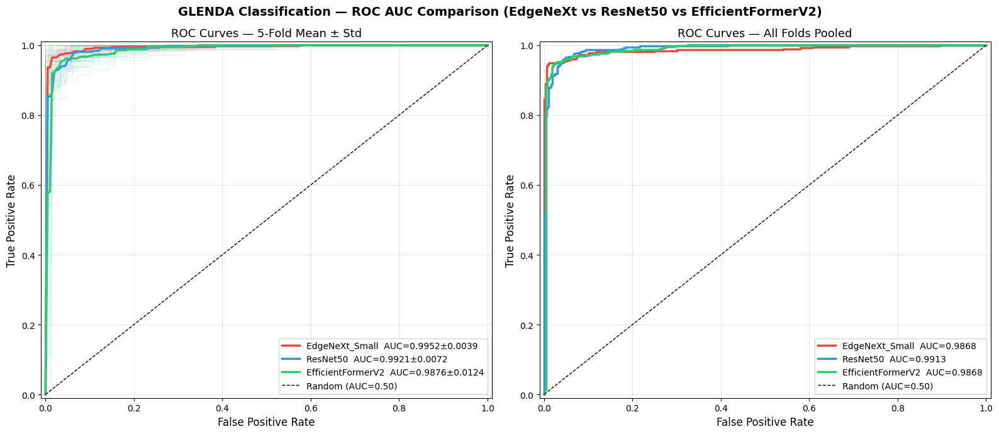

Saved: /content/drive/MyDrive/glenda_splits/roc_comparison_all_models.png


In [ ]:
#ROC AUC curves — all three base models comparison ─────────────────
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from sklearn.metrics import roc_curve, auc

def plot_roc_comparison(models_data: dict, title: str, save_path: str):
    """
    models_data: {
        'ModelName': (fold_probs_list, fold_labels_list, all_probs, all_labels)
    }
    Plots per-fold curves (faint) + mean curve (bold) for each model.
    """
    palette = {
        'EdgeNeXt_Small'     : '#e74c3c',
        'ResNet50'           : '#3498db',
        'EfficientFormerV2'  : '#2ecc71',
    }

    fig, axes = plt.subplots(1, 2, figsize=(16, 7))

    # ── Left: all folds per model (faint) + mean (bold) ──────────────────────
    ax = axes[0]
    for model_name, (fold_probs, fold_labels, _, _) in models_data.items():
        color   = palette[model_name]
        fold_aucs = []
        mean_fpr  = np.linspace(0, 1, 200)
        tprs      = []

        for fp, fl in zip(fold_probs, fold_labels):
            fpr, tpr, _ = roc_curve(fl.numpy(), fp.numpy())
            fold_auc    = auc(fpr, tpr)
            fold_aucs.append(fold_auc)
            ax.plot(fpr, tpr, color=color, alpha=0.15, linewidth=1)
            tprs.append(np.interp(mean_fpr, fpr, tpr))

        mean_tpr      = np.mean(tprs, axis=0)
        mean_tpr[0]   = 0.0
        mean_auc      = np.mean(fold_aucs)
        std_auc       = np.std(fold_aucs)
        ax.plot(mean_fpr, mean_tpr, color=color, linewidth=2.5,
                label=f'{model_name}  AUC={mean_auc:.4f}±{std_auc:.4f}')

        # Std band
        std_tpr  = np.std(tprs, axis=0)
        tpr_upper = np.minimum(mean_tpr + std_tpr, 1)
        tpr_lower = np.maximum(mean_tpr - std_tpr, 0)
        ax.fill_between(mean_fpr, tpr_lower, tpr_upper, color=color, alpha=0.08)

    ax.plot([0, 1], [0, 1], 'k--', linewidth=1, label='Random (AUC=0.50)')
    ax.set_xlim([-0.01, 1.01]); ax.set_ylim([-0.01, 1.01])
    ax.set_xlabel('False Positive Rate', fontsize=12)
    ax.set_ylabel('True Positive Rate', fontsize=12)
    ax.set_title('ROC Curves — 5-Fold Mean ± Std', fontsize=13)
    ax.legend(loc='lower right', fontsize=10)
    ax.grid(alpha=0.3)

    # ── Right: aggregated (all folds pooled) ──────────────────────────────────
    ax2 = axes[1]
    for model_name, (_, _, all_probs, all_labels) in models_data.items():
        color       = palette[model_name]
        fpr, tpr, _ = roc_curve(all_labels.numpy(), all_probs.numpy())
        roc_auc     = auc(fpr, tpr)
        ax2.plot(fpr, tpr, color=color, linewidth=2.5,
                 label=f'{model_name}  AUC={roc_auc:.4f}')

    ax2.plot([0, 1], [0, 1], 'k--', linewidth=1, label='Random (AUC=0.50)')
    ax2.set_xlim([-0.01, 1.01]); ax2.set_ylim([-0.01, 1.01])
    ax2.set_xlabel('False Positive Rate', fontsize=12)
    ax2.set_ylabel('True Positive Rate', fontsize=12)
    ax2.set_title('ROC Curves — All Folds Pooled', fontsize=13)
    ax2.legend(loc='lower right', fontsize=10)
    ax2.grid(alpha=0.3)

    plt.suptitle(title, fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()
    print(f"Saved: {save_path}")

models_data = {
    'EdgeNeXt_Small'    : (fold_probs_en,  fold_labels_en,  all_probs_en,  all_labels_en),
    'ResNet50'          : (fold_probs_rn,  fold_labels_rn,  all_probs_rn,  all_labels_rn),
    'EfficientFormerV2' : (fold_probs_eff, fold_labels_eff, all_probs_eff, all_labels_eff),
}

plot_roc_comparison(
    models_data,
    title='GLENDA Classification — ROC AUC Comparison (EdgeNeXt vs ResNet50 vs EfficientFormerV2)',
    save_path=str(OUTPUT_DIR / 'roc_comparison_all_models.png')
)


EdgeNeXt_Small
  Normal Acc  : 0.9947 ± 0.0066
  Patho Acc   : 0.9045 ± 0.0585
  AUC         : 0.9952 ± 0.0039
  Aggregated  → TP=338 FP=2 FN=35 TN=371

ResNet50
  Normal Acc  : 0.9884 ± 0.0176
  Patho Acc   : 0.8846 ± 0.0615
  AUC         : 0.9921 ± 0.0072
  Aggregated  → TP=328 FP=4 FN=45 TN=369

EfficientFormerV2
  Normal Acc  : 0.9926 ± 0.0094
  Patho Acc   : 0.9015 ± 0.0386
  AUC         : 0.9876 ± 0.0124
  Aggregated  → TP=335 FP=3 FN=38 TN=370


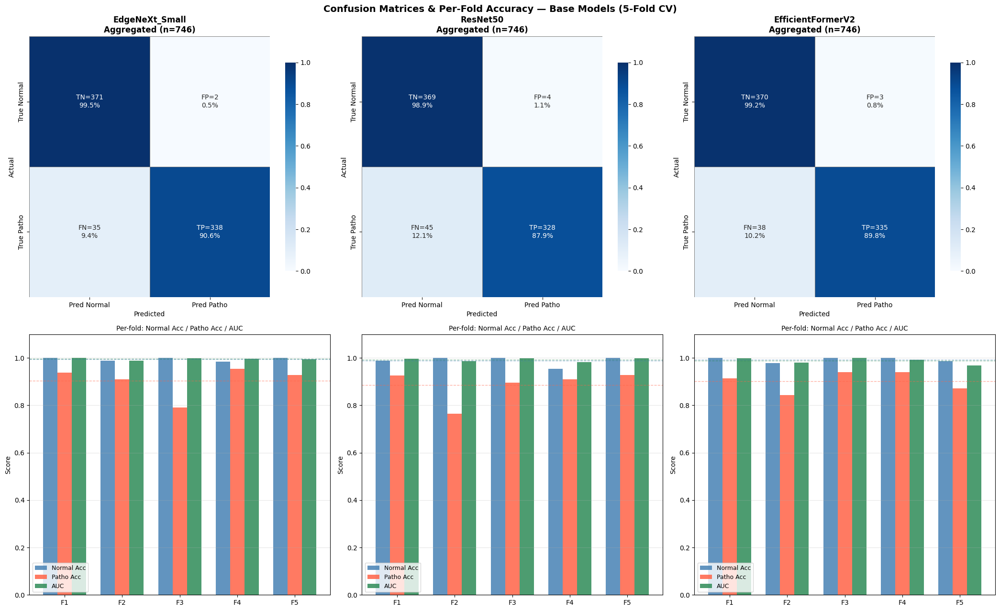


Saved: /content/drive/MyDrive/glenda_splits/confusion_matrices_base_models.png


In [ ]:
#Confusion matrix heatmaps — base models
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

def plot_confusion_matrices(models_data: dict, save_path: str):
    """
    One confusion matrix per model (aggregated across all 5 folds).
    Plus a 5-fold breakdown subplot per model.
    """
    n_models = len(models_data)
    fig, axes = plt.subplots(2, n_models, figsize=(7 * n_models, 13))

    for col, (model_name, (fold_probs, fold_labels, all_probs, all_labels)) in enumerate(models_data.items()):

        # ── Row 0: aggregated confusion matrix ───────────────────────────────
        preds_all = (all_probs >= 0.5).long().numpy()
        labels_all = all_labels.numpy()
        cm_all    = confusion_matrix(labels_all, preds_all)

        tn, fp, fn, tp = cm_all.ravel()
        total    = cm_all.sum()
        cm_norm  = cm_all.astype(float) / cm_all.sum(axis=1, keepdims=True)

        annot = np.array([
            [f"TN={tn}\n{cm_norm[0,0]:.1%}", f"FP={fp}\n{cm_norm[0,1]:.1%}"],
            [f"FN={fn}\n{cm_norm[1,0]:.1%}", f"TP={tp}\n{cm_norm[1,1]:.1%}"],
        ])

        sns.heatmap(
            cm_norm, annot=annot, fmt='', cmap='Blues',
            xticklabels=['Pred Normal', 'Pred Patho'],
            yticklabels=['True Normal', 'True Patho'],
            ax=axes[0][col], linewidths=0.5, linecolor='gray',
            vmin=0, vmax=1, cbar_kws={'shrink': 0.8}
        )
        axes[0][col].set_title(
            f'{model_name}\nAggregated (n={total})',
            fontsize=12, fontweight='bold'
        )
        axes[0][col].set_xlabel('Predicted', fontsize=10)
        axes[0][col].set_ylabel('Actual', fontsize=10)

        # ── Row 1: per-fold accuracy bars ─────────────────────────────────────
        fold_norm_acc, fold_path_acc, fold_auc_vals = [], [], []
        from sklearn.metrics import roc_auc_score

        for fp_t, fl_t in zip(fold_probs, fold_labels):
            preds = (fp_t >= 0.5).long().numpy()
            labs  = fl_t.numpy()
            cm_f  = confusion_matrix(labs, preds)
            tn_f, fp_f, fn_f, tp_f = cm_f.ravel()
            fold_norm_acc.append(tn_f / (tn_f + fp_f + 1e-8))
            fold_path_acc.append(tp_f / (tp_f + fn_f + 1e-8))
            fold_auc_vals.append(roc_auc_score(labs, fp_t.numpy()))

        x      = np.arange(5)
        width  = 0.25
        folds  = [f'F{i+1}' for i in range(5)]
        ax2    = axes[1][col]

        ax2.bar(x - width, fold_norm_acc, width, label='Normal Acc',
                color='steelblue', alpha=0.85)
        ax2.bar(x,          fold_path_acc, width, label='Patho Acc',
                color='tomato', alpha=0.85)
        ax2.bar(x + width,  fold_auc_vals, width, label='AUC',
                color='seagreen', alpha=0.85)

        ax2.axhline(np.mean(fold_norm_acc), color='steelblue',
                    linestyle='--', alpha=0.5, linewidth=1)
        ax2.axhline(np.mean(fold_path_acc), color='tomato',
                    linestyle='--', alpha=0.5, linewidth=1)
        ax2.axhline(np.mean(fold_auc_vals), color='seagreen',
                    linestyle='--', alpha=0.5, linewidth=1)

        ax2.set_xticks(x); ax2.set_xticklabels(folds)
        ax2.set_ylim(0, 1.1)
        ax2.set_title('Per-fold: Normal Acc / Patho Acc / AUC', fontsize=10)
        ax2.set_ylabel('Score')
        ax2.legend(fontsize=9)
        ax2.grid(axis='y', alpha=0.3)

        # Print summary
        print(f"\n{model_name}")
        print(f"  Normal Acc  : {np.mean(fold_norm_acc):.4f} ± {np.std(fold_norm_acc):.4f}")
        print(f"  Patho Acc   : {np.mean(fold_path_acc):.4f} ± {np.std(fold_path_acc):.4f}")
        print(f"  AUC         : {np.mean(fold_auc_vals):.4f} ± {np.std(fold_auc_vals):.4f}")
        print(f"  Aggregated  → TP={tp} FP={fp} FN={fn} TN={tn}")

    plt.suptitle('Confusion Matrices & Per-Fold Accuracy — Base Models (5-Fold CV)',
                 fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()
    print(f"\nSaved: {save_path}")

plot_confusion_matrices(
    models_data,
    save_path=str(OUTPUT_DIR / 'confusion_matrices_base_models.png')
)

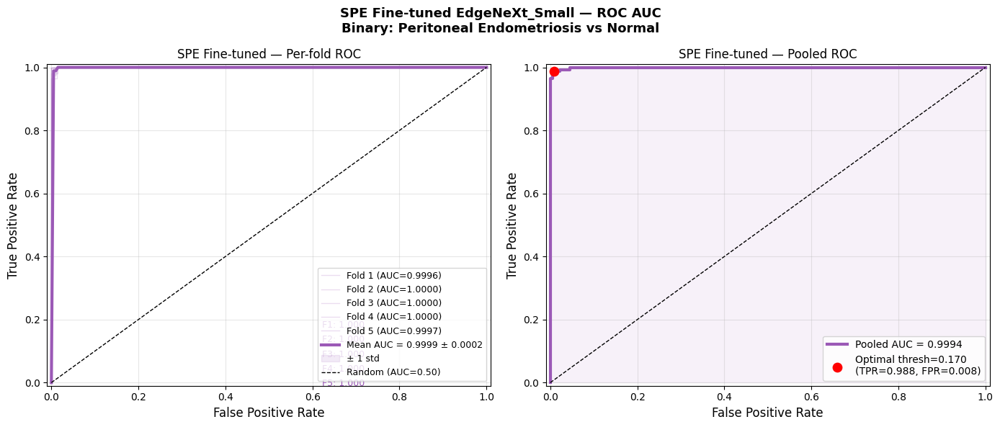

Saved: /content/drive/MyDrive/glenda_splits/edgenext_small_peritoneal/spe_roc_curve.png

SPE Model Summary:
  Fold 1 AUC: 0.9996
  Fold 2 AUC: 1.0000
  Fold 3 AUC: 1.0000
  Fold 4 AUC: 1.0000
  Fold 5 AUC: 0.9997
  Mean AUC    : 0.9999 ± 0.0002
  Pooled AUC  : 0.9994
  Optimal threshold (Youden's J): 0.1702


In [ ]:
#SPE fine-tuned model — ROC curve ─────────────────────────────────
from sklearn.metrics import roc_curve, auc, roc_auc_score

def plot_spe_roc(fold_probs, fold_labels, all_probs, all_labels, save_path):
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    color     = '#9b59b6'

    # ── Left: per-fold + mean ─────────────────────────────────────────────────
    ax        = axes[0]
    mean_fpr  = np.linspace(0, 1, 200)
    tprs, fold_aucs = [], []

    for i, (fp, fl) in enumerate(zip(fold_probs, fold_labels)):
        fpr, tpr, _ = roc_curve(fl.numpy(), fp.numpy())
        fold_auc    = auc(fpr, tpr)
        fold_aucs.append(fold_auc)
        ax.plot(fpr, tpr, color=color, alpha=0.2, linewidth=1,
                label=f'Fold {i+1} (AUC={fold_auc:.4f})' if i == 0 else f'Fold {i+1} (AUC={fold_auc:.4f})')
        tprs.append(np.interp(mean_fpr, fpr, tpr))

    mean_tpr    = np.mean(tprs, axis=0)
    mean_tpr[0] = 0.0
    std_tpr     = np.std(tprs, axis=0)
    mean_auc    = np.mean(fold_aucs)
    std_auc     = np.std(fold_aucs)

    ax.plot(mean_fpr, mean_tpr, color=color, linewidth=3,
            label=f'Mean AUC = {mean_auc:.4f} ± {std_auc:.4f}')
    ax.fill_between(mean_fpr,
                    np.maximum(mean_tpr - std_tpr, 0),
                    np.minimum(mean_tpr + std_tpr, 1),
                    color=color, alpha=0.12, label='± 1 std')
    ax.plot([0,1],[0,1],'k--',linewidth=1,label='Random (AUC=0.50)')

    # Annotate each fold AUC
    for i, a in enumerate(fold_aucs):
        ax.annotate(f'F{i+1}: {a:.3f}',
                    xy=(0.62, 0.18 - i * 0.045),
                    xycoords='axes fraction', fontsize=9, color=color)

    ax.set_xlim([-0.01,1.01]); ax.set_ylim([-0.01,1.01])
    ax.set_xlabel('False Positive Rate', fontsize=12)
    ax.set_ylabel('True Positive Rate', fontsize=12)
    ax.set_title('SPE Fine-tuned — Per-fold ROC', fontsize=12)
    ax.legend(loc='lower right', fontsize=9)
    ax.grid(alpha=0.3)

    # ── Right: pooled ─────────────────────────────────────────────────────────
    ax2         = axes[1]
    fpr, tpr, thresholds = roc_curve(all_labels.numpy(), all_probs.numpy())
    roc_auc     = auc(fpr, tpr)

    ax2.plot(fpr, tpr, color=color, linewidth=3,
             label=f'Pooled AUC = {roc_auc:.4f}')
    ax2.fill_between(fpr, 0, tpr, color=color, alpha=0.08)
    ax2.plot([0,1],[0,1],'k--',linewidth=1)

    # Mark optimal threshold (Youden's J)
    j_scores = tpr - fpr
    best_idx  = np.argmax(j_scores)
    best_thresh = thresholds[best_idx]
    ax2.scatter(fpr[best_idx], tpr[best_idx], color='red', s=80, zorder=5,
                label=f'Optimal thresh={best_thresh:.3f}\n(TPR={tpr[best_idx]:.3f}, FPR={fpr[best_idx]:.3f})')

    ax2.set_xlim([-0.01,1.01]); ax2.set_ylim([-0.01,1.01])
    ax2.set_xlabel('False Positive Rate', fontsize=12)
    ax2.set_ylabel('True Positive Rate', fontsize=12)
    ax2.set_title('SPE Fine-tuned — Pooled ROC', fontsize=12)
    ax2.legend(loc='lower right', fontsize=10)
    ax2.grid(alpha=0.3)

    plt.suptitle(
        'SPE Fine-tuned EdgeNeXt_Small — ROC AUC\n'
        'Binary: Peritoneal Endometriosis vs Normal',
        fontsize=13, fontweight='bold'
    )
    plt.tight_layout()
    plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()
    print(f"Saved: {save_path}")
    print(f"\nSPE Model Summary:")
    for i, a in enumerate(fold_aucs):
        print(f"  Fold {i+1} AUC: {a:.4f}")
    print(f"  Mean AUC    : {mean_auc:.4f} ± {std_auc:.4f}")
    print(f"  Pooled AUC  : {roc_auc:.4f}")
    print(f"  Optimal threshold (Youden's J): {best_thresh:.4f}")

plot_spe_roc(
    fold_probs_spe, fold_labels_spe,
    all_probs_spe,  all_labels_spe,
    save_path=str(OUTPUT_DIR / 'edgenext_small_peritoneal' / 'spe_roc_curve.png')
)


SPE Confusion Matrix Summary:
  Aggregated  → TP=251  FP=2  FN=6  TN=371
  Normal Acc  : 0.9941 ± 0.0072
  Patho Acc   : 0.9789 ± 0.0288
  Fold 1: TP=51 FP=0 FN=4 TN=81 | NormAcc=1.000 PathoAcc=0.927
  Fold 2: TP=59 FP=0 FN=2 TN=89 | NormAcc=1.000 PathoAcc=0.967
  Fold 3: TP=42 FP=0 FN=0 TN=67 | NormAcc=1.000 PathoAcc=1.000
  Fold 4: TP=48 FP=1 FN=0 TN=65 | NormAcc=0.985 PathoAcc=1.000
  Fold 5: TP=51 FP=1 FN=0 TN=69 | NormAcc=0.986 PathoAcc=1.000


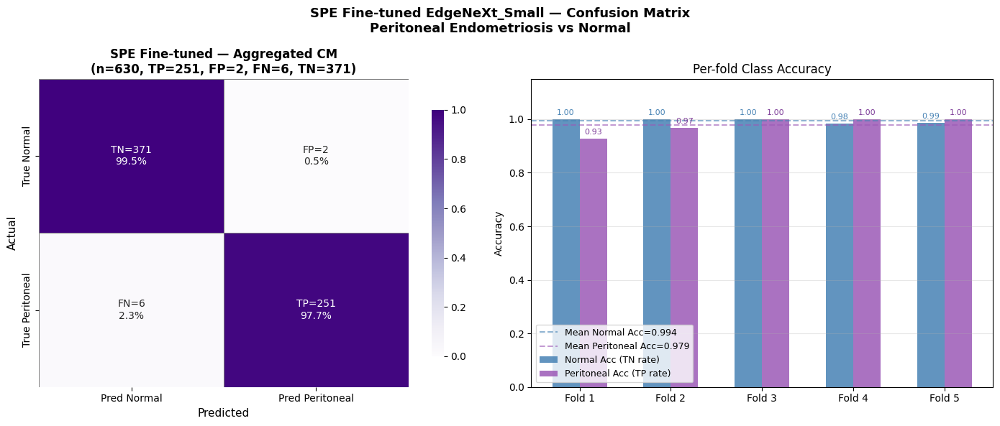

Saved: /content/drive/MyDrive/glenda_splits/edgenext_small_peritoneal/spe_confusion_matrix.png


In [ ]:
#SPE fine-tuned model — confusion matrix ──────────────────────────
import seaborn as sns
from sklearn.metrics import confusion_matrix

def plot_spe_confusion(fold_probs, fold_labels, all_probs, all_labels, save_path):
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    color     = '#9b59b6'

    # ── Left: aggregated ──────────────────────────────────────────────────────
    preds_all = (all_probs >= 0.5).long().numpy()
    cm_all    = confusion_matrix(all_labels.numpy(), preds_all)
    tn, fp, fn, tp = cm_all.ravel()
    cm_norm   = cm_all.astype(float) / cm_all.sum(axis=1, keepdims=True)

    annot = np.array([
        [f"TN={tn}\n{cm_norm[0,0]:.1%}", f"FP={fp}\n{cm_norm[0,1]:.1%}"],
        [f"FN={fn}\n{cm_norm[1,0]:.1%}", f"TP={tp}\n{cm_norm[1,1]:.1%}"],
    ])
    sns.heatmap(
        cm_norm, annot=annot, fmt='', cmap='Purples',
        xticklabels=['Pred Normal', 'Pred Peritoneal'],
        yticklabels=['True Normal', 'True Peritoneal'],
        ax=axes[0], linewidths=0.5, linecolor='gray',
        vmin=0, vmax=1, cbar_kws={'shrink': 0.8}
    )
    axes[0].set_title(
        f'SPE Fine-tuned — Aggregated CM\n'
        f'(n={cm_all.sum()}, TP={tp}, FP={fp}, FN={fn}, TN={tn})',
        fontsize=12, fontweight='bold'
    )
    axes[0].set_xlabel('Predicted', fontsize=11)
    axes[0].set_ylabel('Actual', fontsize=11)

    # ── Right: per-fold heatmap (5 rows × 4 cells) ────────────────────────────
    fold_cms = []
    for fp_t, fl_t in zip(fold_probs, fold_labels):
        preds = (fp_t >= 0.5).long().numpy()
        cm_f  = confusion_matrix(fl_t.numpy(), preds)
        fold_cms.append(cm_f.ravel())  # tn, fp, fn, tp

    fold_cms   = np.array(fold_cms, dtype=float)  # (5, 4)
    # Normalise each fold by its row sums
    fold_norm_acc = fold_cms[:, 0] / (fold_cms[:, 0] + fold_cms[:, 1] + 1e-8)  # normal acc
    fold_path_acc = fold_cms[:, 3] / (fold_cms[:, 3] + fold_cms[:, 2] + 1e-8)  # patho acc

    x     = np.arange(5)
    width = 0.3
    folds = [f'Fold {i+1}' for i in range(5)]

    axes[1].bar(x - width/2, fold_norm_acc, width,
                label='Normal Acc (TN rate)', color='steelblue', alpha=0.85)
    axes[1].bar(x + width/2, fold_path_acc, width,
                label='Peritoneal Acc (TP rate)', color='#9b59b6', alpha=0.85)

    axes[1].axhline(np.mean(fold_norm_acc), color='steelblue',
                    linestyle='--', alpha=0.6, linewidth=1.5,
                    label=f'Mean Normal Acc={np.mean(fold_norm_acc):.3f}')
    axes[1].axhline(np.mean(fold_path_acc), color='#9b59b6',
                    linestyle='--', alpha=0.6, linewidth=1.5,
                    label=f'Mean Peritoneal Acc={np.mean(fold_path_acc):.3f}')

    for i, (na, pa) in enumerate(zip(fold_norm_acc, fold_path_acc)):
        axes[1].text(i - width/2, na + 0.01, f'{na:.2f}',
                     ha='center', va='bottom', fontsize=8, color='steelblue')
        axes[1].text(i + width/2, pa + 0.01, f'{pa:.2f}',
                     ha='center', va='bottom', fontsize=8, color='#7d3c98')

    axes[1].set_xticks(x); axes[1].set_xticklabels(folds)
    axes[1].set_ylim(0, 1.15)
    axes[1].set_title('Per-fold Class Accuracy', fontsize=12)
    axes[1].set_ylabel('Accuracy')
    axes[1].legend(fontsize=9)
    axes[1].grid(axis='y', alpha=0.3)

    print(f"\nSPE Confusion Matrix Summary:")
    print(f"  Aggregated  → TP={tp}  FP={fp}  FN={fn}  TN={tn}")
    print(f"  Normal Acc  : {np.mean(fold_norm_acc):.4f} ± {np.std(fold_norm_acc):.4f}")
    print(f"  Patho Acc   : {np.mean(fold_path_acc):.4f} ± {np.std(fold_path_acc):.4f}")
    for i in range(5):
        tn_f, fp_f, fn_f, tp_f = fold_cms[i].astype(int)
        print(f"  Fold {i+1}: TP={tp_f} FP={fp_f} FN={fn_f} TN={tn_f} | "
              f"NormAcc={fold_norm_acc[i]:.3f} PathoAcc={fold_path_acc[i]:.3f}")

    plt.suptitle(
        'SPE Fine-tuned EdgeNeXt_Small — Confusion Matrix\n'
        'Peritoneal Endometriosis vs Normal',
        fontsize=13, fontweight='bold'
    )
    plt.tight_layout()
    plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()
    print(f"Saved: {save_path}")

plot_spe_confusion(
    fold_probs_spe, fold_labels_spe,
    all_probs_spe,  all_labels_spe,
    save_path=str(OUTPUT_DIR / 'edgenext_small_peritoneal' / 'spe_confusion_matrix.png')
)

##IMPROVING IOU AND DICE COEFFICIENT

In [1]:
#Install and mount
!pip install -q timm torchmetrics grad-cam
from google.colab import drive
drive.mount('/content/drive')

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 69.8 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 46.0 MB/s eta 0:00:00
Mounted at /content/drive


In [2]:
#Reload everything
import pickle, json, copy, sys
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.transforms as T
import timm
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchmetrics.classification import BinaryAUROC, BinaryF1Score, BinaryAccuracy

device     = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
OUTPUT_DIR = Path('/content/drive/MyDrive/glenda_splits')

with open(OUTPUT_DIR / 'splits.pkl', 'rb') as f:
    splits = pickle.load(f)

# Find best fold from previous run
with open(OUTPUT_DIR / 'edgenext_small' / 'summary.json') as f:
    summary = json.load(f)
best_fold_idx = int(np.argmax(summary['auc']['per_fold']))
best_fold_num = best_fold_idx + 1
print(f"Best fold: {best_fold_num}  AUC={summary['auc']['per_fold'][best_fold_idx]:.4f}")

TARGET_SIZE = (320, 320)
NORM_MEAN   = [0.5, 0.5, 0.5]
NORM_STD    = [0.5, 0.5, 0.5]

train_transforms = T.Compose([
    T.Resize(TARGET_SIZE, interpolation=T.InterpolationMode.BICUBIC),
    T.RandomHorizontalFlip(p=0.5),
    T.RandomRotation(degrees=10),
    T.ColorJitter(brightness=0.1, contrast=0.1),
    T.ToTensor(),
    T.Normalize(mean=NORM_MEAN, std=NORM_STD),
])
eval_transforms = T.Compose([
    T.Resize(TARGET_SIZE, interpolation=T.InterpolationMode.BICUBIC),
    T.ToTensor(),
    T.Normalize(mean=NORM_MEAN, std=NORM_STD),
])

class GlendaDataset(Dataset):
    def __init__(self, df, transform=None):
        self.df        = df.reset_index(drop=True)
        self.transform = transform
    def __len__(self):
        return len(self.df)
    def __getitem__(self, idx):
        row   = self.df.iloc[idx]
        image = Image.open(row['image_path']).convert('RGB')
        label = int(row['label'])
        if self.transform:
            image = self.transform(image)
        return image, label

print(f"Device: {device}")
print("Ready.")

Best fold: 1  AUC=0.9998
Device: cuda
Ready.


In [3]:
#Retrain best fold with class-weighted CrossEntropyLoss
BATCH_SIZE = 32
NUM_EPOCHS = 30
LR         = 1e-4
PATIENCE   = 7
SAVE_DIR   = OUTPUT_DIR / 'edgenext_small_weighted'
SAVE_DIR.mkdir(parents=True, exist_ok=True)

fold = splits[best_fold_idx]

# Compute inverse frequency class weights from training set
n_patho  = int(fold['train']['label'].sum())
n_normal = int((fold['train']['label'] == 0).sum())
n_total  = n_patho + n_normal

weight_normal = n_total / (2 * n_normal)
weight_patho  = n_total / (2 * n_patho)
class_weights = torch.tensor([weight_normal, weight_patho], dtype=torch.float).to(device)

print(f"Class weights — Normal: {weight_normal:.4f}  Pathological: {weight_patho:.4f}")
print(f"Pathological upweighted by: {weight_patho/weight_normal:.1f}x")

# Datasets
train_ds = GlendaDataset(fold['train'], transform=train_transforms)
val_ds   = GlendaDataset(fold['val'],   transform=eval_transforms)
test_ds  = GlendaDataset(fold['test'],  transform=eval_transforms)

PIN = torch.cuda.is_available()
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=2, pin_memory=PIN)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=2, pin_memory=PIN)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=2, pin_memory=PIN)

# Model
model     = timm.create_model('edgenext_small', pretrained=True, num_classes=2).to(device)
criterion = nn.CrossEntropyLoss(weight=class_weights)   # ← weighted loss
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=NUM_EPOCHS)

best_auc      = 0.0
best_weights  = None
patience_count = 0
history        = {'train_loss': [], 'val_loss': [], 'val_auc': [], 'val_acc': []}

for epoch in range(1, NUM_EPOCHS + 1):
    # ── Train ─────────────────────────────────────────────────────────────────
    model.train()
    tr_loss, tr_correct, tr_total = 0.0, 0, 0
    for batch_idx, (imgs, labels) in enumerate(train_loader):
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer.zero_grad()
        logits = model(imgs)
        loss   = criterion(logits, labels)
        loss.backward()
        optimizer.step()
        tr_loss    += loss.item() * imgs.size(0)
        tr_correct += (logits.argmax(1) == labels).sum().item()
        tr_total   += imgs.size(0)
        sys.stdout.write(
            f"\r  Epoch {epoch:02d}/{NUM_EPOCHS} | "
            f"Batch {batch_idx+1}/{len(train_loader)} | "
            f"loss={tr_loss/tr_total:.4f}"
        )
        sys.stdout.flush()

    tr_loss /= tr_total
    tr_acc   = tr_correct / tr_total

    # ── Validate ──────────────────────────────────────────────────────────────
    model.eval()
    vl_loss, vl_total = 0.0, 0
    all_probs, all_labels = [], []
    with torch.no_grad():
        for imgs, labels in val_loader:
            imgs, labels = imgs.to(device), labels.to(device)
            logits = model(imgs)
            loss   = criterion(logits, labels)
            probs  = F.softmax(logits, dim=1)[:, 1]
            vl_loss  += loss.item() * imgs.size(0)
            vl_total += imgs.size(0)
            all_probs.append(probs.cpu())
            all_labels.append(labels.cpu())

    vl_loss   /= vl_total
    all_probs  = torch.cat(all_probs)
    all_labels = torch.cat(all_labels)
    preds      = (all_probs >= 0.5).long()
    vl_auc     = BinaryAUROC()(all_probs, all_labels).item()
    vl_acc     = BinaryAccuracy()(preds, all_labels).item()
    vl_f1      = BinaryF1Score()(preds, all_labels).item()
    scheduler.step()

    history['train_loss'].append(tr_loss)
    history['val_loss'].append(vl_loss)
    history['val_auc'].append(vl_auc)
    history['val_acc'].append(vl_acc)

    improved = vl_auc > best_auc
    if improved:
        best_auc      = vl_auc
        best_weights  = copy.deepcopy(model.state_dict())
        patience_count = 0
        tag = '  ← best'
        torch.save(best_weights, SAVE_DIR / f'fold{best_fold_num}_weighted_best.pt')
    else:
        patience_count += 1
        tag = f'  (no improve {patience_count}/{PATIENCE})'

    sys.stdout.write(
        f"\r  Epoch {epoch:02d}/{NUM_EPOCHS} | "
        f"tr_loss={tr_loss:.4f} tr_acc={tr_acc:.4f} | "
        f"vl_loss={vl_loss:.4f} vl_acc={vl_acc:.4f} "
        f"vl_auc={vl_auc:.4f} vl_f1={vl_f1:.4f}{tag}\n"
    )
    sys.stdout.flush()

    if patience_count >= PATIENCE:
        sys.stdout.write(f"  Early stopping at epoch {epoch}\n")
        sys.stdout.flush()
        break

print(f"\nBest val AUC: {best_auc:.4f}")
print(f"Saved: {SAVE_DIR / f'fold{best_fold_num}_weighted_best.pt'}")

Class weights — Normal: 0.7521  Pathological: 1.4915
Pathological upweighted by: 2.0x


model.safetensors:   0%|          | 0.00/22.4M [00:00<?, ?B/s]

  Epoch 01/30 | tr_loss=0.5426 tr_acc=0.7603 | vl_loss=0.3308 vl_acc=0.9257 vl_auc=0.9716 vl_f1=0.8870  ← best
  Epoch 02/30 | tr_loss=0.2316 tr_acc=0.9387 | vl_loss=0.1619 vl_acc=0.9600 vl_auc=0.9854 vl_f1=0.9391  ← best
  Epoch 03/30 | tr_loss=0.1811 tr_acc=0.9401 | vl_loss=0.2681 vl_acc=0.8914 vl_auc=0.9814 vl_f1=0.8550  (no improve 1/7)
  Epoch 04/30 | tr_loss=0.1143 tr_acc=0.9672 | vl_loss=0.1231 vl_acc=0.9771 vl_auc=0.9899 vl_f1=0.9643  ← best
  Epoch 05/30 | tr_loss=0.0405 tr_acc=0.9914 | vl_loss=0.0973 vl_acc=0.9771 vl_auc=0.9911 vl_f1=0.9649  ← best
  Epoch 06/30 | tr_loss=0.0264 tr_acc=0.9957 | vl_loss=0.1010 vl_acc=0.9829 vl_auc=0.9952 vl_f1=0.9730  ← best
  Epoch 07/30 | tr_loss=0.0271 tr_acc=0.9943 | vl_loss=0.0773 vl_acc=0.9829 vl_auc=0.9936 vl_f1=0.9735  (no improve 1/7)
  Epoch 08/30 | tr_loss=0.0145 tr_acc=0.9986 | vl_loss=0.0930 vl_acc=0.9771 vl_auc=0.9927 vl_f1=0.9643  (no improve 2/7)
  Epoch 09/30 | tr_loss=0.0067 tr_acc=1.0000 | vl_loss=0.0715 vl_acc=0.9829 vl_auc

In [4]:
#Test set evaluation: weighted vs unweighted comparison
from torchmetrics.classification import (
    BinaryPrecision, BinaryRecall, BinaryConfusionMatrix
)

def eval_on_test(model, loader):
    model.eval()
    all_probs, all_labels = [], []
    with torch.no_grad():
        for imgs, labels in loader:
            imgs   = imgs.to(device)
            probs  = F.softmax(model(imgs), dim=1)[:, 1].cpu()
            all_probs.append(probs)
            all_labels.append(labels)
    all_probs  = torch.cat(all_probs)
    all_labels = torch.cat(all_labels)
    preds      = (all_probs >= 0.5).long()
    return {
        'auc'      : BinaryAUROC()(all_probs, all_labels).item(),
        'acc'      : BinaryAccuracy()(preds, all_labels).item(),
        'f1'       : BinaryF1Score()(preds, all_labels).item(),
        'precision': BinaryPrecision()(preds, all_labels).item(),
        'recall'   : BinaryRecall()(preds, all_labels).item(),
        'cm'       : BinaryConfusionMatrix()(preds, all_labels).numpy(),
    }

# Load original unweighted model
model_unweighted = timm.create_model('edgenext_small', pretrained=False, num_classes=2).to(device)
model_unweighted.load_state_dict(torch.load(
    OUTPUT_DIR / 'edgenext_small' / f'fold{best_fold_num}_best.pt', map_location=device
))

#Load new weighted model
model_weighted = timm.create_model('edgenext_small', pretrained=False, num_classes=2).to(device)
model_weighted.load_state_dict(best_weights)

metrics_uw = eval_on_test(model_unweighted, test_loader)
metrics_w  = eval_on_test(model_weighted,   test_loader)

print(f"\n{'='*65}")
print(f"  EdgeNeXt_Small Fold {best_fold_num} — Weighted vs Unweighted Loss")
print(f"{'='*65}")
print(f"  {'Metric':<12} {'Unweighted':>14} {'Weighted':>14} {'Δ':>10}")
print(f"  {'-'*52}")
for metric in ['auc', 'acc', 'f1', 'precision', 'recall']:
    uw  = metrics_uw[metric]
    w   = metrics_w[metric]
    delta = w - uw
    marker = ' ↑' if delta > 0.001 else (' ↓' if delta < -0.001 else '')
    print(f"  {metric:<12} {uw:>14.4f} {w:>14.4f} {delta:>+10.4f}{marker}")

print(f"\n  Confusion Matrix — Unweighted:\n{metrics_uw['cm']}")
print(f"\n  Confusion Matrix — Weighted:\n{metrics_w['cm']}")


  EdgeNeXt_Small Fold 1 — Weighted vs Unweighted Loss
  Metric           Unweighted       Weighted          Δ
  ----------------------------------------------------
  auc                  0.9998         0.9970    -0.0029 ↓
  acc                  0.9691         0.9506    -0.0185 ↓
  f1                   0.9682         0.9481    -0.0201 ↓
  precision            1.0000         1.0000    +0.0000
  recall               0.9383         0.9012    -0.0370 ↓

  Confusion Matrix — Unweighted:
[[81  0]
 [ 5 76]]

  Confusion Matrix — Weighted:
[[81  0]
 [ 8 73]]


In [5]:
#GradCAM++ comparison: weighted vs unweighted on all test samples
from pytorch_grad_cam import GradCAMPlusPlus
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

COLOUR_PALETTE = [(0,0,0),(190,62,204),(93,89,254),(145,210,138),(238,236,50)]

def parse_mask_to_binary(annot_path):
    mask   = np.array(Image.open(annot_path).convert('RGB'))
    binary = np.zeros(mask.shape[:2], dtype=np.uint8)
    for c in COLOUR_PALETTE[1:]:
        binary[np.all(mask == c, axis=-1)] = 1
    return binary

def compute_alignment(pred_map_norm, gt_mask, threshold=0.3):
    binary       = (pred_map_norm >= threshold).astype(np.uint8)
    intersection = (binary & gt_mask).sum()
    union        = (binary | gt_mask).sum()
    iou          = intersection / (union + 1e-8)
    dice         = 2 * intersection / (binary.sum() + gt_mask.sum() + 1e-8)
    recall       = intersection / (gt_mask.sum() + 1e-8)
    return float(iou), float(dice), float(recall)

eval_tf = T.Compose([
    T.Resize((320, 320), interpolation=T.InterpolationMode.BICUBIC),
    T.ToTensor(),
    T.Normalize([0.5]*3, [0.5]*3)
])

# Get annotated test samples for best fold
test_df   = splits[best_fold_idx]['test']
annotated = test_df[(test_df['label']==1) & (test_df['has_annot']==True)].reset_index(drop=True)
print(f"Annotated test samples: {len(annotated)}")

def run_gradcampp_eval(model, samples, label='model'):
    cam     = GradCAMPlusPlus(model=model, target_layers=[model.stages[-1]])
    targets = [ClassifierOutputTarget(1)]
    results = []
    for row_i, (_, row) in enumerate(samples.iterrows()):
        tensor  = eval_tf(Image.open(row['image_path']).convert('RGB')).unsqueeze(0).to(device)
        gt      = parse_mask_to_binary(row['annot_path'])
        gt_320  = np.array(Image.fromarray(gt*255).resize((320,320), Image.NEAREST)) // 255
        gc      = cam(input_tensor=tensor, targets=targets)[0]
        gc_norm = (gc - gc.min()) / (gc.max() - gc.min() + 1e-8)
        iou, dice, recall = compute_alignment(gc_norm, gt_320, threshold=0.3)
        results.append({'iou': iou, 'dice': dice, 'recall': recall})
        sys.stdout.write(
            f"\r  {label} [{row_i+1}/{len(samples)}] "
            f"IoU={iou:.3f} Dice={dice:.3f} Recall={recall:.3f}"
        )
        sys.stdout.flush()
    sys.stdout.write('\n')
    return results

print("\nRunning GradCAM++ — Unweighted model...")
results_uw = run_gradcampp_eval(model_unweighted, annotated, 'Unweighted')

print("\nRunning GradCAM++ — Weighted model...")
results_w  = run_gradcampp_eval(model_weighted, annotated, 'Weighted')

# Summary
print(f"\n{'='*60}")
print(f"  GradCAM++ XAI Alignment — Fold {best_fold_num} ({len(annotated)} samples)")
print(f"{'='*60}")
print(f"  {'Method':<25} {'IoU':>10} {'Dice':>10} {'Recall':>10}")
print(f"  {'-'*57}")
for label, results in [('Unweighted CE Loss', results_uw), ('Weighted CE Loss', results_w)]:
    iou    = np.mean([r['iou']    for r in results])
    dice   = np.mean([r['dice']   for r in results])
    recall = np.mean([r['recall'] for r in results])
    print(f"  {label:<25} {iou:>10.4f} {dice:>10.4f} {recall:>10.4f}")

print(f"\n  Paper target (Zhu & Elbattah): IoU=0.353  Dice=0.445")
iou_gap  = np.mean([r['iou']  for r in results_w]) - 0.353
dice_gap = np.mean([r['dice'] for r in results_w]) - 0.445
print(f"  Remaining gap after weighting: IoU={iou_gap:+.4f}  Dice={dice_gap:+.4f}")

Annotated test samples: 81

Running GradCAM++ — Unweighted model...
  Unweighted [81/81] IoU=0.095 Dice=0.174 Recall=0.872

Running GradCAM++ — Weighted model...
  Weighted [81/81] IoU=0.281 Dice=0.439 Recall=0.989

  GradCAM++ XAI Alignment — Fold 1 (81 samples)
  Method                           IoU       Dice     Recall
  ---------------------------------------------------------
  Unweighted CE Loss            0.1392     0.2167     0.6194
  Weighted CE Loss              0.0942     0.1515     0.4043

  Paper target (Zhu & Elbattah): IoU=0.353  Dice=0.445
  Remaining gap after weighting: IoU=-0.2588  Dice=-0.2935


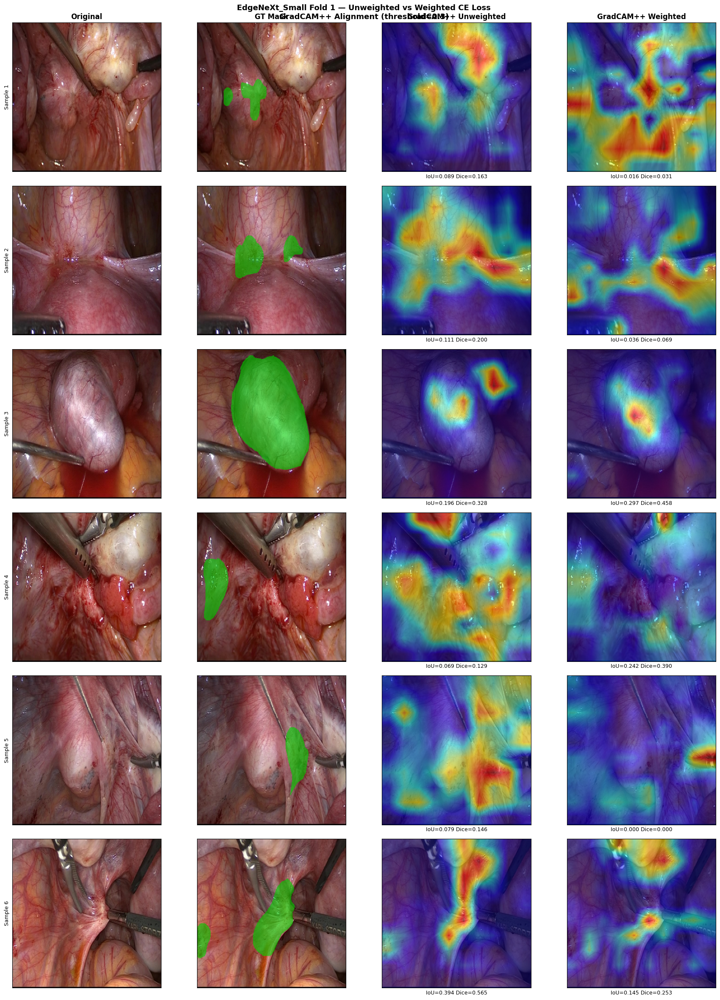

Saved: weighted_vs_unweighted_gradcam.png


In [6]:
#Visual comparison: 6 sample side-by-side
import matplotlib.pyplot as plt

sample6  = annotated.sample(6, random_state=42).reset_index(drop=True)
cam_uw   = GradCAMPlusPlus(model=model_unweighted, target_layers=[model_unweighted.stages[-1]])
cam_w    = GradCAMPlusPlus(model=model_weighted,   target_layers=[model_weighted.stages[-1]])
targets  = [ClassifierOutputTarget(1)]

fig, axes = plt.subplots(6, 4, figsize=(18, 6*4))
col_titles = ['Original', 'GT Mask', 'GradCAM++ Unweighted', 'GradCAM++ Weighted']
for ax, title in zip(axes[0], col_titles):
    ax.set_title(title, fontsize=12, fontweight='bold')

for row_i, (_, row) in enumerate(sample6.iterrows()):
    img_pil = Image.open(row['image_path']).convert('RGB')
    img_np  = np.array(img_pil.resize((320,320), Image.BICUBIC))
    img_f   = img_np.astype(np.float32) / 255.0
    tensor  = eval_tf(img_pil).unsqueeze(0).to(device)

    gt      = parse_mask_to_binary(row['annot_path'])
    gt_320  = np.array(Image.fromarray(gt*255).resize((320,320), Image.NEAREST)) // 255

    # GT overlay
    gt_overlay = img_np.copy().astype(np.float32)
    gt_overlay[gt_320==1] = gt_overlay[gt_320==1]*0.4 + np.array([0,210,0])*0.6
    gt_overlay = np.clip(gt_overlay,0,255).astype(np.uint8)

    # Unweighted CAM
    gc_uw      = cam_uw(input_tensor=tensor, targets=targets)[0]
    gc_uw_norm = (gc_uw - gc_uw.min()) / (gc_uw.max() - gc_uw.min() + 1e-8)
    ov_uw      = show_cam_on_image(img_f, gc_uw_norm, use_rgb=True)
    iou_uw, dice_uw, _ = compute_alignment(gc_uw_norm, gt_320)

    # Weighted CAM
    gc_w      = cam_w(input_tensor=tensor, targets=targets)[0]
    gc_w_norm = (gc_w - gc_w.min()) / (gc_w.max() - gc_w.min() + 1e-8)
    ov_w      = show_cam_on_image(img_f, gc_w_norm, use_rgb=True)
    iou_w, dice_w, _ = compute_alignment(gc_w_norm, gt_320)

    axes[row_i][0].imshow(img_np)
    axes[row_i][0].set_ylabel(f"Sample {row_i+1}", fontsize=9)
    axes[row_i][1].imshow(gt_overlay)
    axes[row_i][2].imshow(ov_uw)
    axes[row_i][2].set_xlabel(f'IoU={iou_uw:.3f} Dice={dice_uw:.3f}', fontsize=9)
    axes[row_i][3].imshow(ov_w)
    axes[row_i][3].set_xlabel(f'IoU={iou_w:.3f} Dice={dice_w:.3f}', fontsize=9)

    for ax in axes[row_i]:
        ax.set_xticks([]); ax.set_yticks([])

plt.suptitle(
    f'EdgeNeXt_Small Fold {best_fold_num} — '
    f'Unweighted vs Weighted CE Loss\nGradCAM++ Alignment (threshold=0.3)',
    fontsize=13, fontweight='bold'
)
plt.tight_layout()
plt.savefig(str(SAVE_DIR / 'weighted_vs_unweighted_gradcam.png'), dpi=120, bbox_inches='tight')
plt.show()
print(f"Saved: weighted_vs_unweighted_gradcam.png")